# Analyzing DDM Parameters for SJ Task
**List of contents:**\
1- General\
2- Prior response \
3- Prior stimulus\
4- Plot statistical results

In [1]:
library(broom)
library(mosaic)
library(glue)
library(patchwork)
library(scam)
library(tidyverse)
library(readxl)
library(rstatix)
library(ggpubr)
library(writexl)
library(dplyr)
library(ggbeeswarm)

Warning message:
"package 'mosaic' was built under R version 4.4.2"
Registered S3 method overwritten by 'mosaic':
  method                           from   
  fortify.SpatialPolygonsDataFrame ggplot2


The 'mosaic' package masks several functions from core packages in order to add 
additional features.  The original behavior of these functions should not be affected by this.


Attaching package: 'mosaic'


The following objects are masked from 'package:dplyr':

    count, do, tally


The following object is masked from 'package:Matrix':

    mean


The following object is masked from 'package:ggplot2':

    stat


The following objects are masked from 'package:stats':

    binom.test, cor, cor.test, cov, fivenum, IQR, median, prop.test,
    quantile, sd, t.test, var


The following objects are masked from 'package:base':

    max, mean, min, prod, range, sample, sum


Warning message:
"package 'patchwork' was built under R version 4.4.3"
Warning message:
"package 'scam' was built under

###############################################################\
###############################################################
# 1- General
**List of contents:**\
1-1 Testing change in relative starting point across SOA \
1-2 Testing change in signal to noise ratio across SOA\
1-3 Calculating sensory and decisional bias\
1-4 Testing the proximity of the PSS to one side

In [2]:
df_resp <- read_xlsx("files/SJ_general_DDM_parameters.xlsx")

# Rename first columns for clarity
colnames(df_resp)[1] <- "ID"
colnames(df_resp)[2] <- "SOA"

# ---------------------------------------------------------
# Compute Signal-to-Noise Ratio (SNR)
# SNR = drift rate (v) / noise (σ)
# This quantity reflects the quality of sensory evidence
# accumulation and is used as an index of sensory bias.
# ---------------------------------------------------------
df_resp$snr <- df_resp$drift / df_resp$noise

df_resp <- df_resp %>% arrange(ID, SOA)

###############################################################
## 1-1 Testing change in relative starting point across SOA

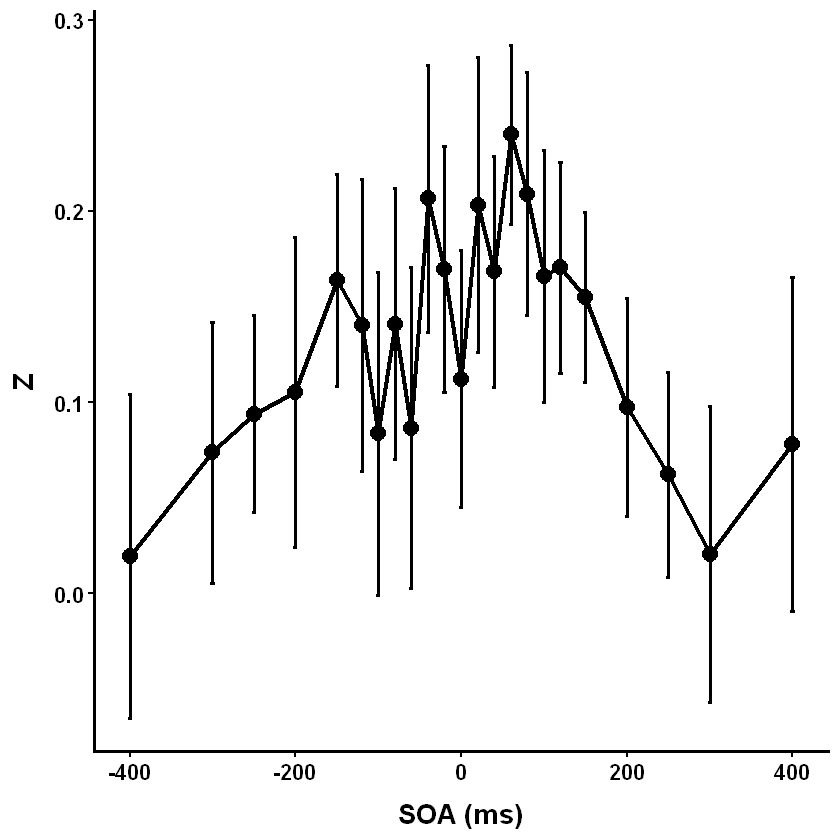

In [3]:
# =========================================================
# Visualize how relative starting point varies as a function of SOA for SJ task.
# =========================================================

# 1. Calculate summary statistics (Mean and SEM)
summary_resp <- df_resp %>%
  group_by(SOA) %>%
  summarise(
    mean_z = mean(Z, na.rm = TRUE),
    se_z = sd(Z, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

# 2. Create the plot with enhanced visibility for publication
p_resp <- ggplot(summary_resp,
                 aes(x = SOA, y = mean_z)) +
  # Increase line thickness for better visibility
  geom_line(linewidth = 1.2) +
  # Increase point size for better visibility
  geom_point(size = 4) +
  # Make error bars thicker and more visible
  geom_errorbar(aes(ymin = mean_z - se_z,
                    ymax = mean_z + se_z),
                width = 5, linewidth = 1) +
  # Define axis labels and legend title (No figure title)
  labs(
    x = "SOA (ms)",
    y = "Z"
  ) +
  # Use the same professional color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  # Use a clean and consistent theme across all figures
  theme_classic(base_size = 14) +
  theme(
    # Bold and enlarge axis titles
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    # Bold and enlarge axis tick labels
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    # Bold and enlarge legend title and legend text
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    # Keep legend placement consistent across all figures
    legend.position = "top",
    # Make axis lines clearly visible
    axis.line = element_line(linewidth = 1)
  )

# 3. Display the plot
print(p_resp)

In [5]:
friedman.test(
  Z ~ SOA | ID,
  data = df_resp
)


	Friedman rank sum test

data:  Z and SOA and ID
Friedman chi-squared = 18.978, df = 22, p-value = 0.6467


###############################################################
## 1-2 Testing change in signal to noise ratio across SOA

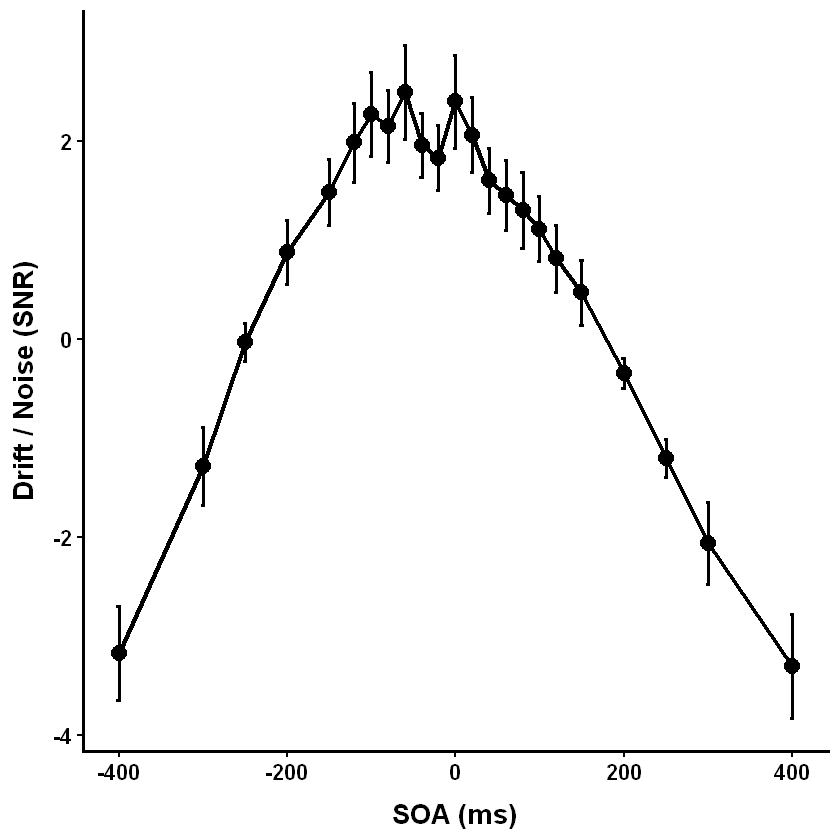

In [6]:
# =========================================================
# Visualize how sensory evidence varies as a function of SOA for SJ task.
# =========================================================

# 1. Calculate summary statistics (Mean and SEM)
summary_resp <- df_resp %>%
  group_by(SOA) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

# 2. Create the plot with enhanced visibility for publication
p_resp <- ggplot(summary_resp,
                 aes(x = SOA, y = mean_snr)) +
  # Increase line thickness for better visibility
  geom_line(linewidth = 1.2) +
  # Increase point size for better visibility
  geom_point(size = 4) +
  # Make error bars thicker and more visible
  geom_errorbar(aes(ymin = mean_snr - se_snr,
                    ymax = mean_snr + se_snr),
                width = 5, linewidth = 1) +
  # Define axis labels and legend title (No figure title)
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)"
  ) +
  # Use the same professional color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  # Use a clean and consistent theme across all figures
  theme_classic(base_size = 14) +
  theme(
    # Bold and enlarge axis titles
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    # Bold and enlarge axis tick labels
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    # Bold and enlarge legend title and legend text
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    # Keep legend placement consistent across all figures
    legend.position = "top",
    # Make axis lines clearly visible
    axis.line = element_line(linewidth = 1)
  )

# 3. Display the plot
print(p_resp)

In [7]:
friedman.test(
  snr ~ SOA | ID,
  data = df_resp
)


	Friedman rank sum test

data:  snr and SOA and ID
Friedman chi-squared = 288.03, df = 22, p-value < 2.2e-16


###############################################################
## 1-3 Calculating sensory and decisional bias

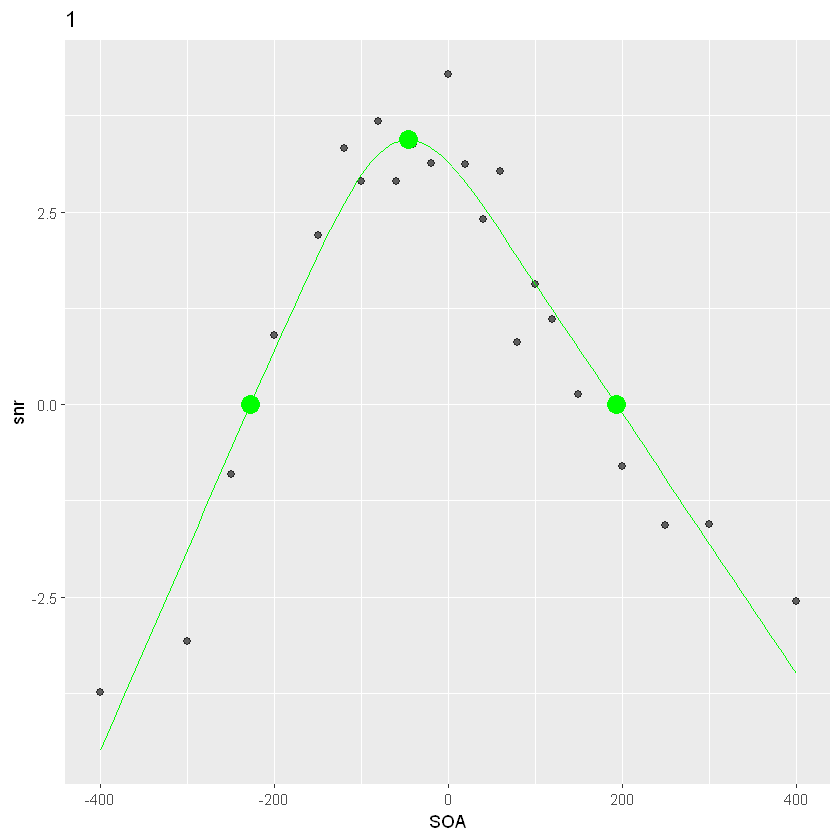

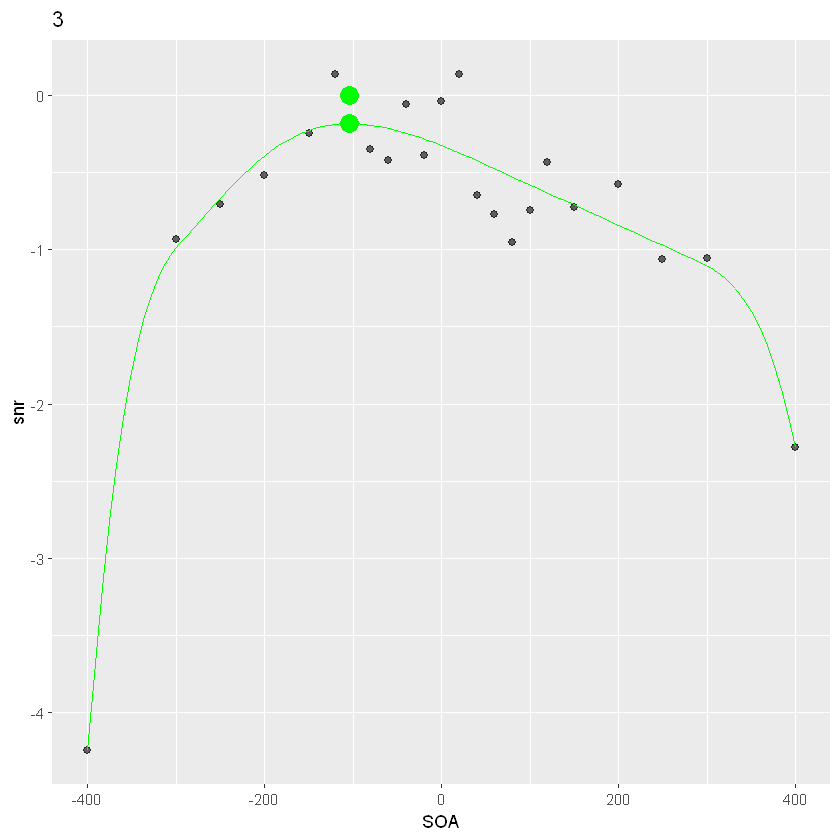

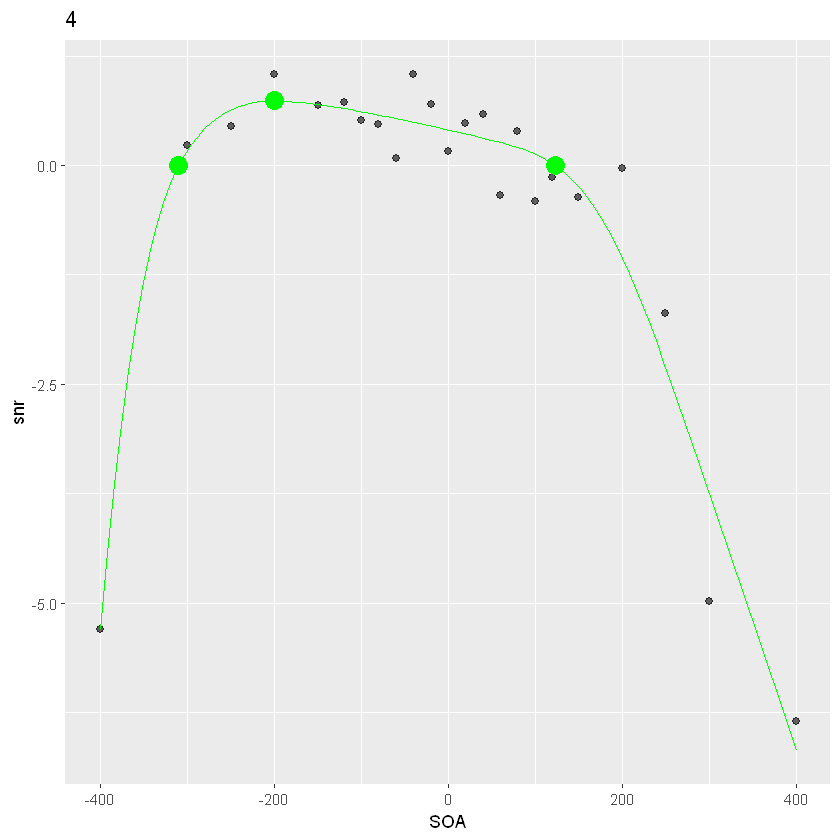

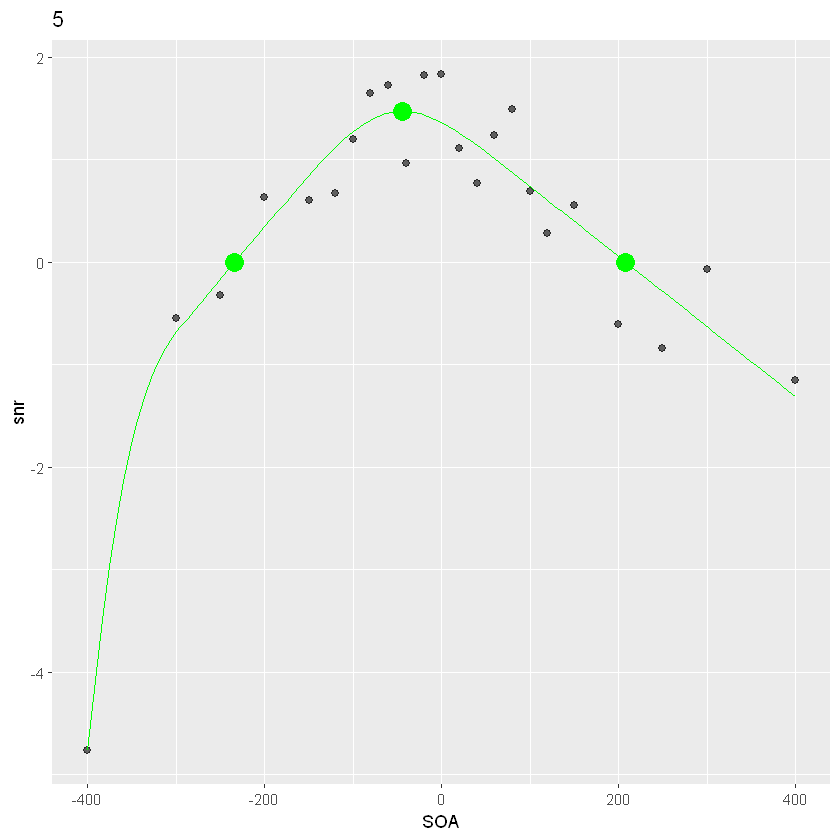

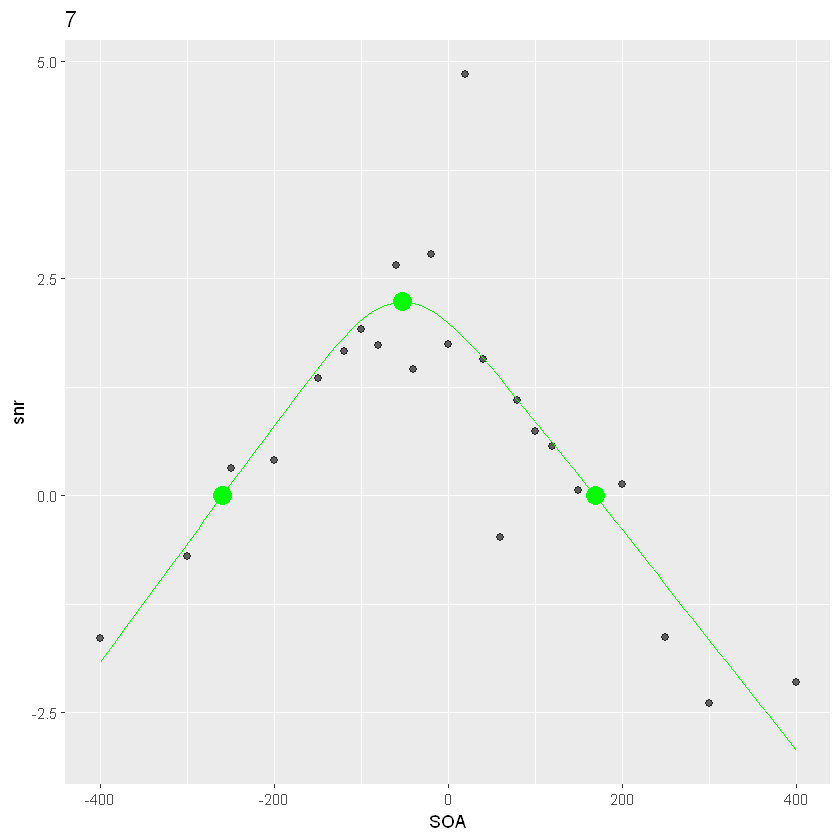

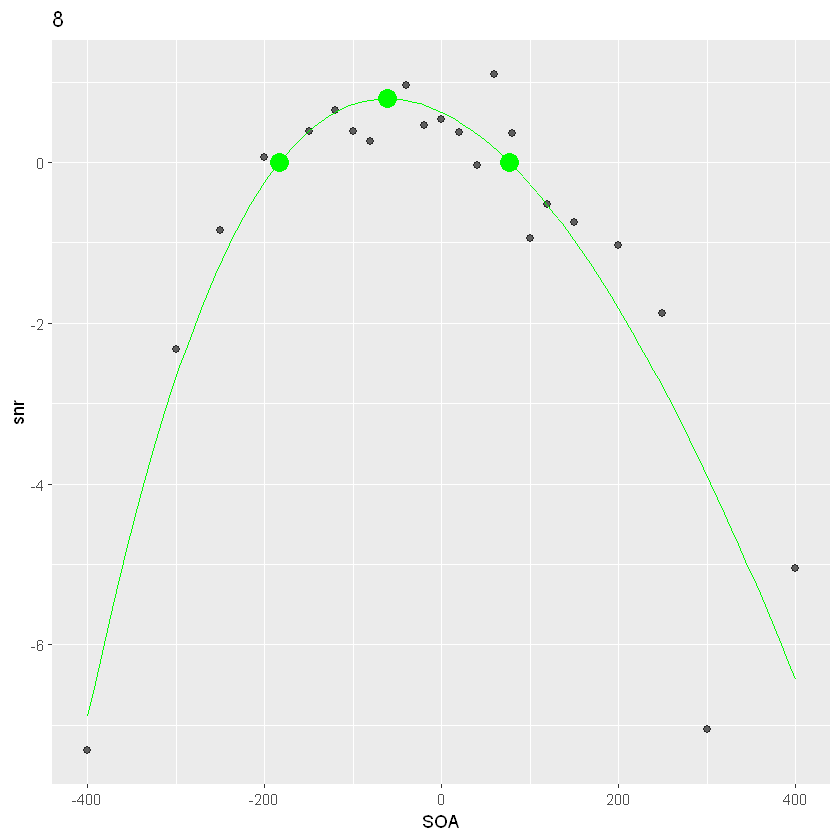

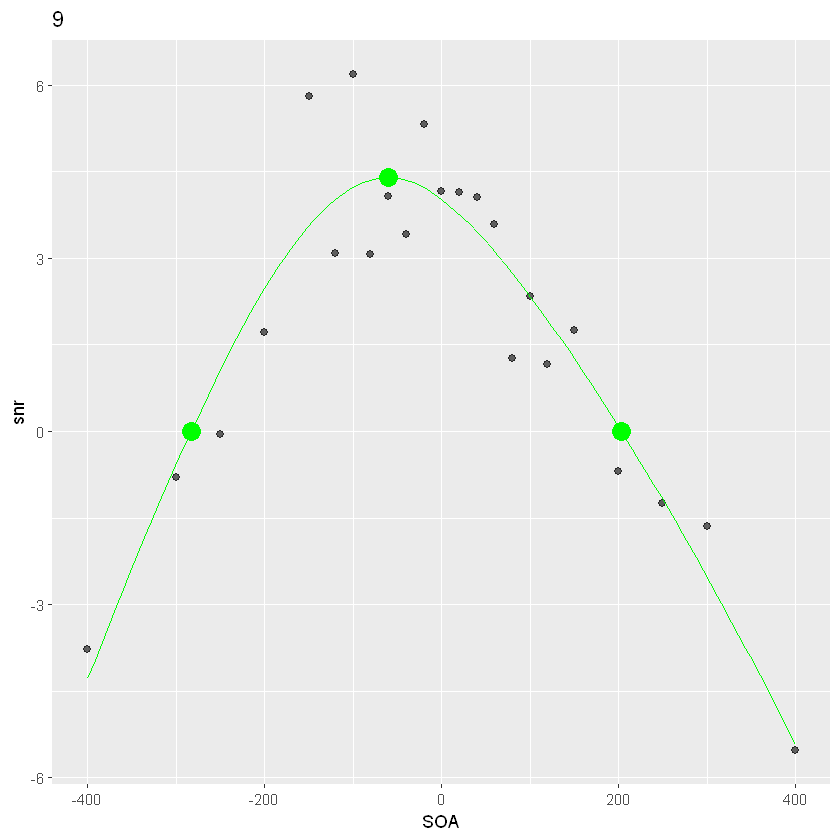

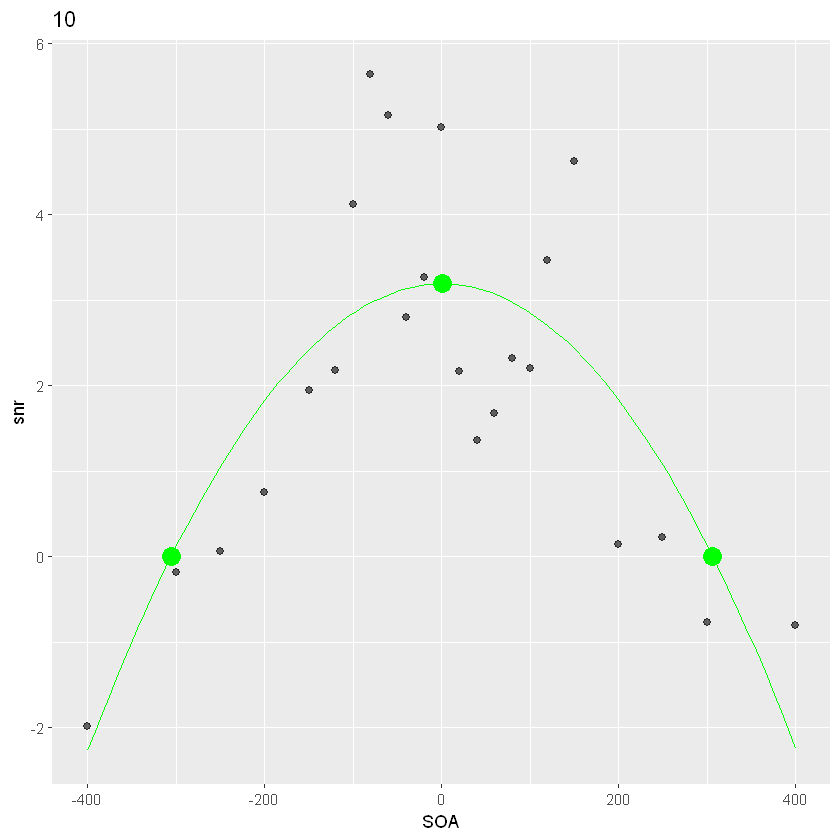

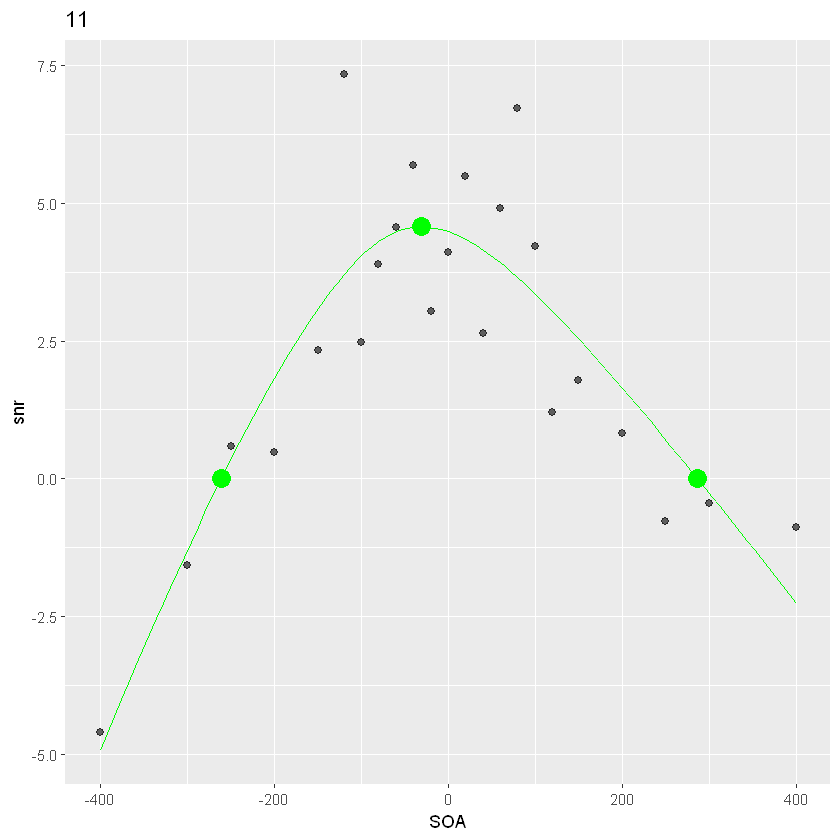

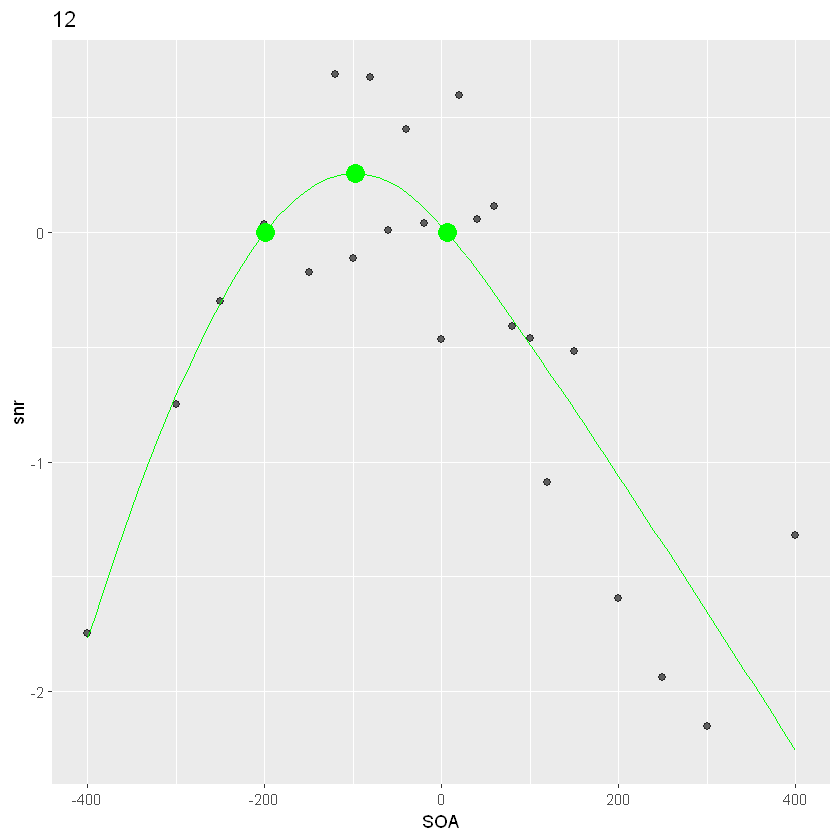

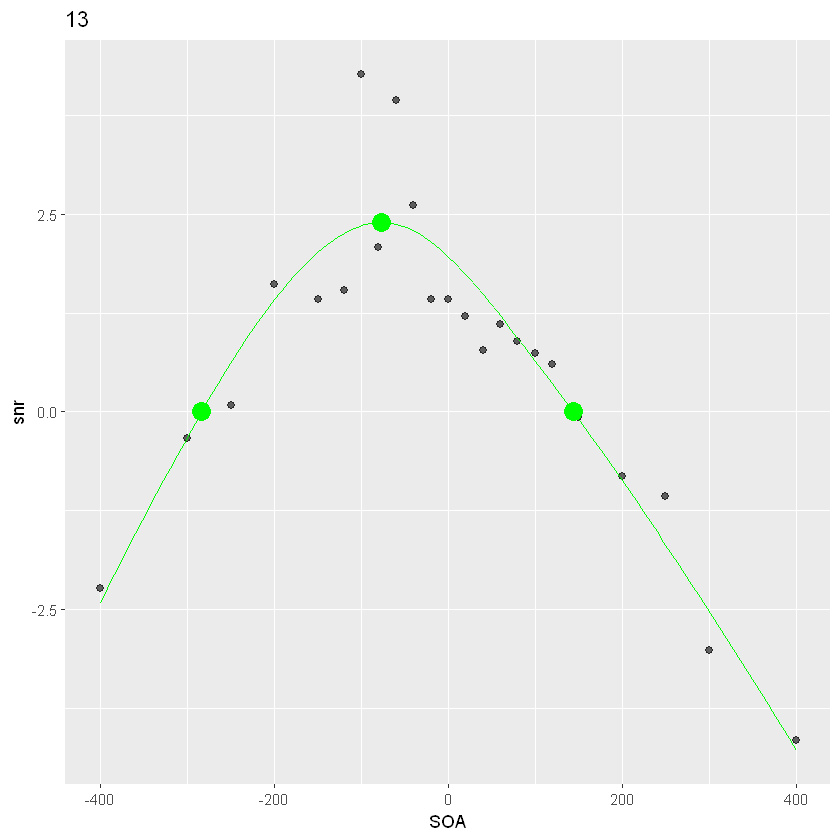

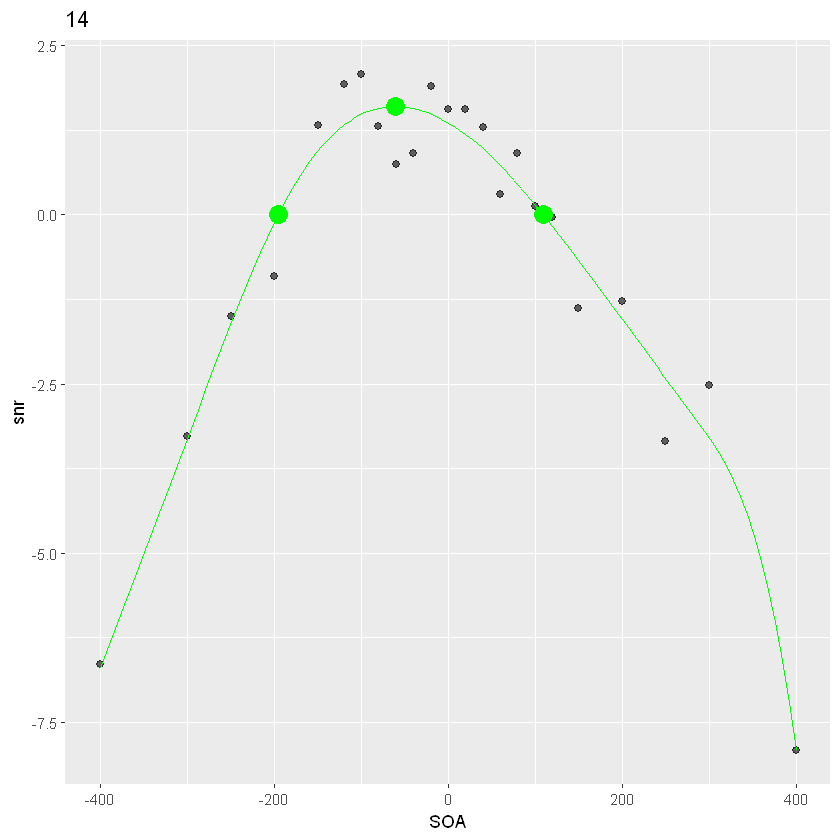

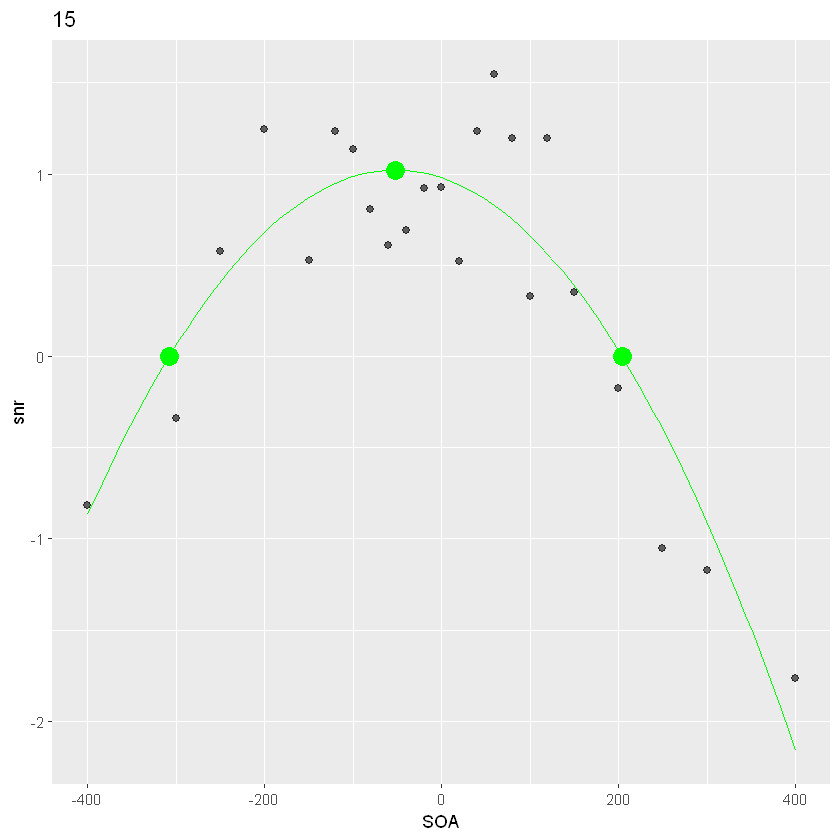

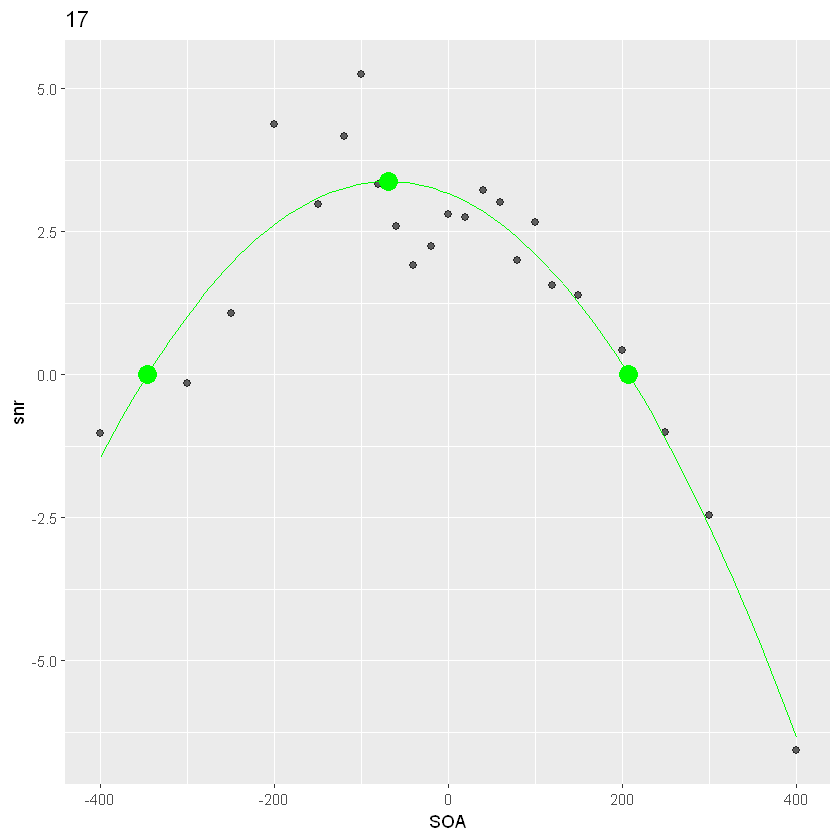

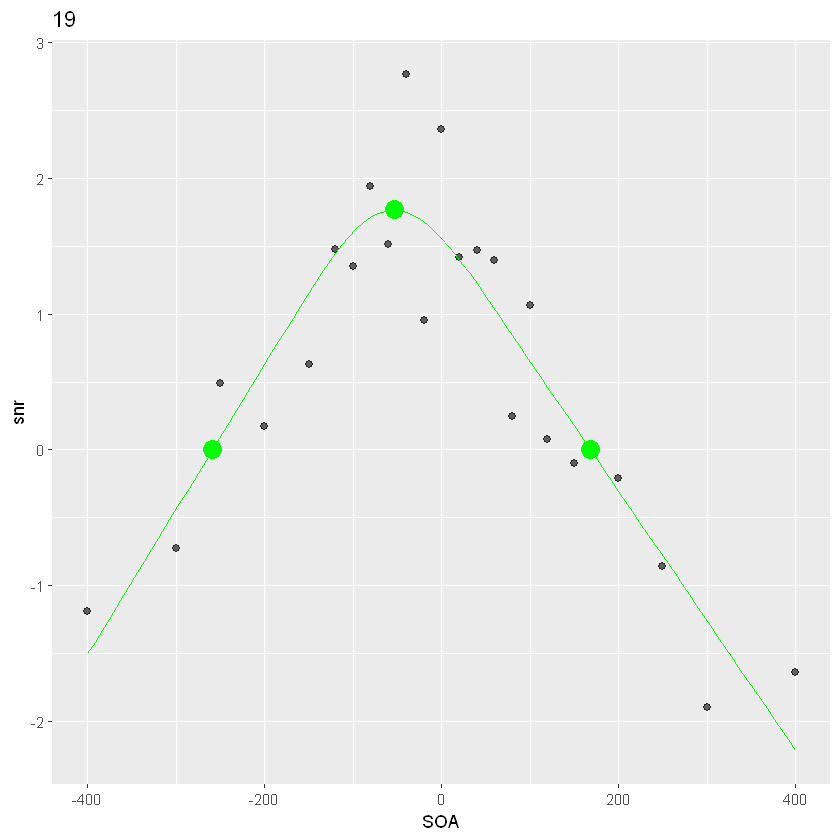

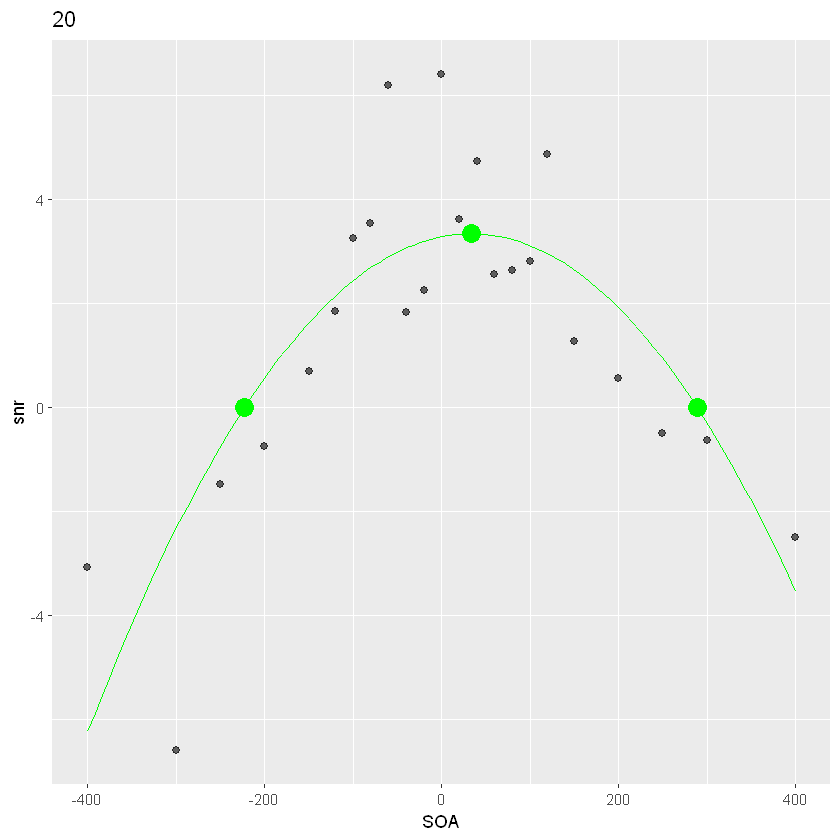

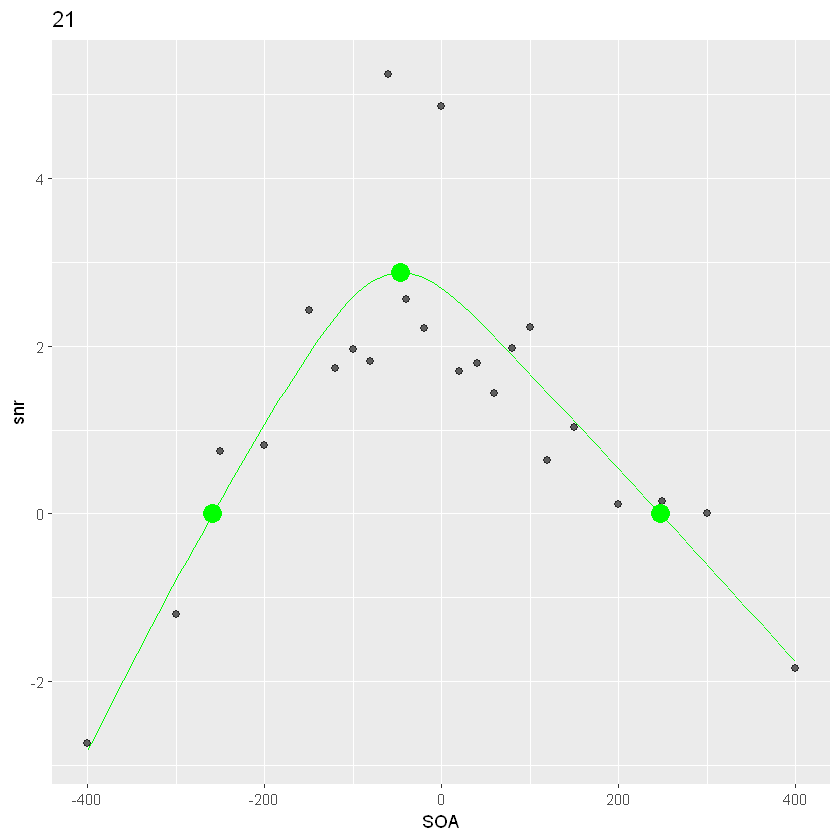

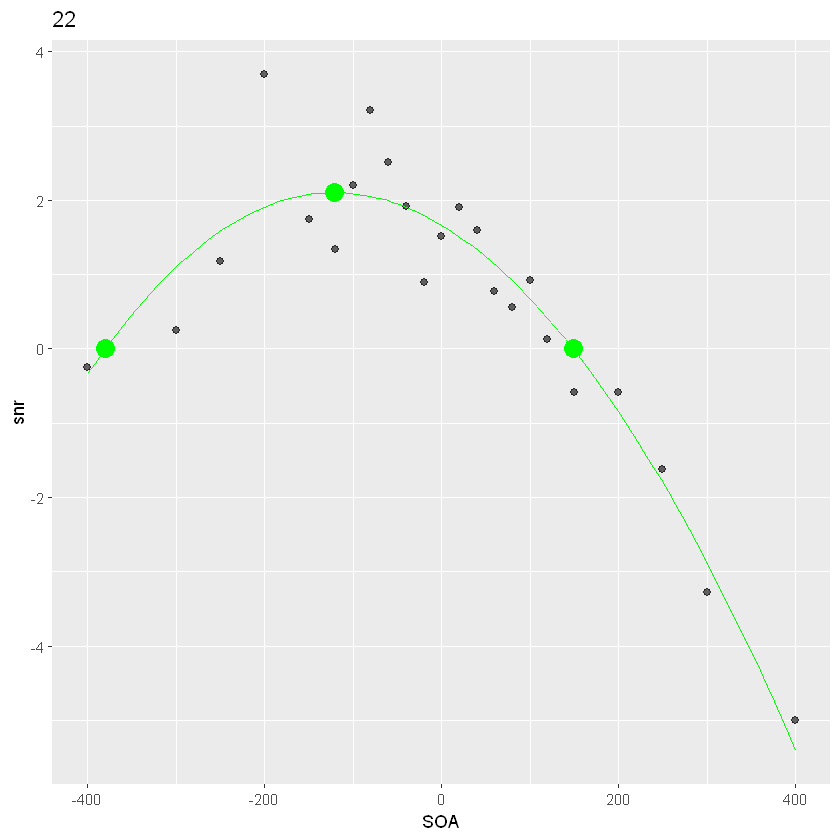

In [20]:
#==============================================================================#
# ESTIMATING LATENT SENSORY BIAS VIA SHAPE-CONSTRAINED ADDITIVE MODELS (SCAM)
# PURPOSE: Fit concave-constrained splines (with and without knot restrictions) 
#          to SNR profiles per participant, identifying functions' 
#          roots (zeros) to quantify sensory bias thresholds.
#==============================================================================#

sigmoid_results <- data.frame()

for (participant in unique(df_resp$ID)) {

    df_subset <- df_resp %>% filter(ID == participant)

    model <- scam(snr ~ s(SOA, bs = "cv"), data = df_subset)
    ff <- function(SOA) {
          predict(model, data.frame(SOA = SOA))
        }

        max_snr_SOA <- optimize(ff, interval = range(df_subset$SOA), maximum = TRUE)$maximum
        max_snr_value <- ff(max_snr_SOA)
    
    if (max_snr_value<0){
        roots = c(max_snr_SOA, max_snr_SOA)
    } else {
        roots <- findZeros(ff(x)~x)
        roots <- roots$x
    }

        print(ggplot(df_subset, aes(x = SOA, y = snr)) +
              # xlim(-600, 600) +
        ggtitle(glue('{participant} ')) +
        geom_point(size = 2, alpha = 0.6) + 
        geom_function(fun=ff, color='green') +
        geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green') +
        geom_point(data = data.frame(x = max_snr_SOA, y = max_snr_value), aes(x = x, y = y), size = 5, color = 'green') 
             )

        sigmoid_results <- rbind(sigmoid_results, data.frame(
            ID = participant,
            positive_root = roots[2],
            negative_root = roots[1],
            max_snr_SOA = max_snr_SOA,
            max_snr_value = max_snr_value))
}

In [21]:
head(sigmoid_results)

,ID,positive_root,negative_root,max_snr_SOA,max_snr_value
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,193.2109,-227.5455,-46.33780,3.4371268
11,3,-103.9749,-103.9749,-103.97488,-0.1829786
12,4,123.2282,-310.6443,-199.98941,0.7380726
13,5,208.2550,-234.0175,-44.42087,1.4723633
14,7,168.7700,-259.7393,-52.88315,2.2317758
15,8,76.6718,-183.4941,-61.61357,0.7924913


In [22]:
write_xlsx (sigmoid_results,"files/SJ_sensory_bias_general.xlsx")

In [10]:
df_summary <- df_resp %>%
  group_by(ID) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

In [11]:
head(df_summary)

ID,mean_Z
<dbl>,<dbl>
1,0.21244569
3,0.42931124
4,-0.05707451
5,0.32700068
7,0.01437192
8,0.19693812


In [13]:
write_xlsx (df_summary,"files/SJ_decision_bias_general.xlsx")

###############################################################
## 1-4 Testing the proximity of the PSS to one side

In [23]:
sigmoid_results <- read_excel("files/SJ_sensory_bias_general.xlsx")

In [24]:
head(sigmoid_results)

ID,positive_root,negative_root,max_snr_SOA,max_snr_value
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,193.2109,-227.5455,-46.33780,3.4371268
3,-103.9749,-103.9749,-103.97488,-0.1829786
4,123.2282,-310.6443,-199.98941,0.7380726
5,208.2550,-234.0175,-44.42087,1.4723633
7,168.7700,-259.7393,-52.88315,2.2317758
8,76.6718,-183.4941,-61.61357,0.7924913


In [75]:
sigmoid_results$max_bias <- (sigmoid_results$max_snr_SOA > (sigmoid_results$negative_root + sigmoid_results$positive_root)/2)

In [80]:
binom.test(x=sum(sigmoid_results$max_bias), n=nrow(sigmoid_results), p = 0.5, alternative = "two.sided", conf.level = 0.95)




data:  sum(sigmoid_results$max_bias) out of 17L
number of successes = 1, number of trials = 17, p-value = 0.0002747
alternative hypothesis: true probability of success is not equal to 0.5
95 percent confidence interval:
 0.001488174 0.286889397
sample estimates:
probability of success 
            0.05882353 


###############################################################\
###############################################################
# 2- Prior response
**List of contents:**\
2-1 Plotting SNR curves\
2-2 Calculating sensory and decisional bias\
2-3 Testing change in positive root\
2-4 Testing change in negative root\
2-5 Testing change in PSS\
2-6 Testing change in relative starting point

In [25]:
df_resp <- read_xlsx("files/SJ_prior_response_DDM_parameters_clean.xlsx")

# Rename first columns for clarity
colnames(df_resp)[1] <- "ID"
colnames(df_resp)[2] <- "prior_response"

# ---------------------------------------------------------
# Compute Signal-to-Noise Ratio (SNR)
# SNR = drift rate (v) / noise (σ)
# This quantity reflects the quality of sensory evidence
# accumulation and is used as an index of sensory bias.
# ---------------------------------------------------------
df_resp$snr <- df_resp$drift / df_resp$noise

###############################################################
## 2-1 Plotting SNR curves

In [90]:
summary_resp <- df_resp %>%
  group_by(SOA, prior_response) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [91]:
df_predicted = data.frame()
for (participant in unique(df_resp$ID)) {
    for (condition in unique(df_resp$prior_response)) {
        df_resp_subset <- df_resp %>% filter(ID == participant, prior_response == condition)

        model <- scam(snr ~ s(SOA, bs = "cv"), data = df_resp_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        df <- data.frame(ID=participant, prior_response=condition, SOA = -400:400, snr=ff(-400:400))
        df_predicted <- rbind(df_predicted, df)
}}

In [25]:
df_predicted_summary <- df_predicted %>%
  group_by(prior_response, SOA) %>%
  summarise(
    mean_snr = mean(snr),
    se = sd(snr) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

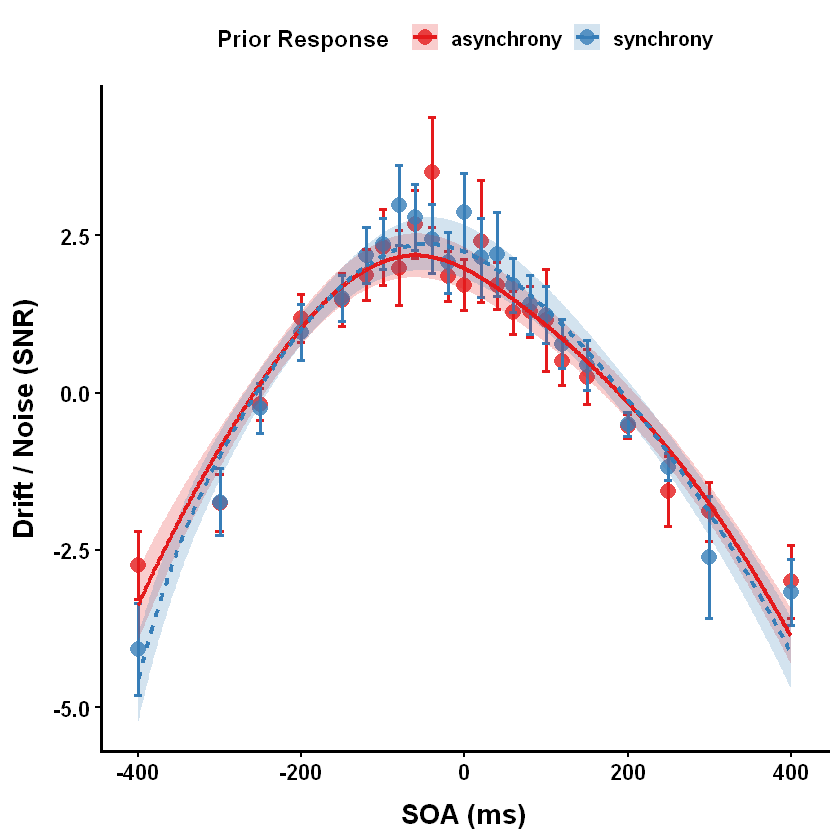

In [26]:
# save as PDF
pdf(file="figures/SJ_prior_response_snr.pdf", width = 10, height = 8)  

# Create the plot with publication-style formatting
p_sj_prior_resp <- ggplot() +
  # Plot observed data points
  geom_point(
    data = summary_resp,
    aes(x = SOA, y = mean_snr, color = prior_response),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = summary_resp,
    aes(
      x = SOA,
      ymin = mean_snr - se_snr,
      ymax = mean_snr + se_snr,
      color = prior_response
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_snr - se,
      ymax = mean_snr + se,
      fill = prior_response,
      group = prior_response
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_snr,
      color = prior_response,
      linetype = prior_response,
      group = prior_response
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)",
    color = "Prior Response",
    linetype = "Prior Response",
    fill = "Prior Response"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_sj_prior_resp
dev.off()
# 3. Display the plot
print(p_sj_prior_resp)

###############################################################
## 2-2 Calculating sensory and decisional bias

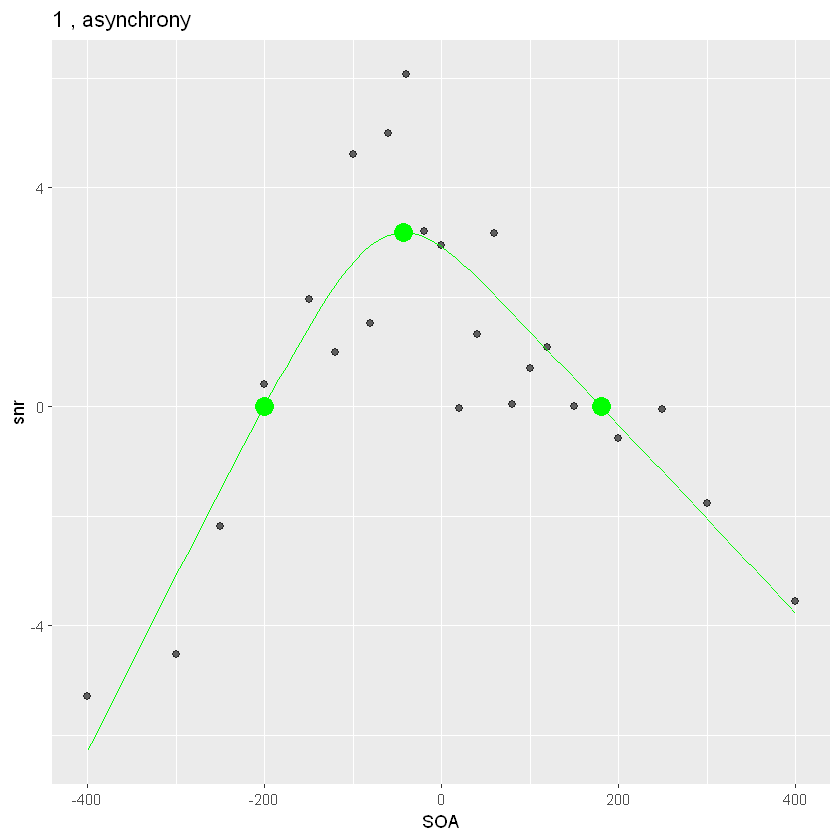

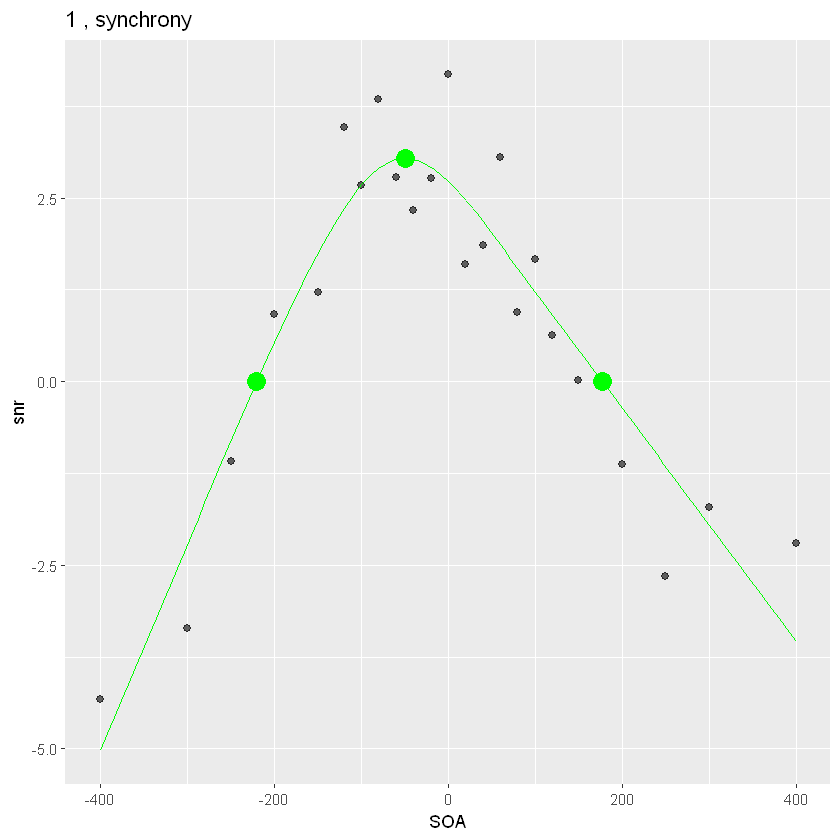

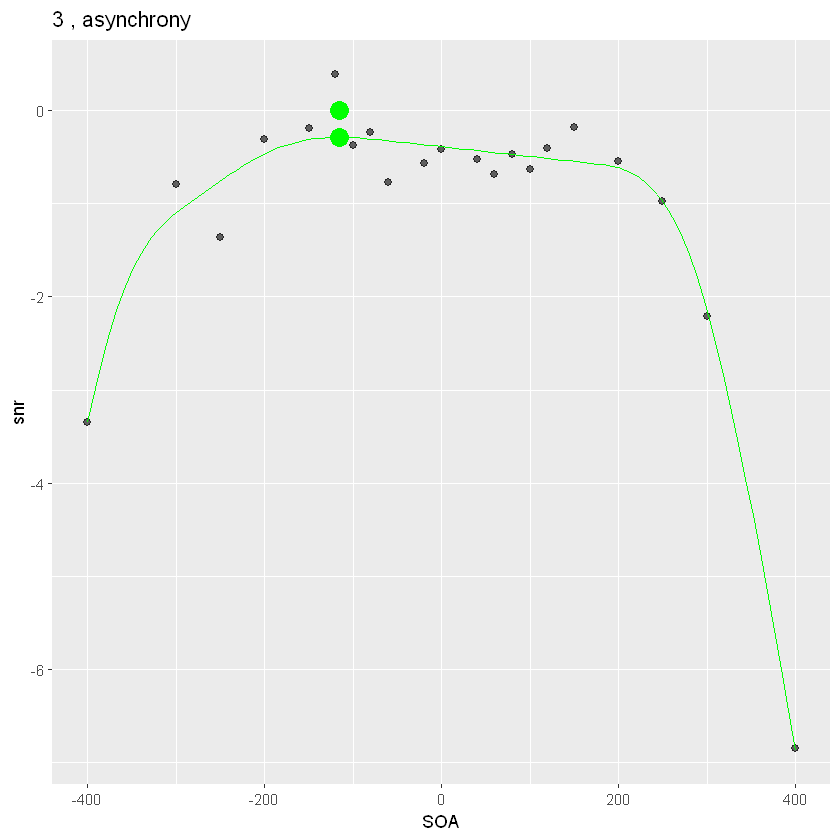

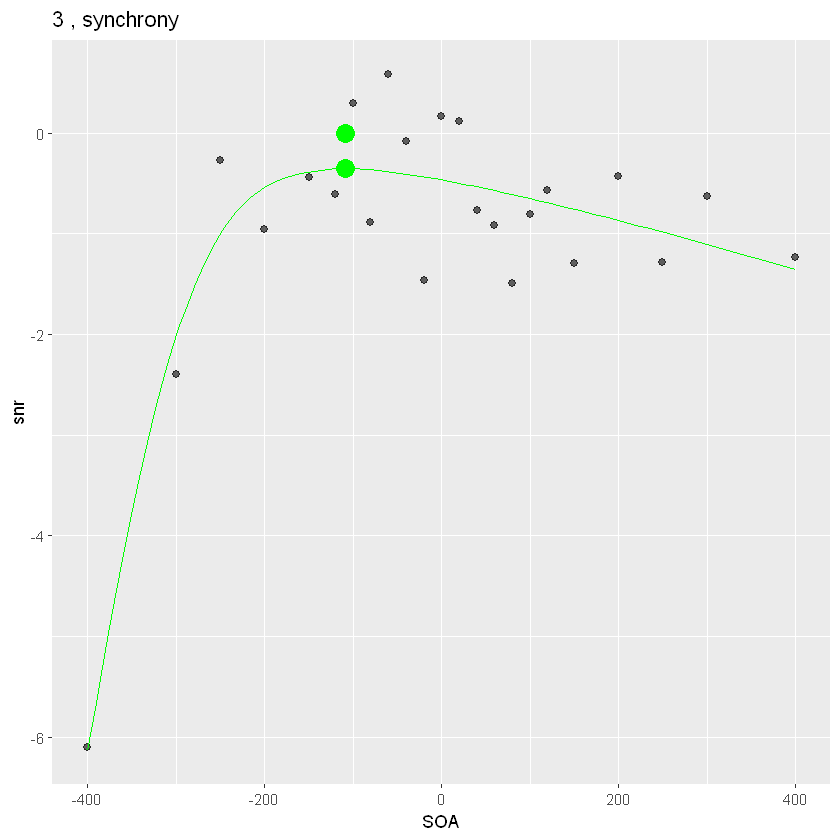

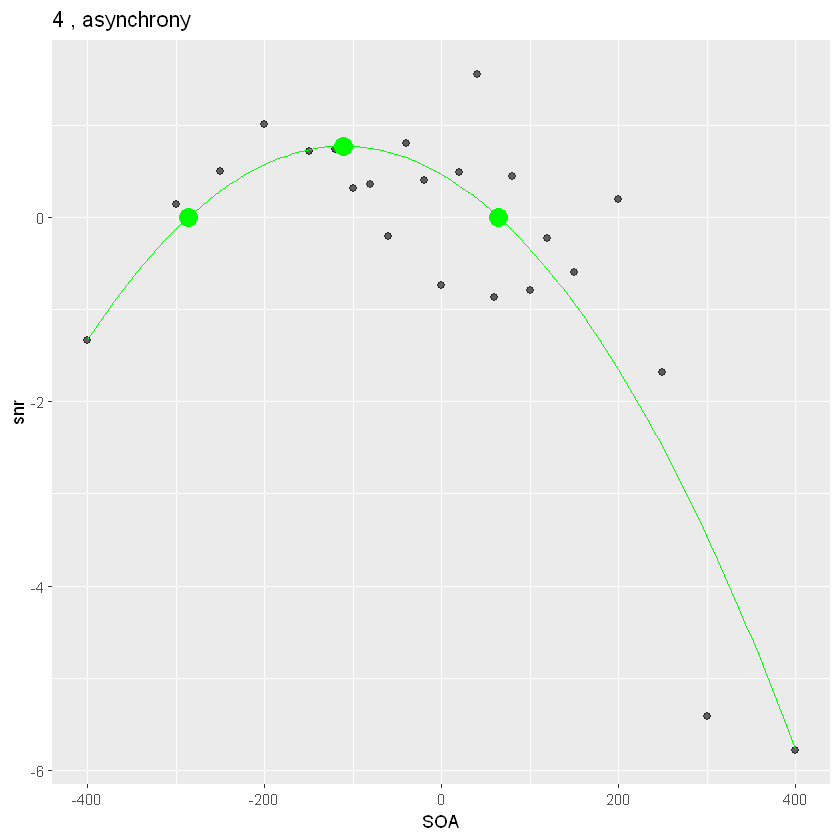

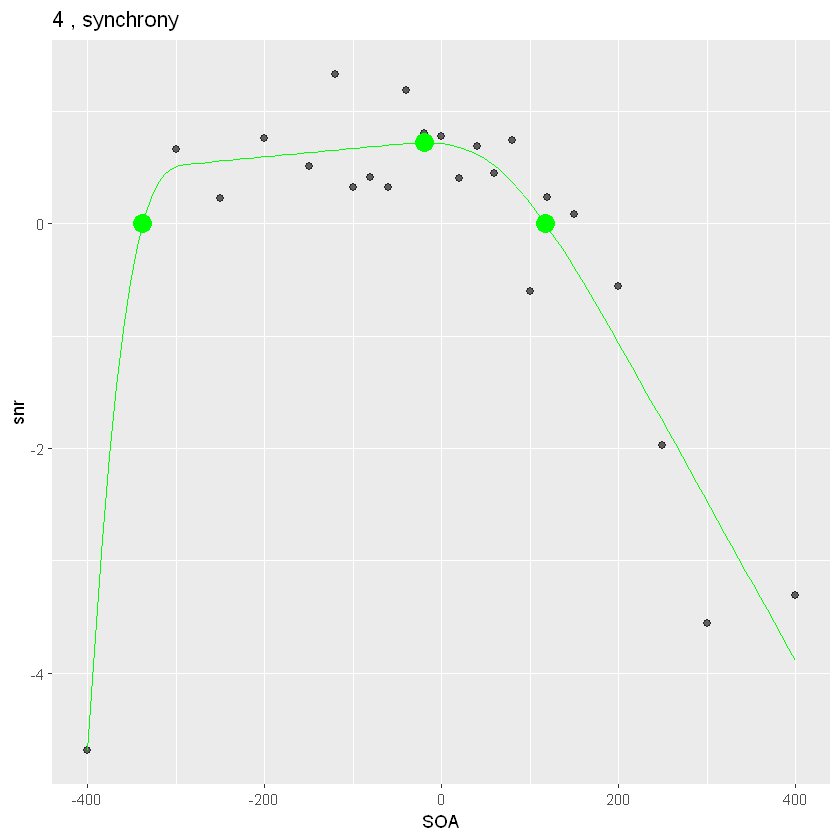

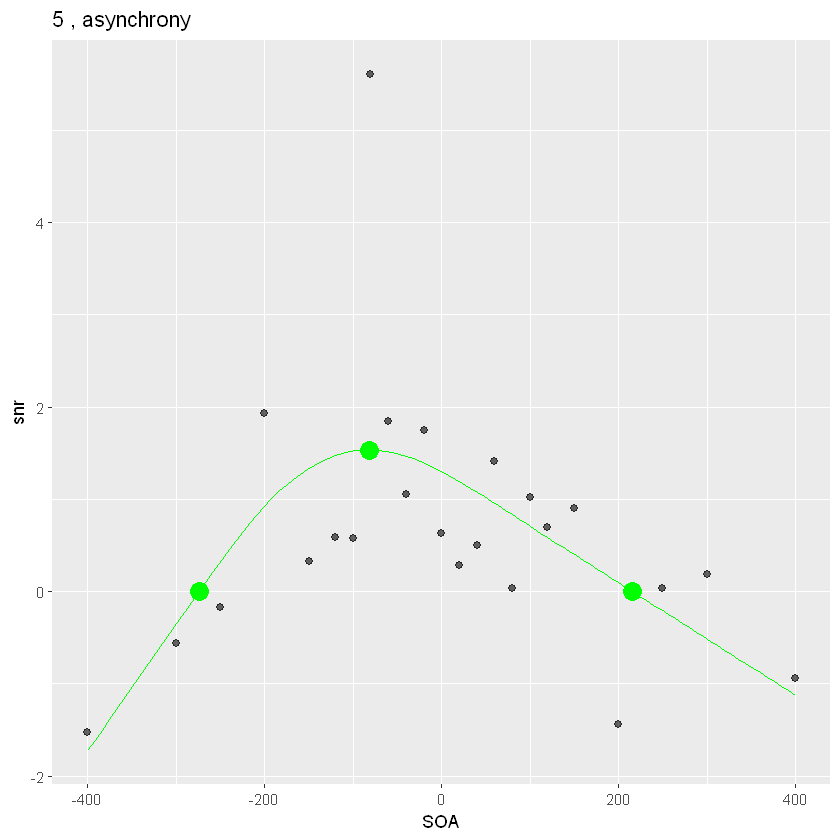

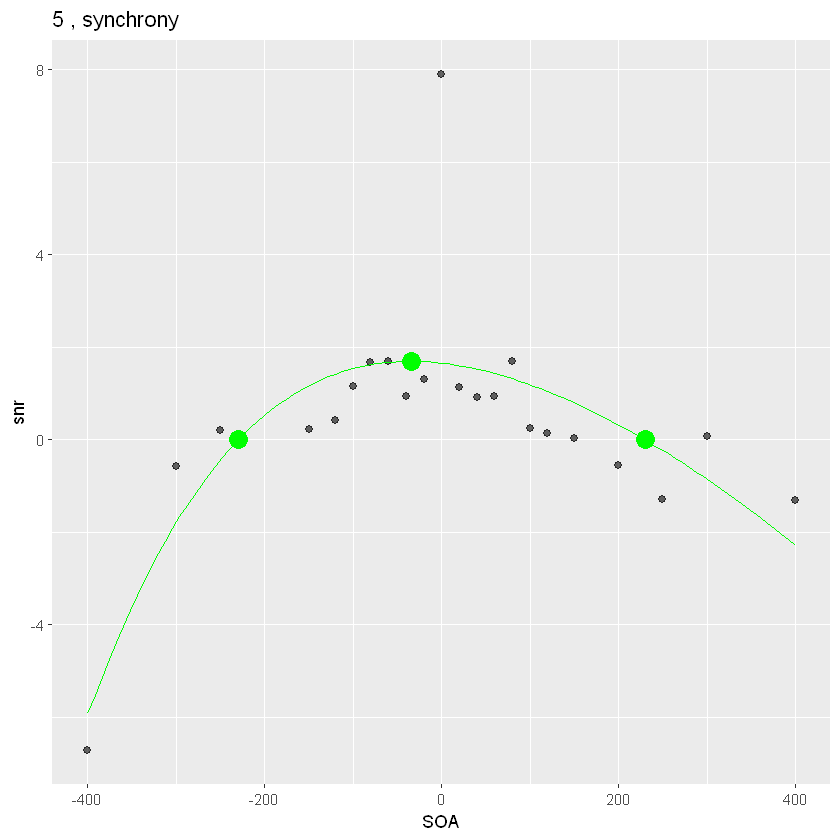

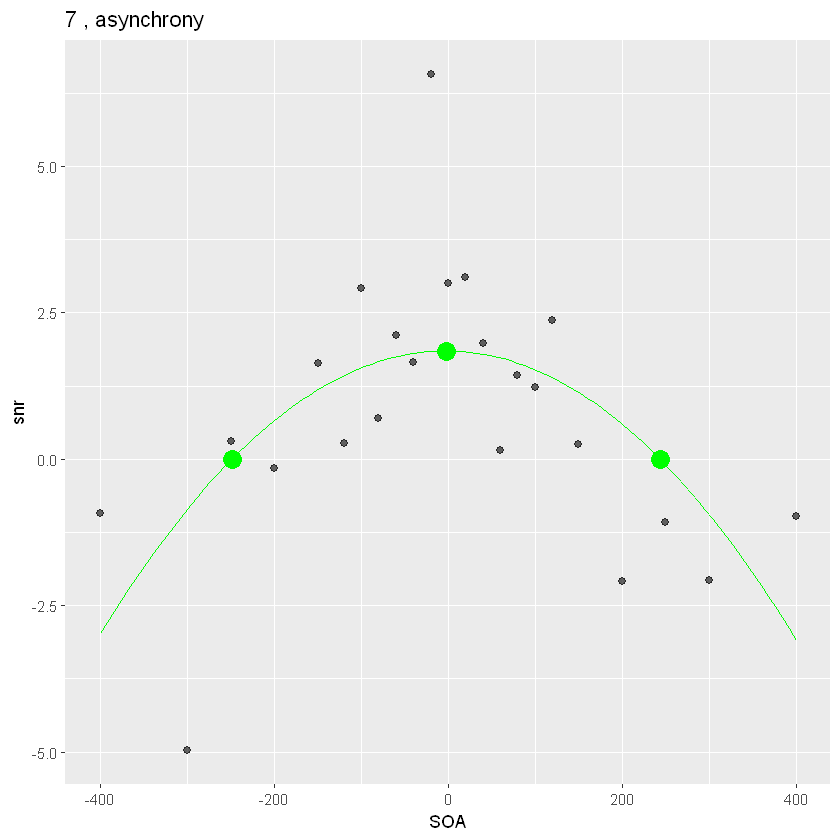

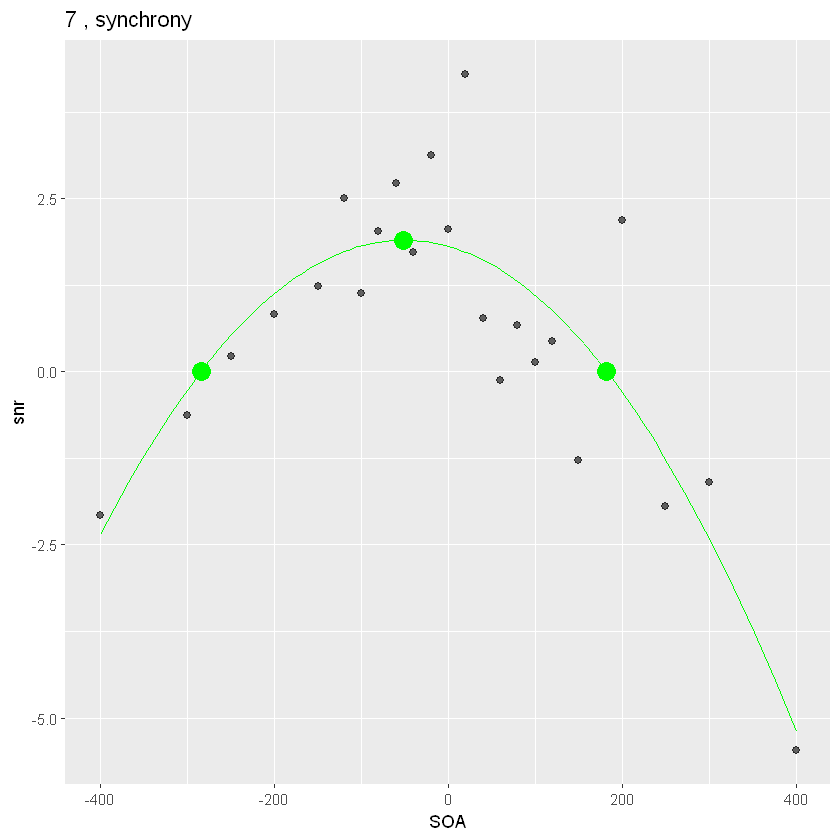

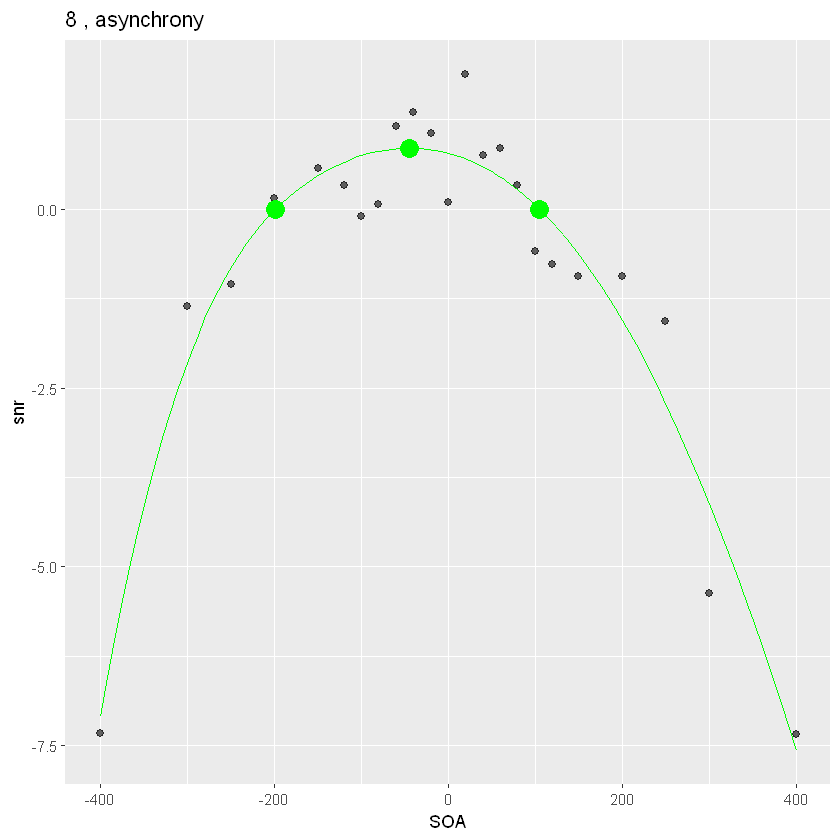

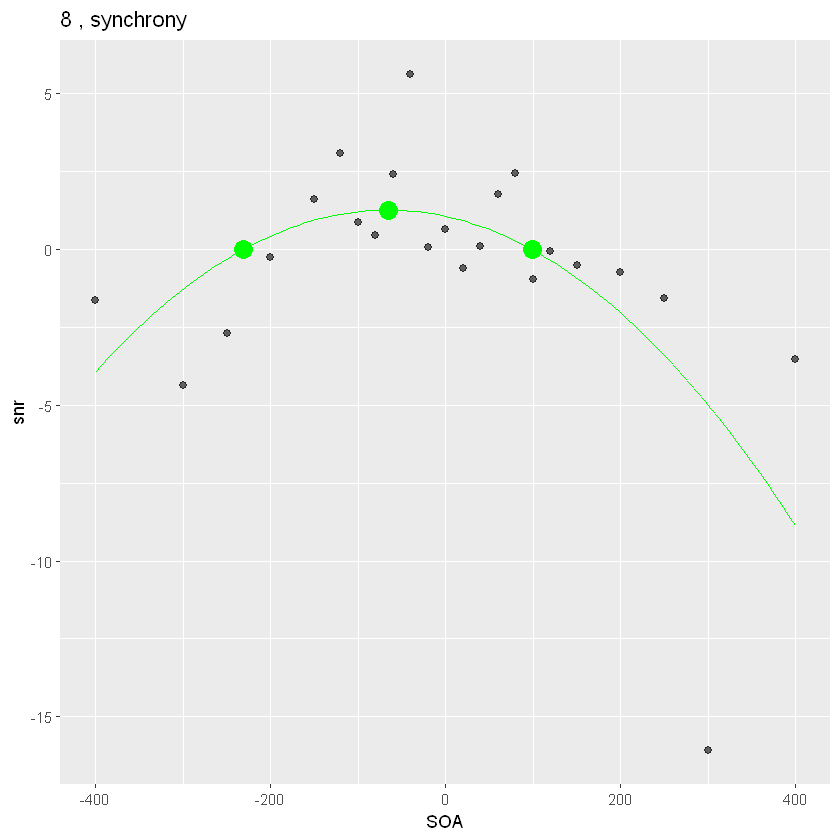

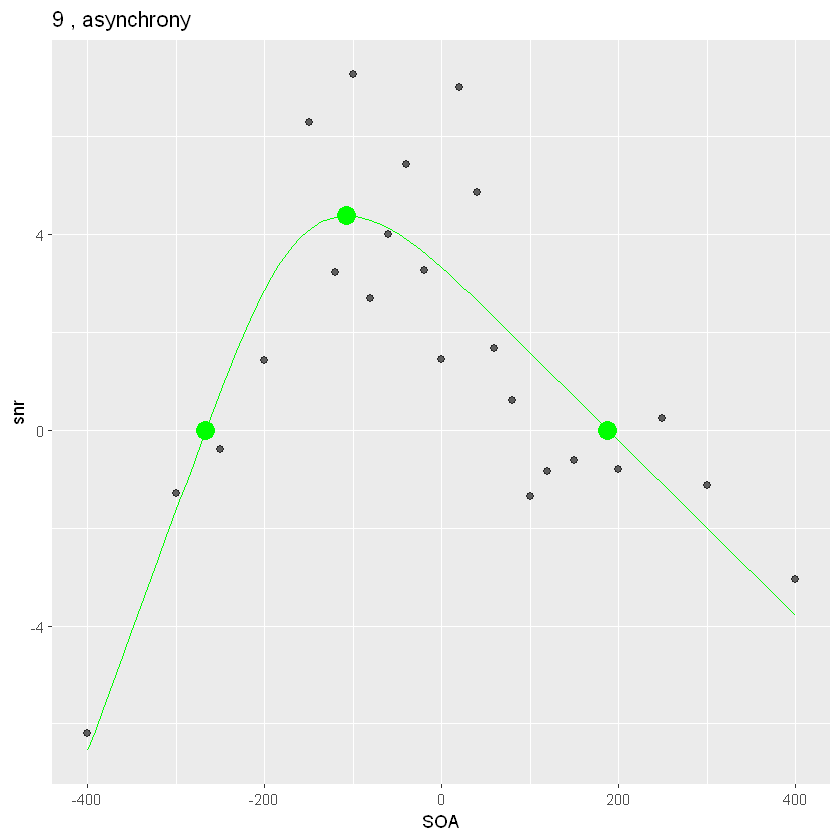

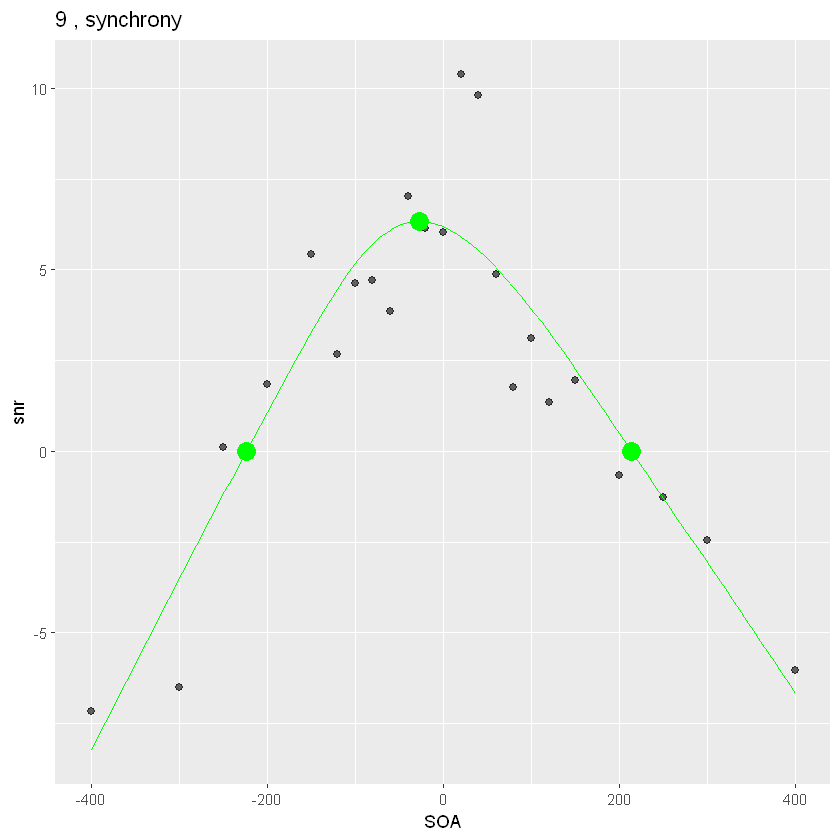

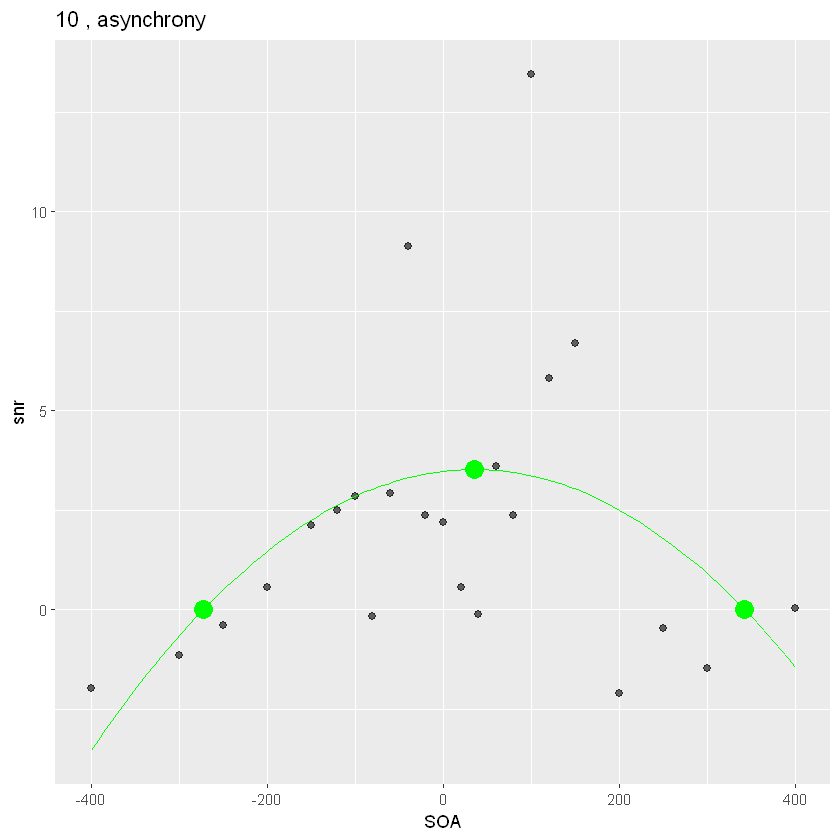

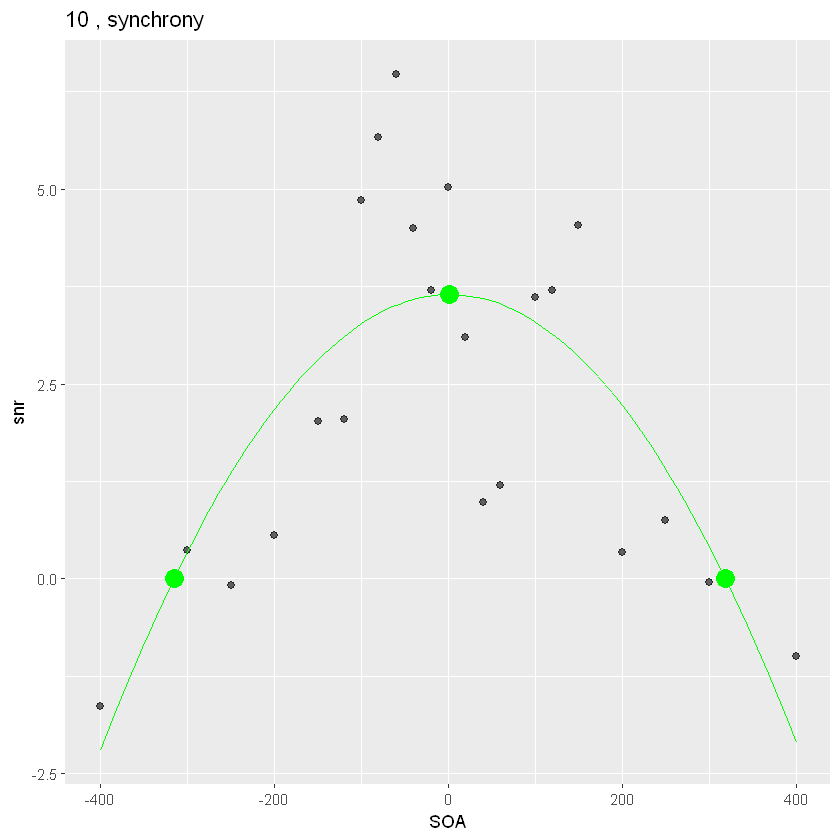

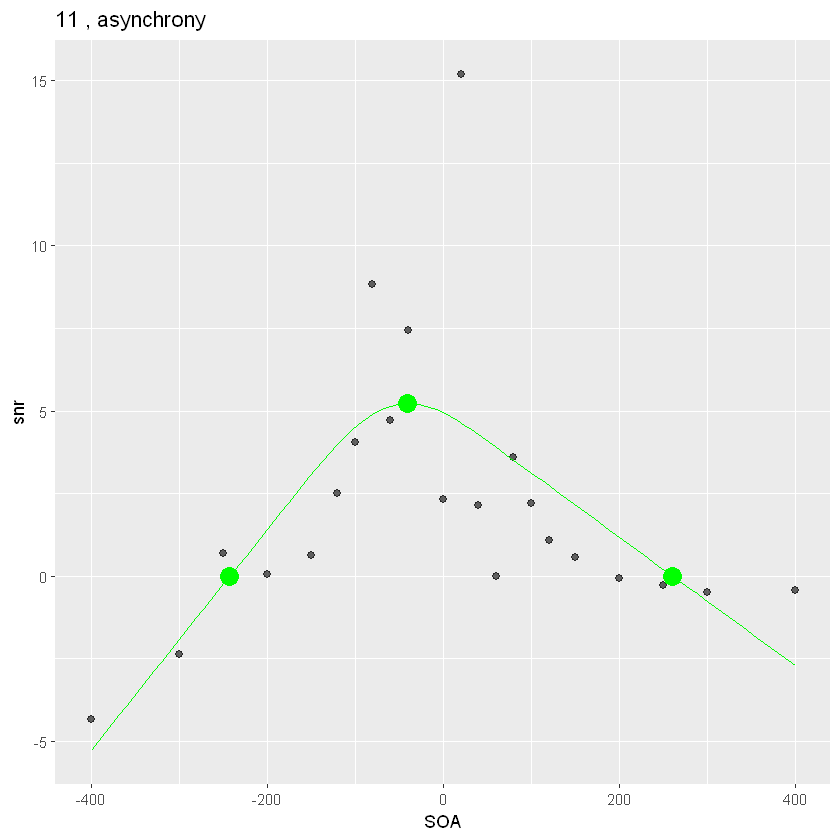

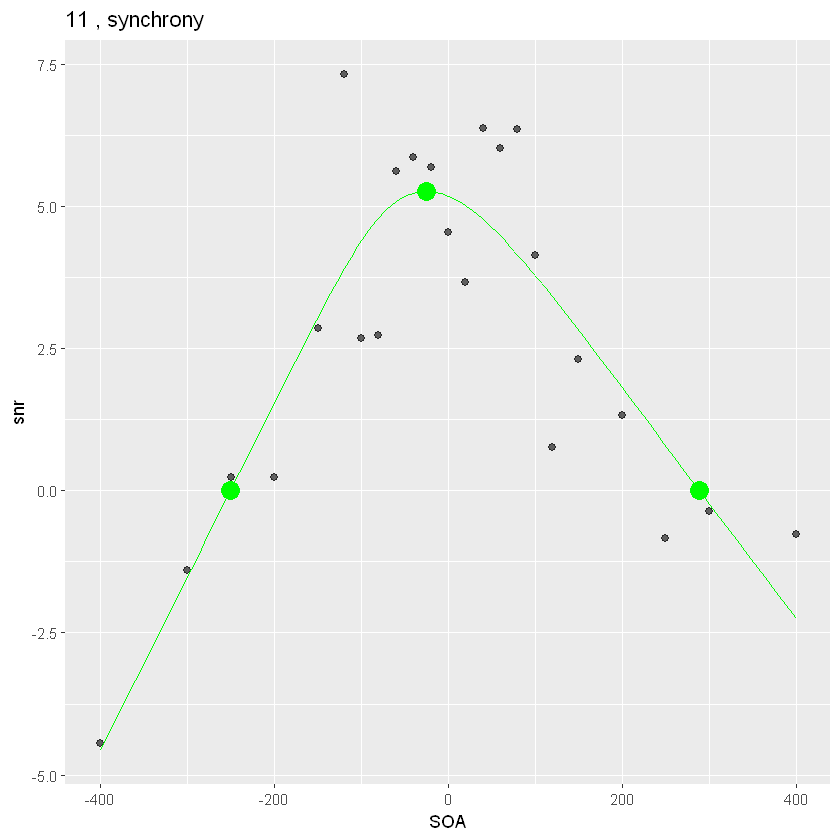

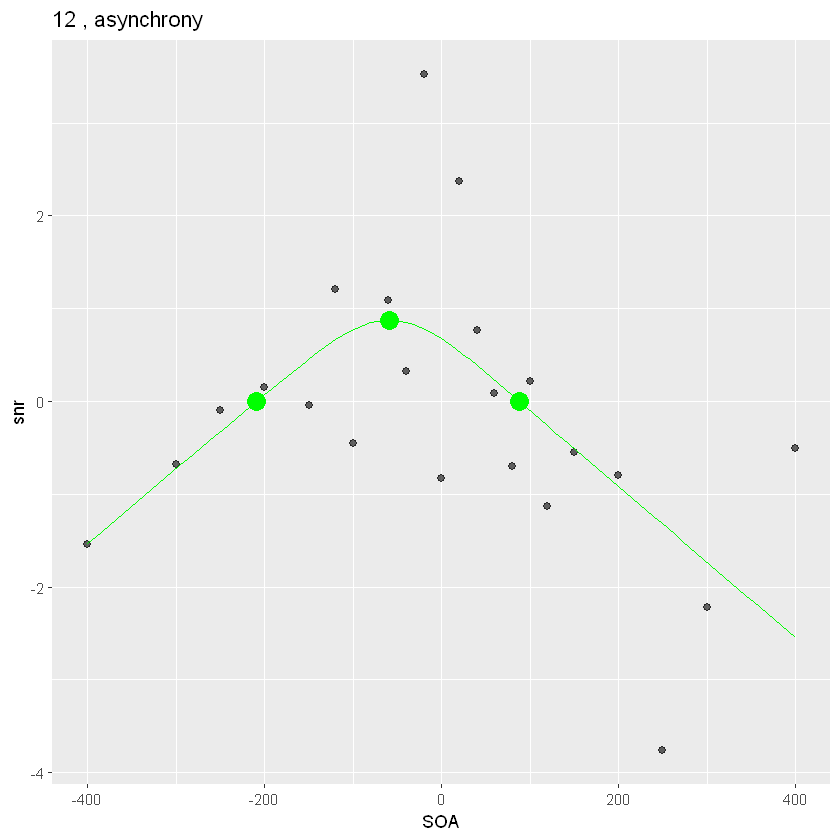

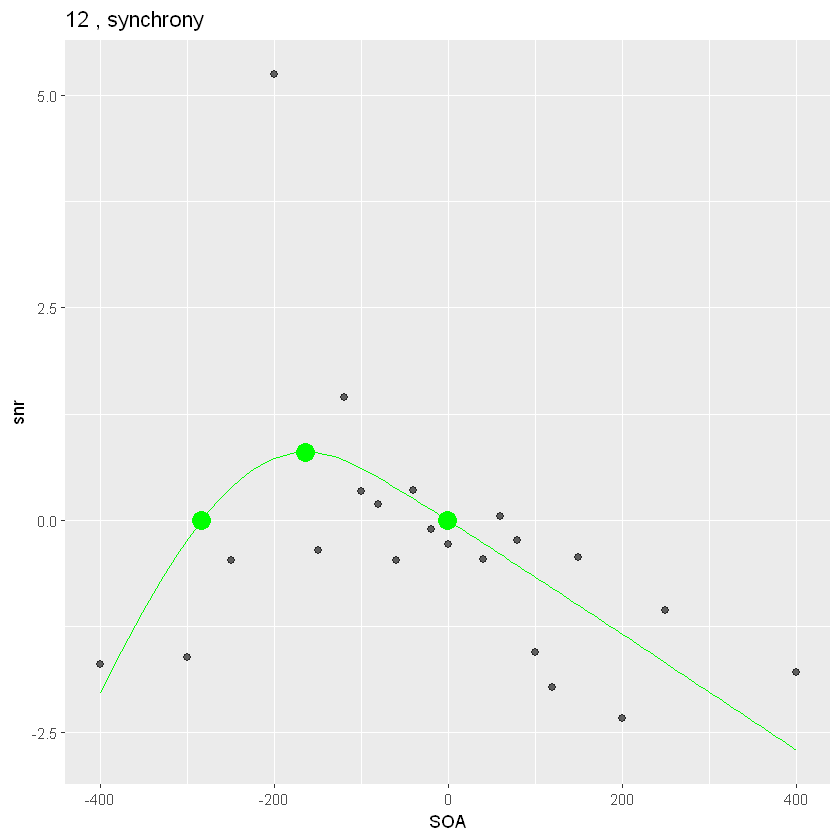

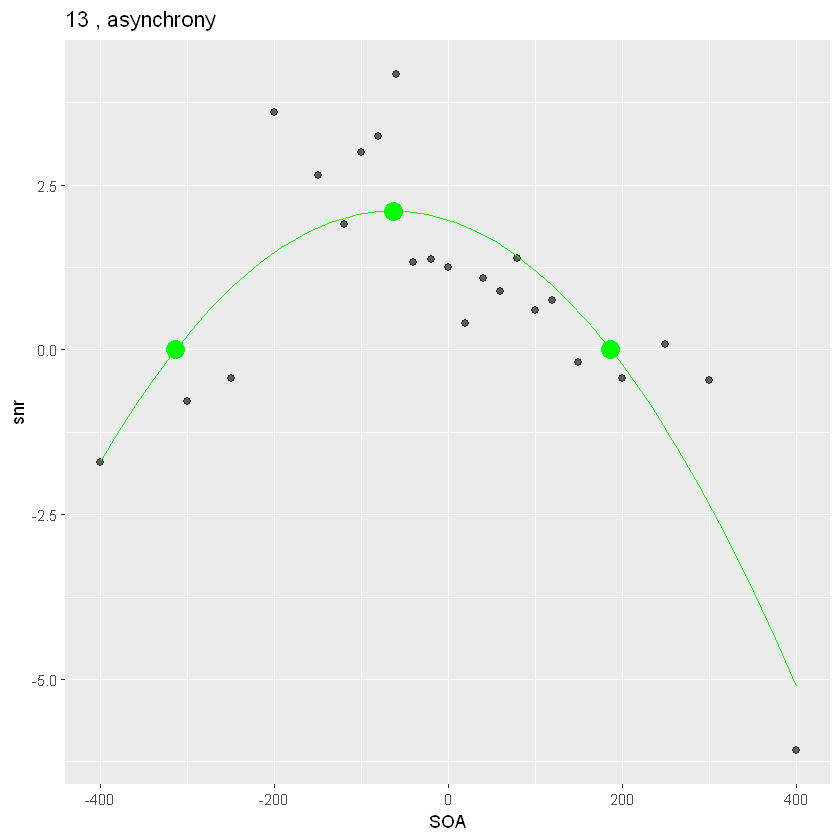

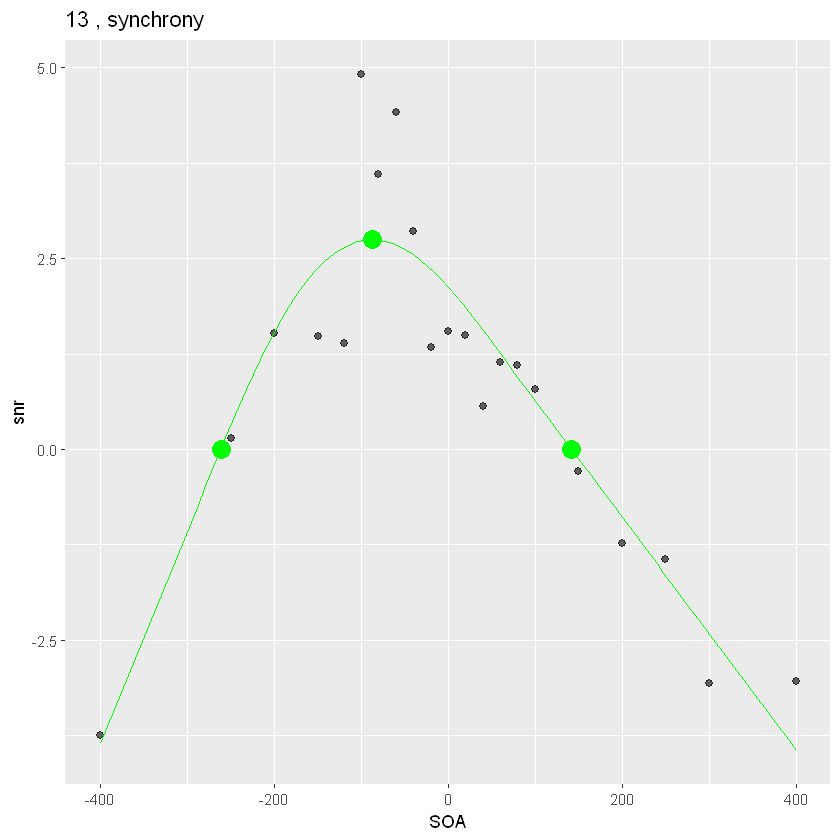

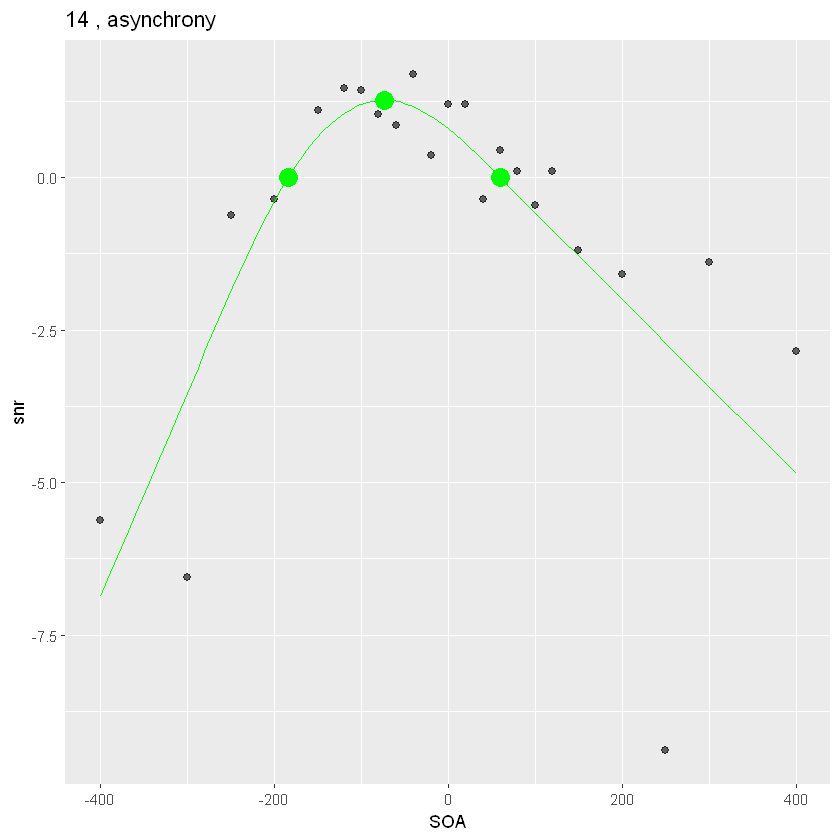

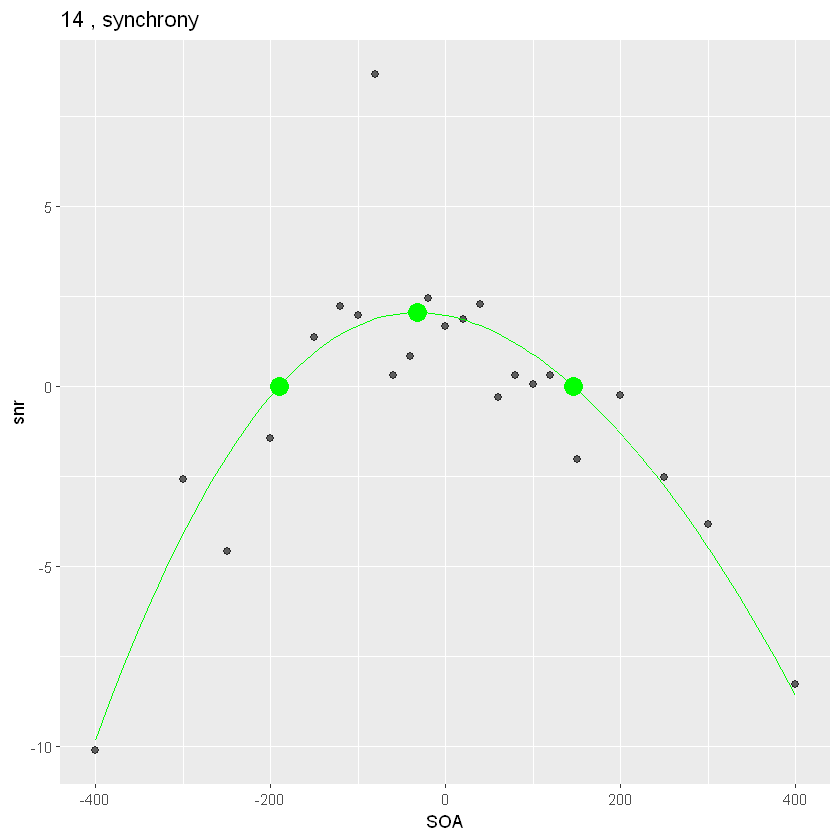

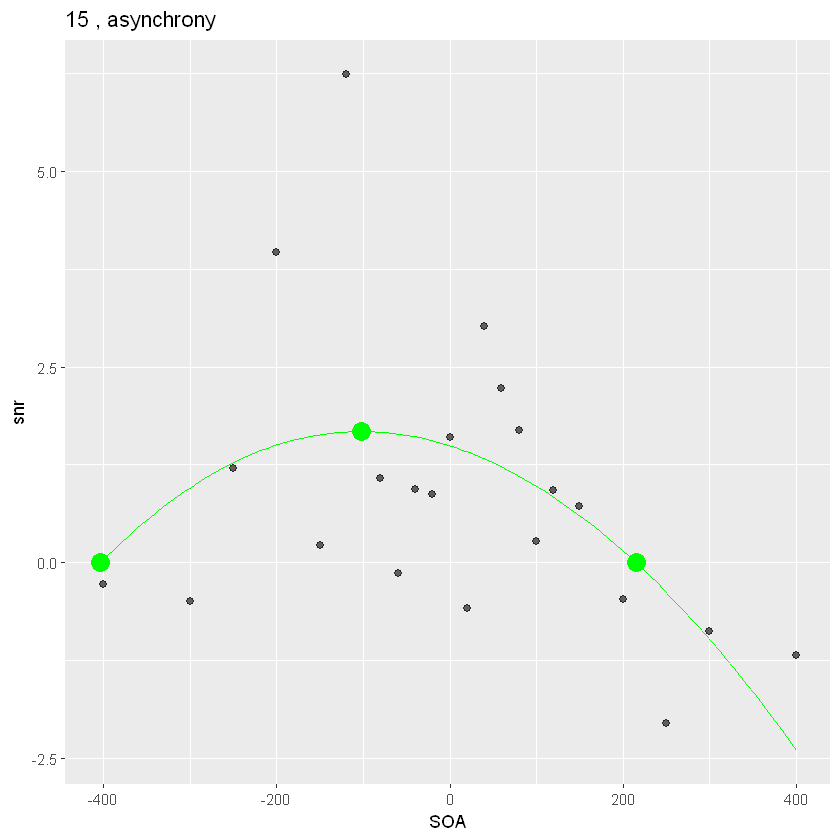

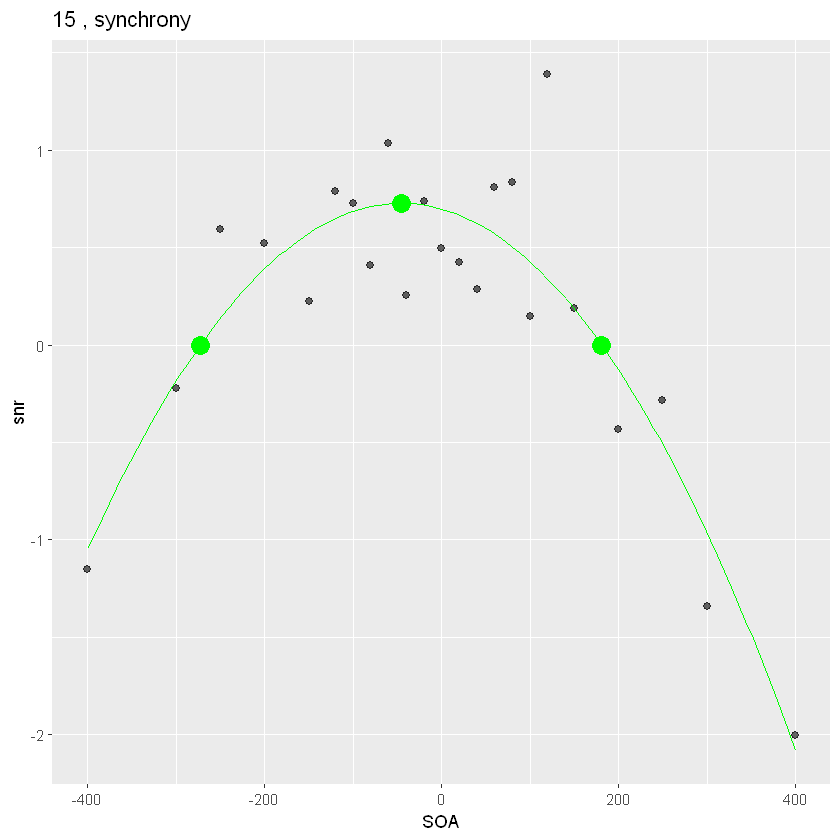

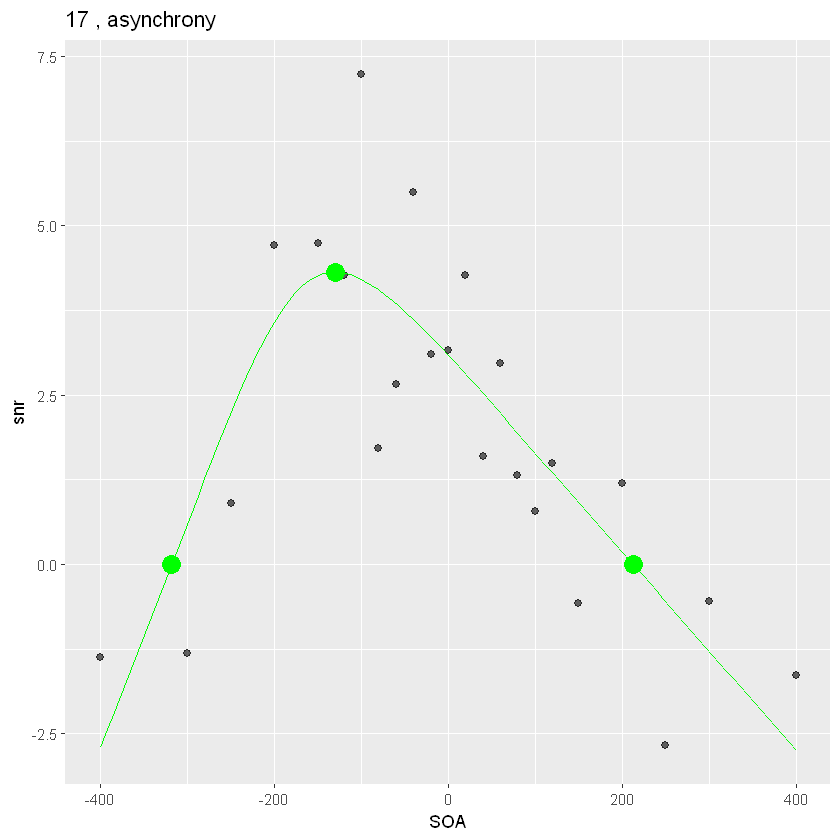

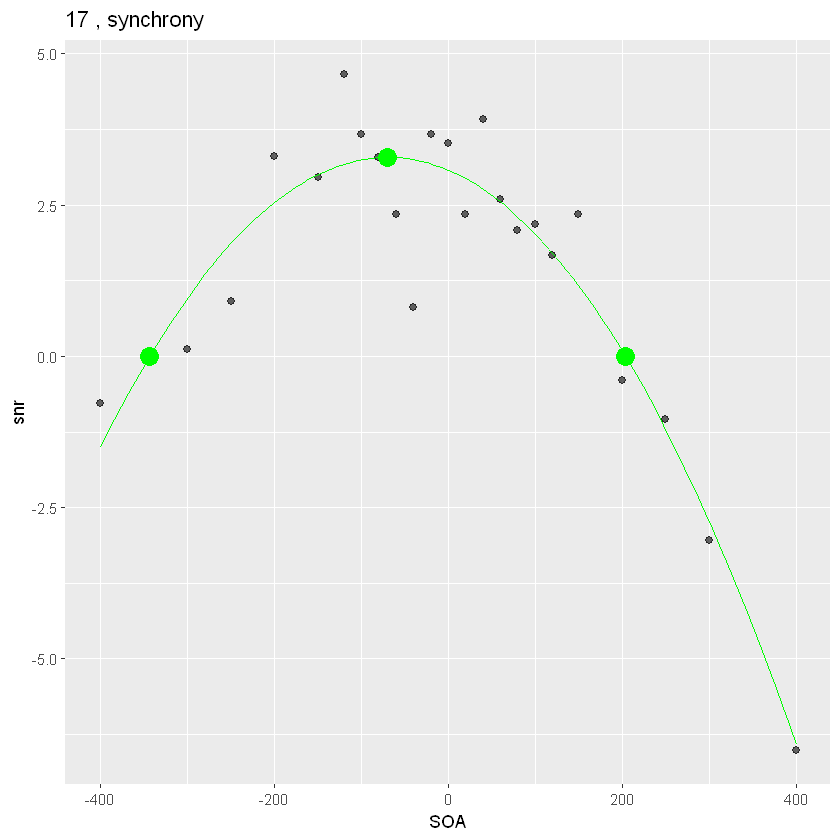

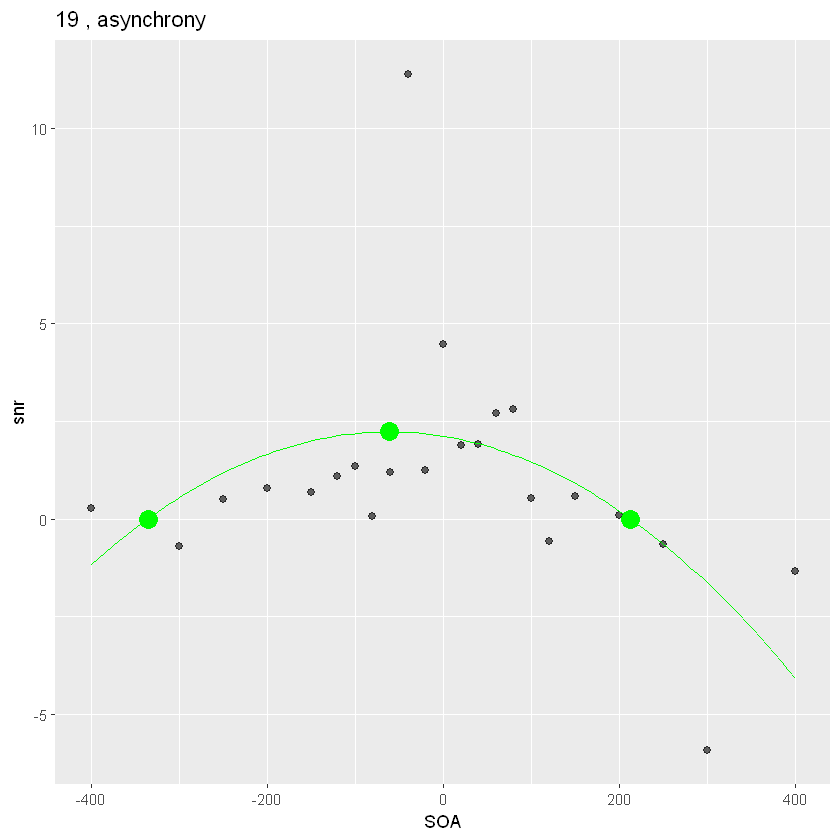

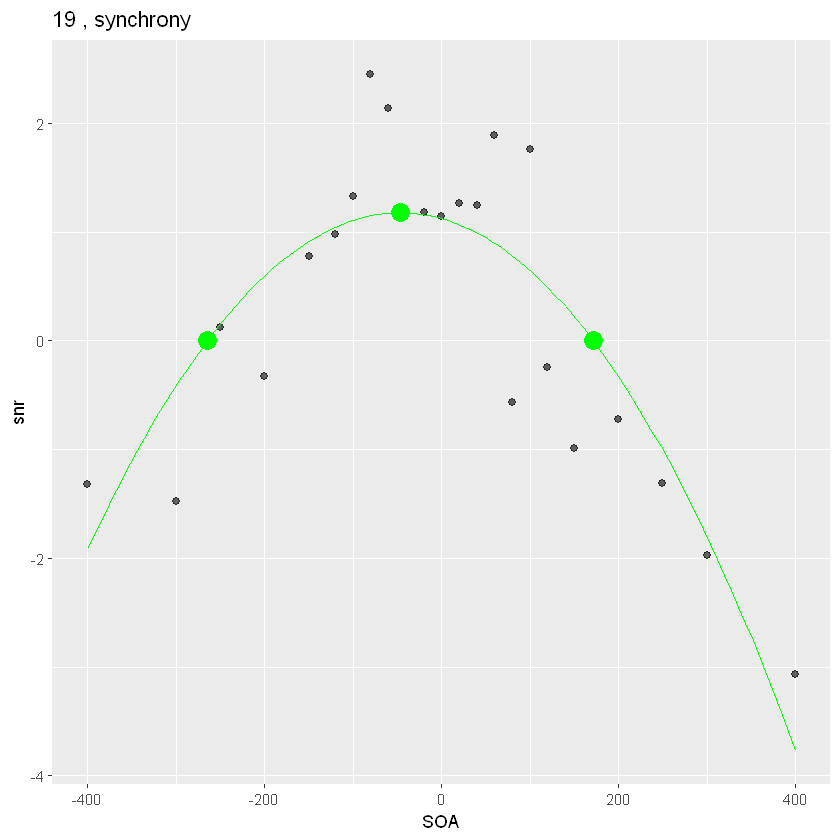

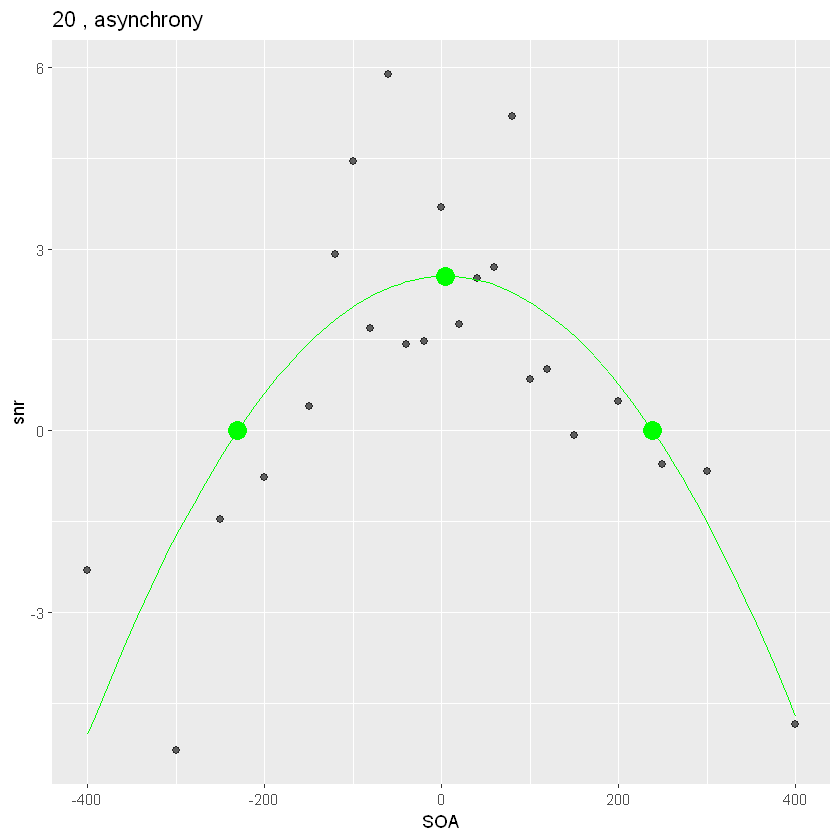

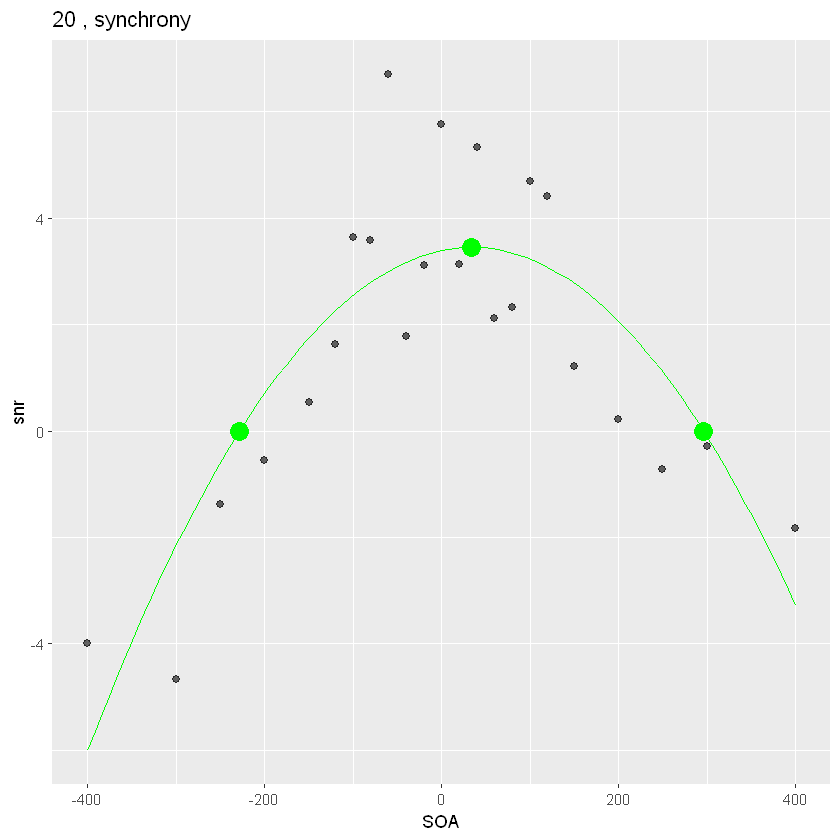

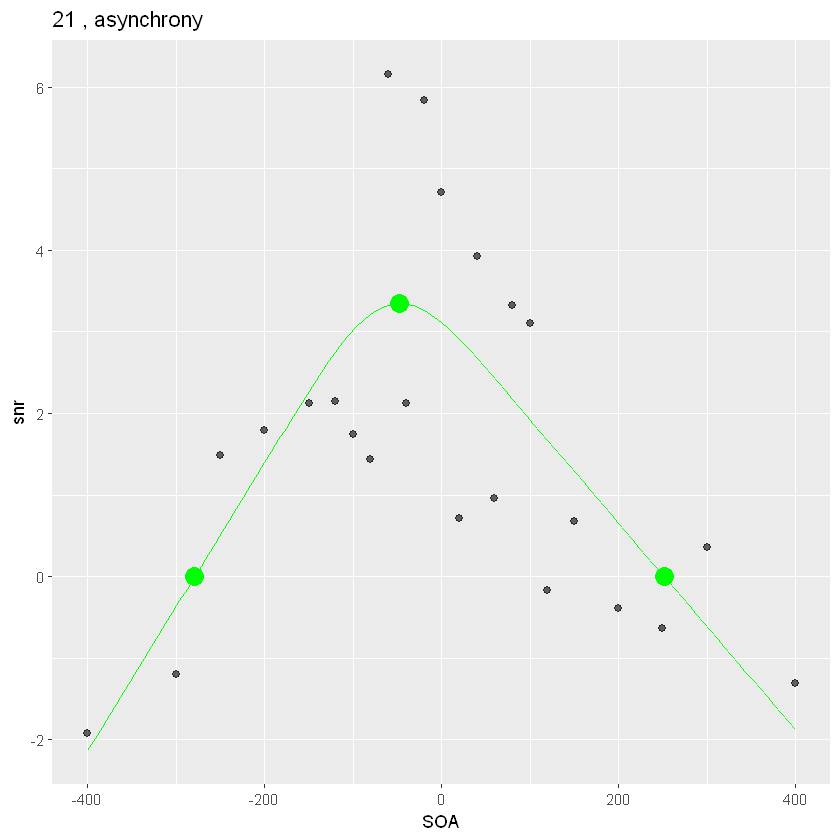

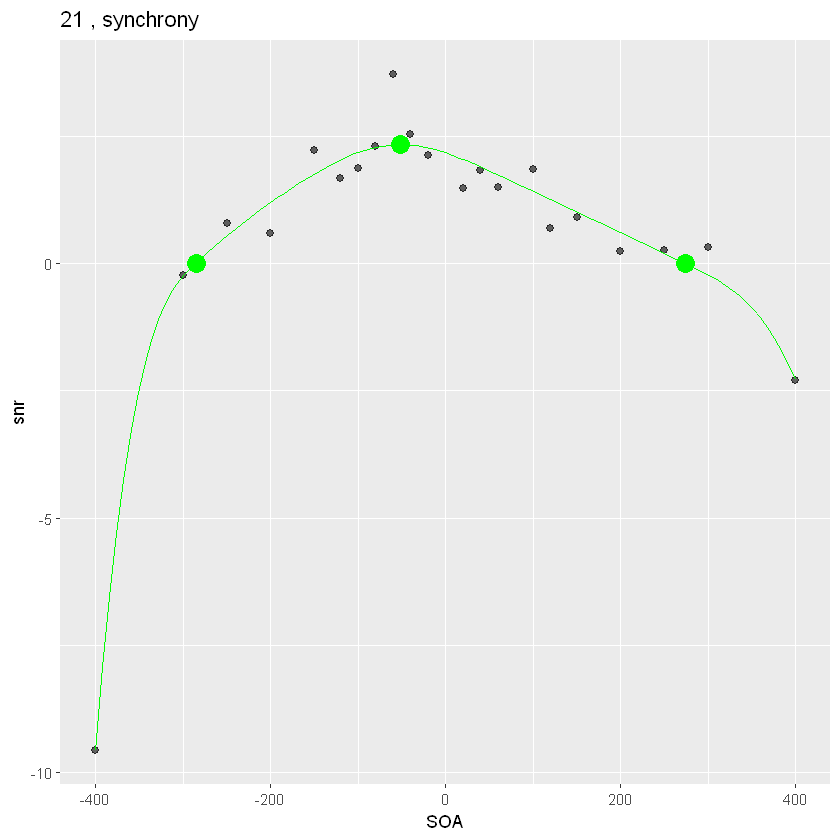

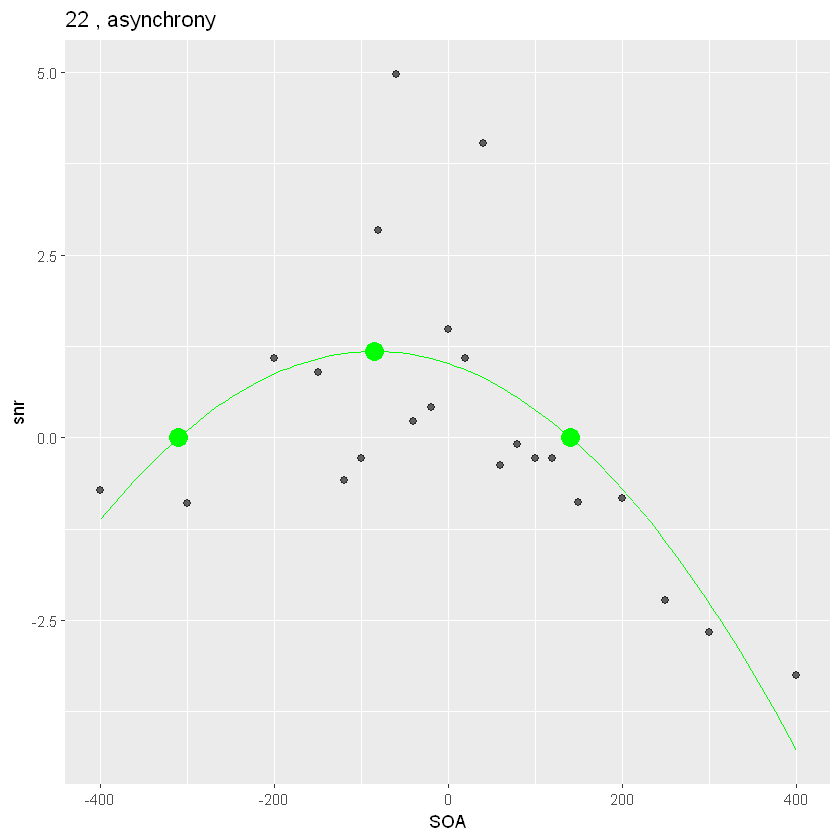

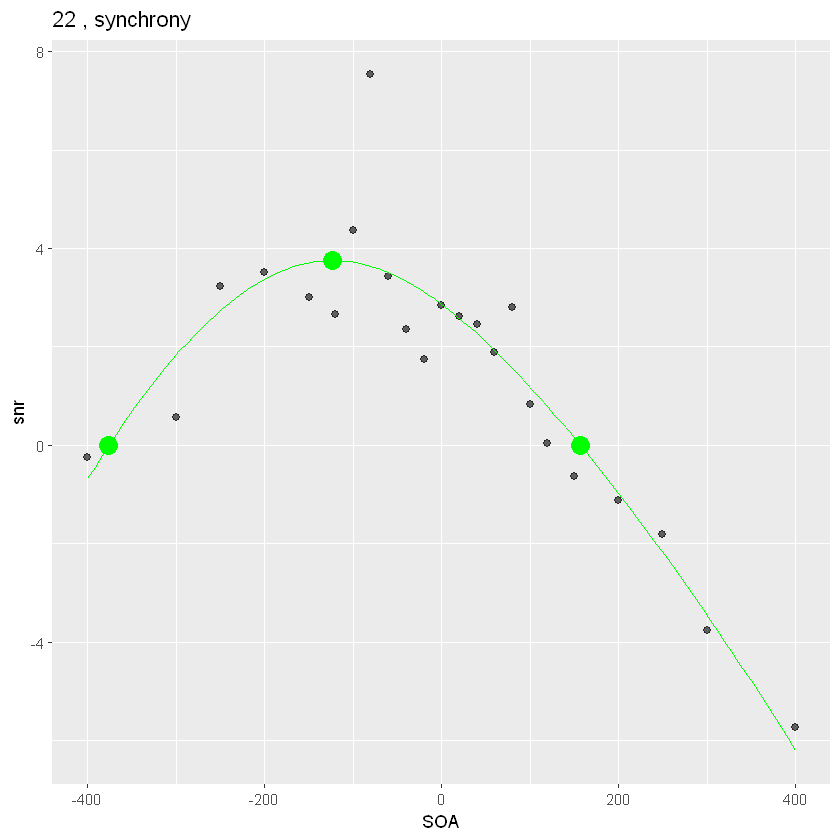

In [41]:
#==============================================================================#
# ESTIMATING LATENT SENSORY BIAS VIA SHAPE-CONSTRAINED ADDITIVE MODELS (SCAM)
# PURPOSE: Fit concave-constrained splines (with and without knot restrictions) 
#          to SNR profiles per participant and condition, identifying functions' 
#          roots (zeros) to quantify sensory bias thresholds.
#==============================================================================#

sigmoid_results <- data.frame()

for (participant in unique(df_resp$ID)) {
    for (condition in unique(df_resp$prior_response)) {

        df_subset <- df_resp %>% filter(ID == participant, prior_response == condition)

        model <- scam(snr ~ s(SOA, bs = "cv"), data = df_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }

            max_snr_SOA <- optimize(ff, interval = range(df_subset$SOA), maximum = TRUE)$maximum
            max_snr_value <- ff(max_snr_SOA)
        
        if (max_snr_value<0){
            roots = c(max_snr_SOA, max_snr_SOA)
        } else {
            roots <- findZeros(ff(x)~x)
            roots <- roots$x
        }

            print(ggplot(df_subset, aes(x = SOA, y = snr)) +
                  # xlim(-600, 600) +
            ggtitle(glue('{participant} , {condition}')) +
            geom_point(size = 2, alpha = 0.6) + 
            geom_function(fun=ff, color='green') +
            geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green') +
            geom_point(data = data.frame(x = max_snr_SOA, y = max_snr_value), aes(x = x, y = y), size = 5, color = 'green') 
                 )

            sigmoid_results <- rbind(sigmoid_results, data.frame(
                ID = participant,
                prior_response = condition,
                positive_root = roots[2],
                negative_root = roots[1],
                max_snr_SOA = max_snr_SOA,
                max_snr_value = max_snr_value))        
    }
}

In [43]:
head(sigmoid_results)

,ID,prior_response,positive_root,negative_root,max_snr_SOA,max_snr_value
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,asynchrony,180.2456,-200.4589,-42.90688,3.1778642
11,1,synchrony,177.1377,-220.2337,-49.90895,3.0386200
12,3,asynchrony,-115.9684,-115.9684,-115.96843,-0.2864074
13,3,synchrony,-108.5322,-108.5322,-108.53224,-0.3543309
14,4,asynchrony,64.5592,-286.3911,-110.91539,0.7717011
15,4,synchrony,117.2908,-337.8343,-19.83392,0.7182574


In [28]:
write_xlsx (sigmoid_results,"files/SJ_prior_response_sensory_bias.xlsx")

In [29]:
# ---------------------------------------------------------
# Decision bias is quantified using the relative starting
# point (z/a). This parameter reflects the bias in the
# decision process toward one response boundary.
# ---------------------------------------------------------

df_summary <- df_resp %>%
  group_by(ID, prior_response) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

write_xlsx (df_summary,"files/SJ_prior_response_decision_bias.xlsx")

###############################################################
## 2-3 Testing change in positive root

In [44]:
sigmoid_results <- read_xlsx("files/SJ_prior_response_sensory_bias.xlsx")

In [45]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = positive_root[prior_response == "synchrony"] - positive_root[prior_response == "asynchrony"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,-3.107900
3,7.436196
4,52.731600
5,13.998700
7,-61.525100
8,-5.957200


In [46]:
#summary
sigmoid_results %>% group_by(prior_response) %>%  get_summary_stats(positive_root)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchrony,positive_root,18,-115.968,342.126,200.207,113.850,232.950,119.100,70.459,171.643,102.913,24.257,51.178
synchrony,positive_root,18,-108.532,318.986,179.071,143.122,225.871,82.749,65.085,171.616,104.661,24.669,52.047


In [47]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-88.77,86.652,2.164,-31.384,24.992,56.376,38.274,-0.028,44.252,10.43,22.006


In [48]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [49]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [50]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9915192,0.9996134


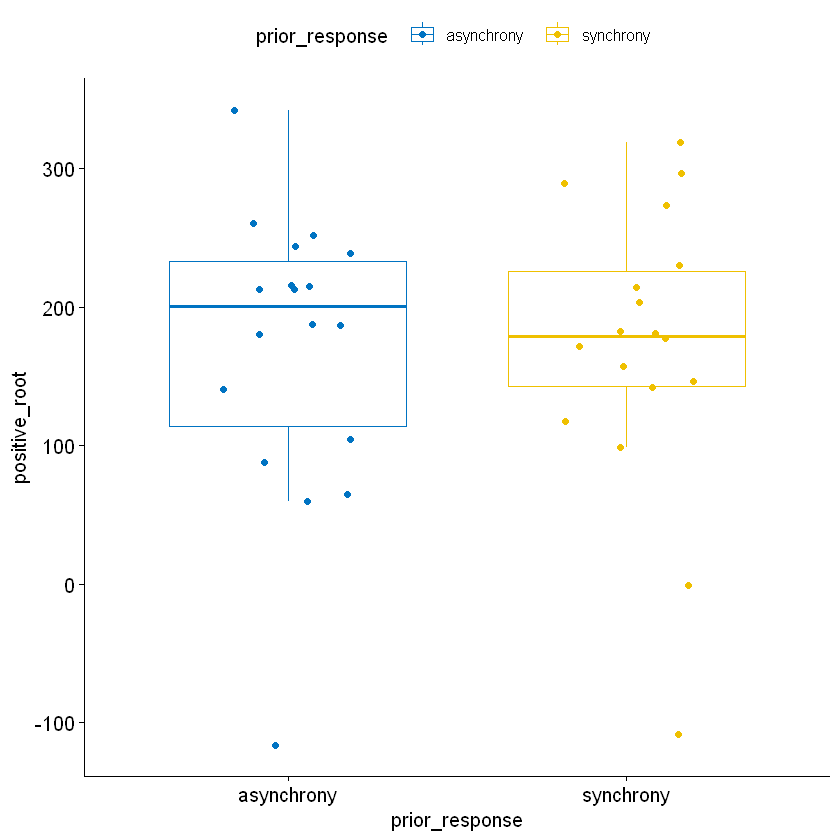

In [51]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_response", y = "positive_root",
  color = "prior_response", palette = "jco", add = "jitter"
  )

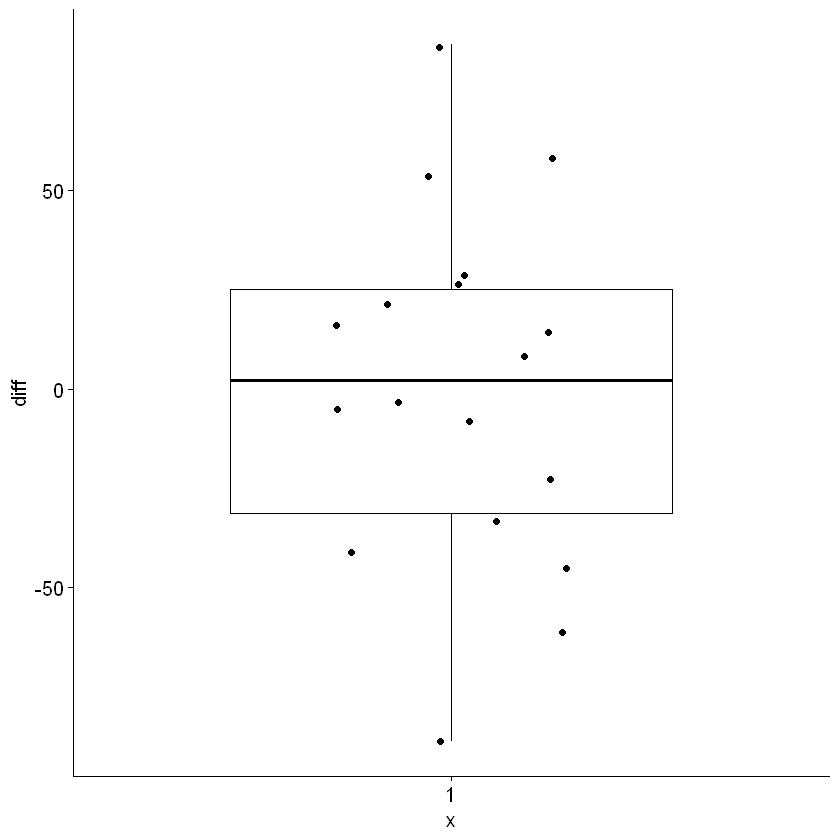

In [52]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [53]:
sigmoid_results %>% t_test(positive_root ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,0.02765578,positive_root,asynchrony,synchrony,18,18,0.002651498,0.998,17,-21.97824,22.03355,T-test,two.sided


In [54]:
sigmoid_results %>% cohens_d(positive_root ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,positive_root,asynchrony,synchrony,0.0006249642,18,18,negligible


###############################################################
## 2-4 Testing change in negative root

In [55]:
sigmoid_results <- read_xlsx("files/SJ_prior_response_sensory_bias.xlsx")

In [56]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = negative_root[prior_response == "synchrony"] - negative_root[prior_response == "asynchrony"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,-19.774800
3,7.436196
4,-51.443200
5,44.237700
7,-35.811400
8,-32.668200


In [57]:
#summary
sigmoid_results %>% group_by(prior_response) %>%  get_summary_stats(negative_root)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchrony,negative_root,18,-403.726,-115.968,-269.553,-304.485,-214.392,90.093,63.102,-260.562,66.121,15.585,32.881
synchrony,negative_root,18,-376.273,-108.532,-263.199,-285.297,-228.686,56.611,50.535,-261.556,61.900,14.590,30.782


In [58]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-74.465,131.059,-7.216,-35.026,34.097,69.122,47.874,-0.994,52.363,12.342,26.039


In [59]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [60]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [61]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9391863,0.2806286


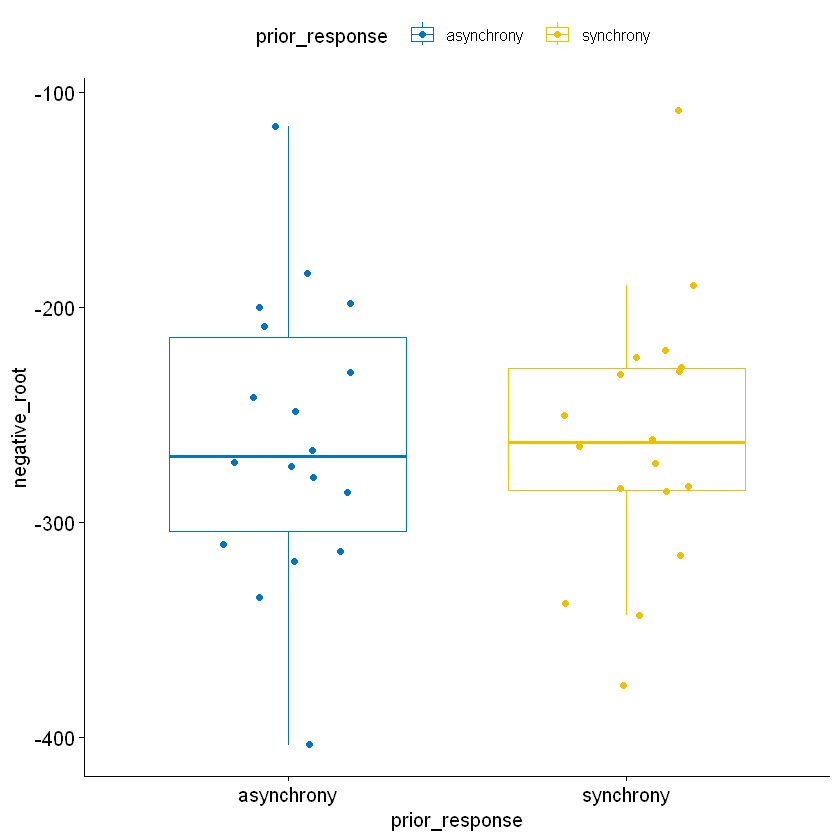

In [62]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_response", y = "negative_root",
  color = "prior_response", palette = "jco", add = "jitter"
  )

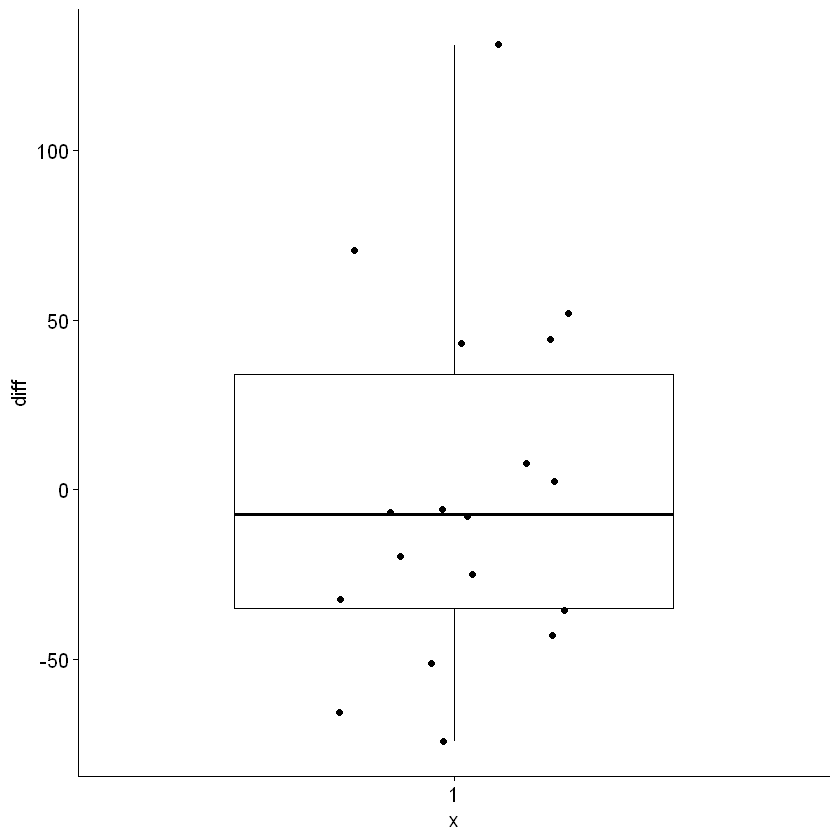

In [63]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [64]:
sigmoid_results %>% t_test(negative_root ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,0.9941391,negative_root,asynchrony,synchrony,18,18,0.08054896,0.937,17,-25.04531,27.03359,T-test,two.sided


In [65]:
sigmoid_results %>% cohens_d(negative_root ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,negative_root,asynchrony,synchrony,0.01898557,18,18,negligible


###############################################################
## 2-5 Testing change in PSS

In [66]:
sigmoid_results <- read_xlsx("files/SJ_prior_response_sensory_bias.xlsx")

In [67]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = max_snr_SOA[prior_response == "synchrony"] - max_snr_SOA[prior_response == "asynchrony"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,-7.002068
3,7.436196
4,91.081463
5,48.069234
7,-48.667610
8,-21.099175


In [68]:
#summary
sigmoid_results %>% group_by(prior_response) %>%  get_summary_stats(max_snr_SOA)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchrony,max_snr_SOA,18,-130.315,34.853,-62.387,-98.148,-43.436,54.712,32.584,-62.827,44.290,10.439,22.025
synchrony,max_snr_SOA,18,-164.248,33.984,-48.328,-68.893,-28.675,40.217,31.360,-53.800,46.004,10.843,22.877


In [69]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-105.549,91.081,11.004,-23.083,46.409,69.492,53.235,9.027,50.103,11.809,24.916


In [70]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [71]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [72]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9793948,0.9435519


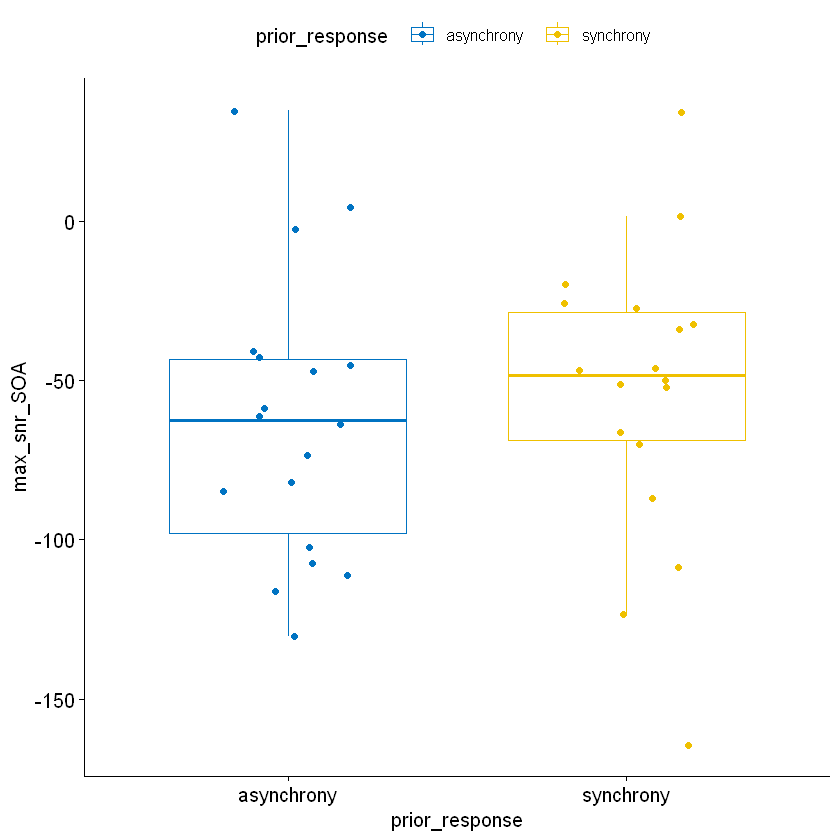

In [73]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_response", y = "max_snr_SOA",
  color = "prior_response", palette = "jco", add = "jitter"
  )

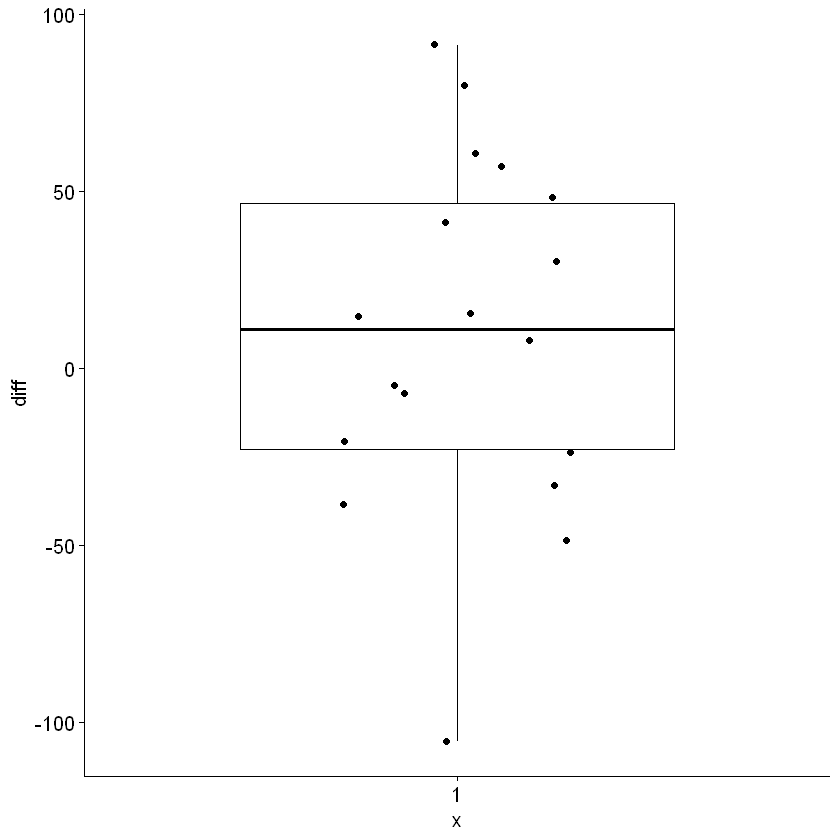

In [74]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [75]:
sigmoid_results %>% t_test(max_snr_SOA ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-9.026815,max_snr_SOA,asynchrony,synchrony,18,18,-0.7643791,0.455,17,-33.94235,15.88872,T-test,two.sided


In [76]:
sigmoid_results %>% cohens_d(max_snr_SOA ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,max_snr_SOA,asynchrony,synchrony,-0.1801659,18,18,negligible


###############################################################
## 2-6 Testing change in relative starting point

In [78]:
df_summary <- read_xlsx("files/SJ_prior_response_decision_bias.xlsx")

In [79]:
df_summary2 <- df_summary %>% group_by(ID) %>% summarise(
    diff = mean_Z[prior_response == "synchrony"] - mean_Z[prior_response == "asynchrony"],
    .groups = "drop"
  )
head(df_summary2)

ID,diff
<dbl>,<dbl>
1,0.14173781
3,-0.08595844
4,0.35379702
5,0.15789495
7,0.08502045
8,0.45142092


In [80]:
df_summary %>% group_by(prior_response) %>%  get_summary_stats(mean_Z)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchrony,mean_Z,18,-0.270,0.454,0.105,0.056,0.248,0.192,0.141,0.138,0.178,0.042,0.089
synchrony,mean_Z,18,0.061,0.579,0.238,0.126,0.366,0.239,0.186,0.259,0.155,0.037,0.077


In [81]:
df_summary2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-0.314,0.451,0.15,-0.028,0.294,0.322,0.26,0.121,0.217,0.051,0.108


In [82]:
#identify outlier
dd <- df_summary2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [83]:
#Removing outliers data
df_summary <- df_summary %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
df_summary2 <- df_summary2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [84]:
# normality
df_summary2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9713979,0.823531


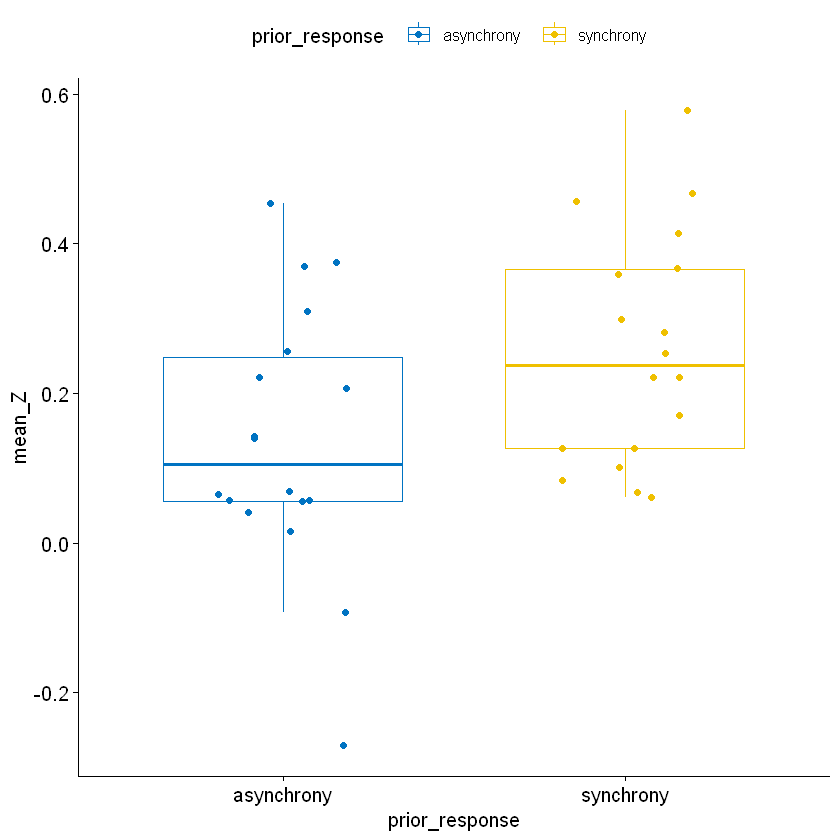

In [85]:
#plot
ggboxplot(
  df_summary, x = "prior_response", y = "mean_Z",
  color = "prior_response", palette = "jco", add = "jitter"
  )

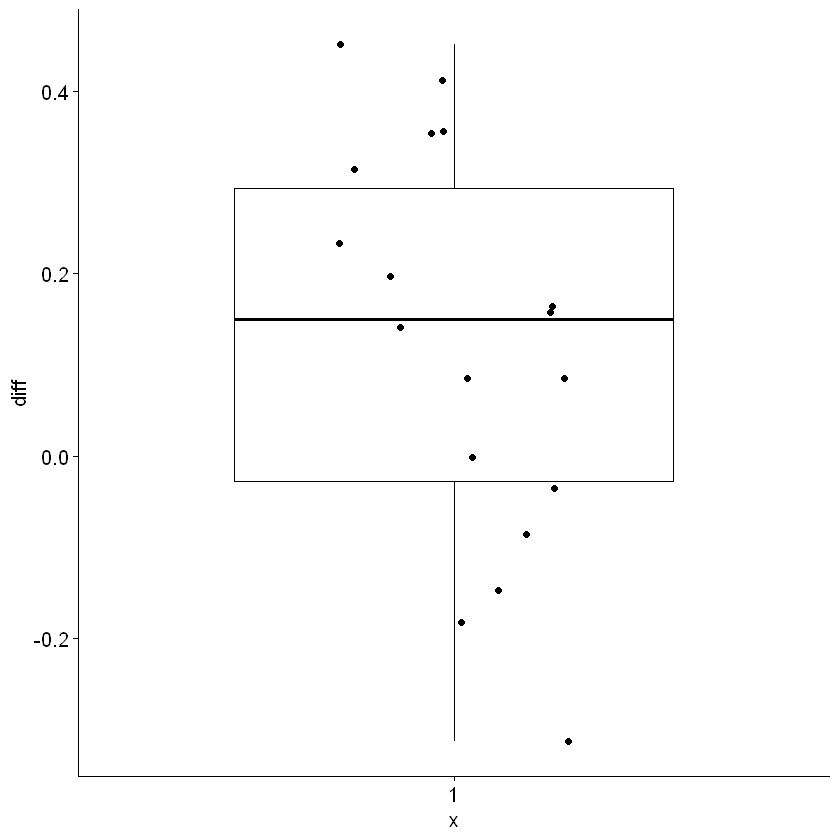

In [86]:
ggboxplot(
  df_summary2, y = "diff", palette = "jco", add = "jitter"
  )

In [87]:
df_summary %>% t_test(mean_Z ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-0.1213822,mean_Z,asynchrony,synchrony,18,18,-2.371131,0.0298,17,-0.2293872,-0.01337719,T-test,two.sided


In [88]:
df_summary %>% cohens_d(mean_Z ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,mean_Z,asynchrony,synchrony,-0.558881,18,18,moderate


###############################################################\
###############################################################
# 3- Prior stimulus
**List of contents:**\
3-1 Plotting SNR curves\
3-2 Calculating sensory and decisional bias\
3-3 Testing change in positive root\
3-4 Testing change in negative root\
3-5 Testing change in PSS\
3-6 Testing change in relative starting point

In [100]:
df_stim <- read_xlsx("files/SJ_prior_stimulus_DDM_parameters_clean.xlsx")

# Rename first columns for clarity
colnames(df_stim)[1] <- "ID"
colnames(df_stim)[2] <- "prior_stimulus"

# ---------------------------------------------------------
# Compute Signal-to-Noise Ratio (SNR)
# SNR = drift rate (v) / noise (σ)
# This quantity reflects the quality of sensory evidence
# accumulation and is used as an index of sensory bias.
# ---------------------------------------------------------
df_stim$snr <- df_stim$drift / df_stim$noise

###############################################################
## 3-1 Plotting SNR curves

In [96]:
head(df_stim)

ID,prior_stimulus,SOA,drift,noise,bound,Z,t0,snr
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory leading,-400,-1.784220,0.7997914,1,-0.6509527,0.893149623,-2.230856
1,auditory leading,-300,-2.103204,0.6424279,1,0.1536665,0.602372726,-3.273836
1,auditory leading,-250,-1.343105,1.1378230,1,0.5991456,0.648676422,-1.180417
1,auditory leading,-200,1.422506,1.2518347,1,0.3322775,0.469702103,1.136337
1,auditory leading,-150,1.176233,0.3409587,1,-0.1000472,0.003964922,3.449780
1,auditory leading,-120,1.312088,0.3859983,1,-0.1041779,0.003425843,3.399207


In [97]:
df_stim <- df_stim %>%
  mutate(prior_stimulus = recode(prior_stimulus,
    "auditory_leading" = "auditory leading",
    "visual_leading" = "visual leading"
  ))

In [98]:
summary_stim <- df_stim %>%
  group_by(SOA, prior_stimulus) %>%
  summarise(
    mean_snr = mean(snr, na.rm = TRUE),
    se_snr = sd(snr, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [99]:
df_predicted = data.frame()
for (participant in unique(df_stim$ID)) {
    for (condition in unique(df_stim$prior_stimulus)) {
        df_stim_subset <- df_stim %>% filter(ID == participant, prior_stimulus == condition)

        model <- scam(snr ~ s(SOA, bs = "cv"), data = df_stim_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }
        df <- data.frame(ID=participant, prior_stimulus=condition, SOA = -400:400, snr=ff(-400:400))
        df_predicted <- rbind(df_predicted, df)
}}

In [16]:
df_predicted_summary <- df_predicted %>%
  group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_snr = mean(snr),
    se = sd(snr) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

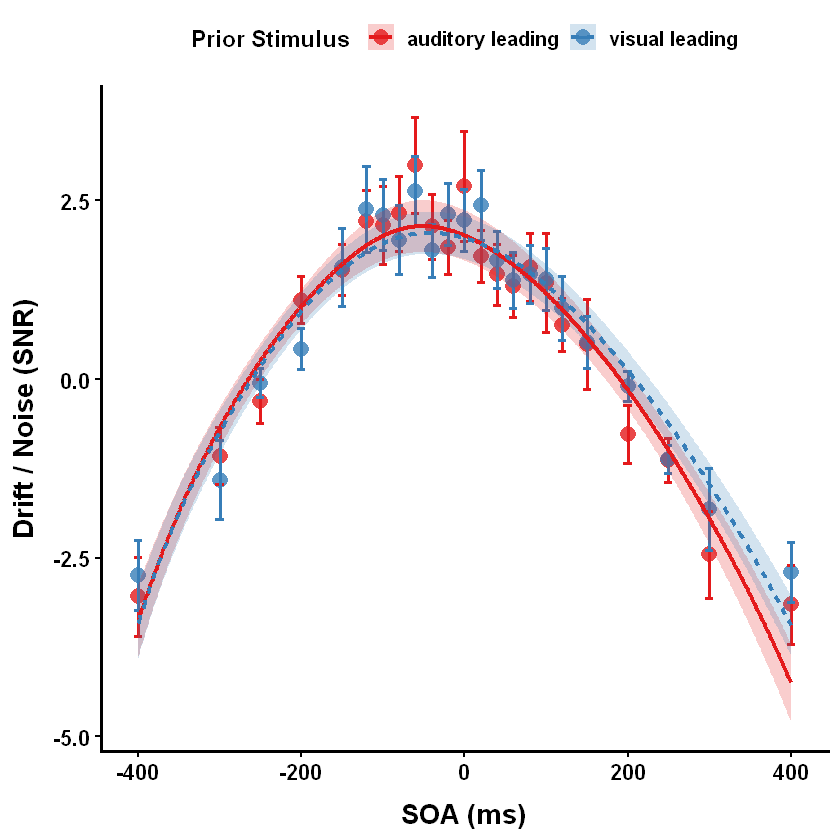

In [17]:
# save as PDF
pdf(file="figures/SJ_prior_stimulus_snr.pdf", width = 10, height = 8)  

# Create the plot with publication-style formatting
p_sj_prior_stim <- ggplot() +
  # Plot observed data points
  geom_point(
    data = summary_stim,
    aes(x = SOA, y = mean_snr, color = prior_stimulus),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +

  # Add error bars for observed data
  geom_errorbar(
    data = summary_stim,
    aes(
      x = SOA,
      ymin = mean_snr - se_snr,
      ymax = mean_snr + se_snr,
      color = prior_stimulus
    ),
    width = 10,
    linewidth = 1
  ) +

  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_snr - se,
      ymax = mean_snr + se,
      fill = prior_stimulus,
      group = prior_stimulus
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_snr,
      color = prior_stimulus,
      linetype = prior_stimulus,
      group = prior_stimulus
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Drift / Noise (SNR)",
    color = "Prior Stimulus",
    linetype = "Prior Stimulus",
    fill = "Prior Stimulus"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_sj_prior_stim
dev.off()
# 3. Display the plot
print(p_sj_prior_stim)

###############################################################
## 3-2 Calculating sensory and decisional bias

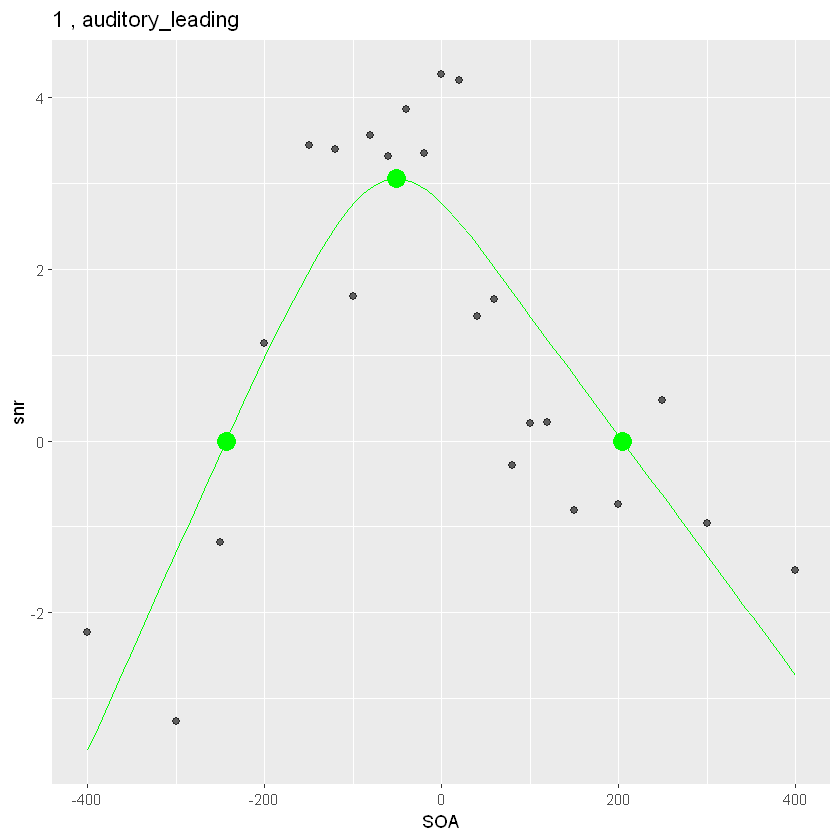

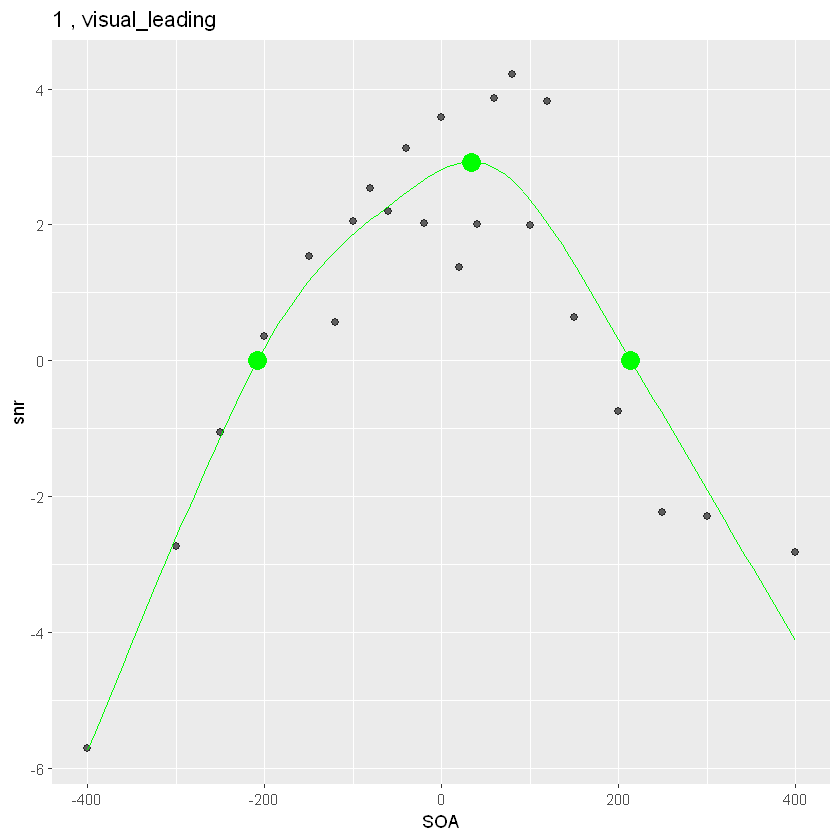

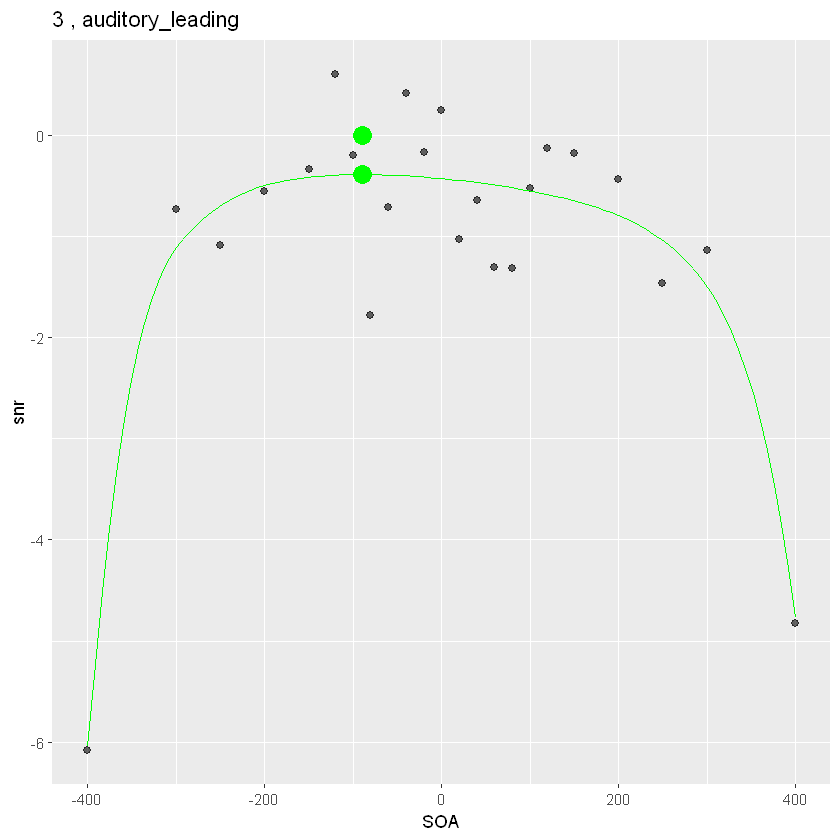

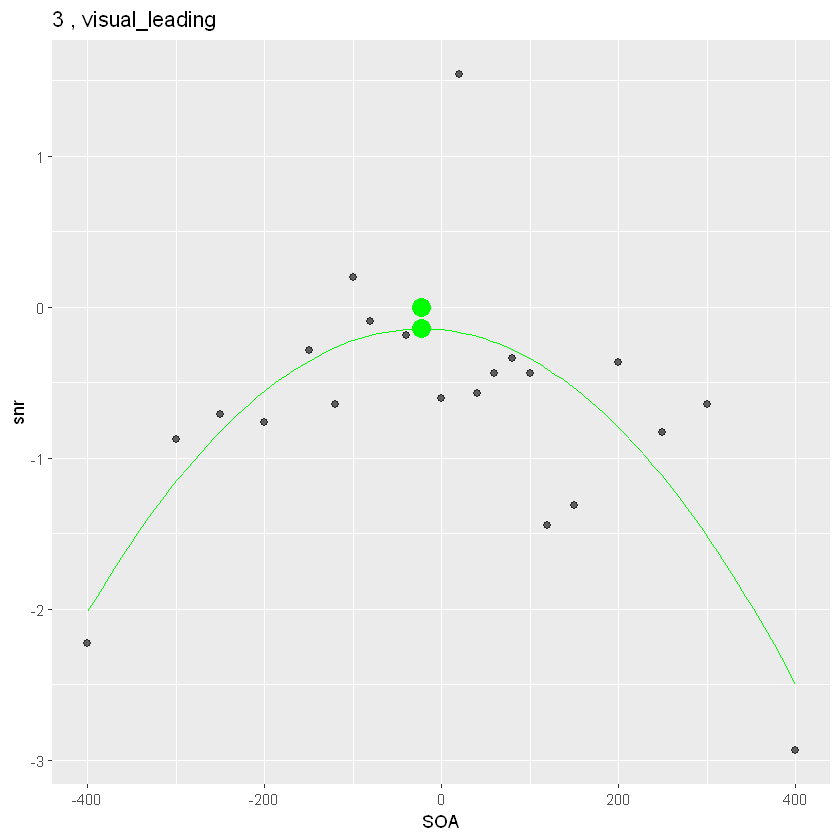

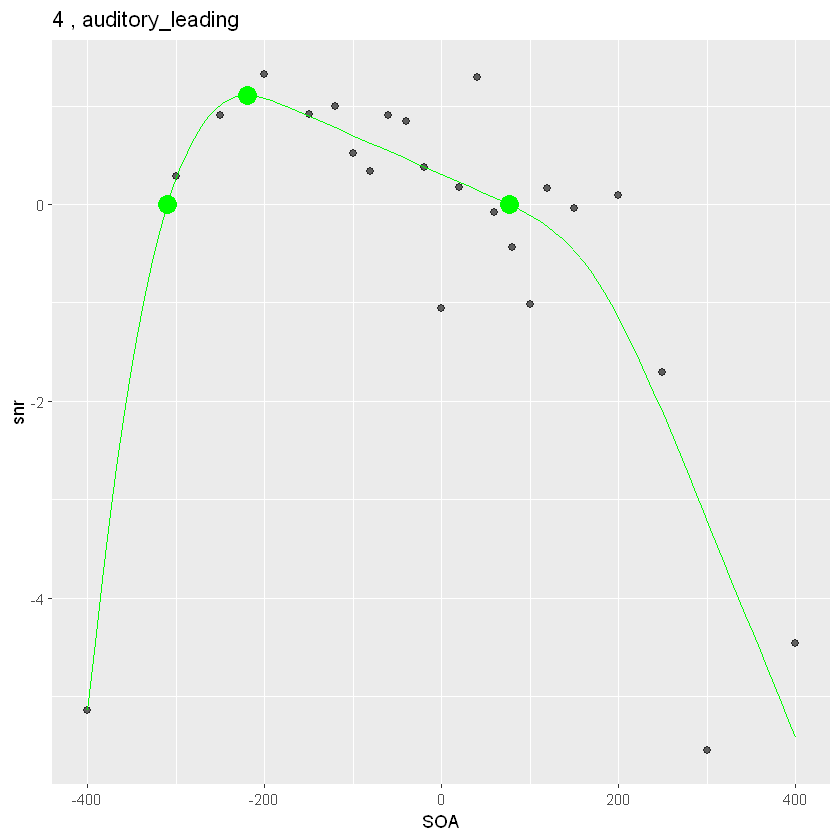

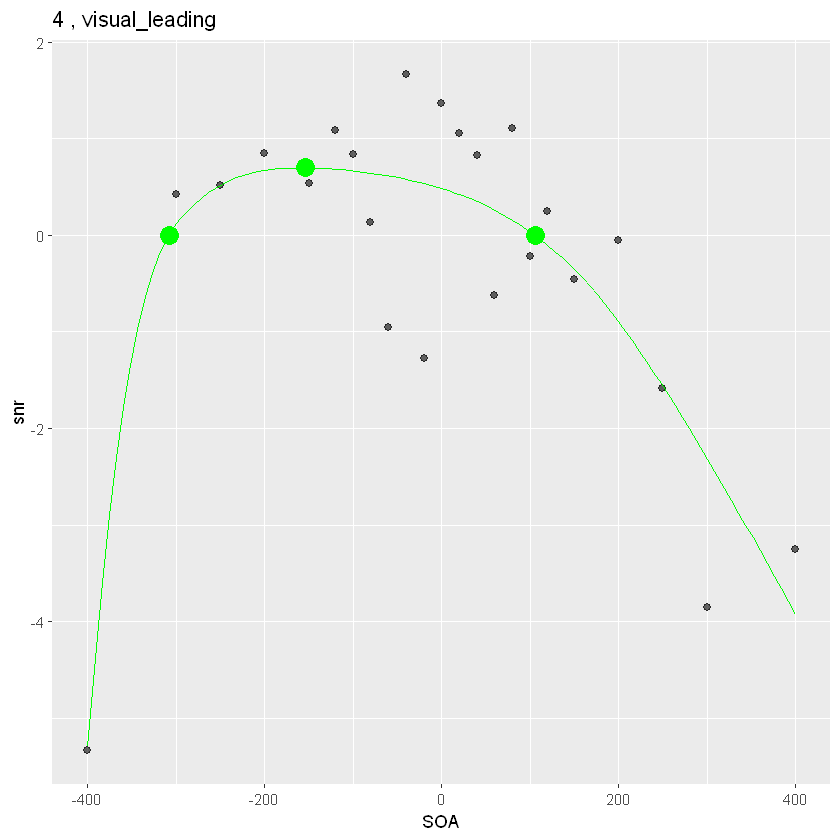

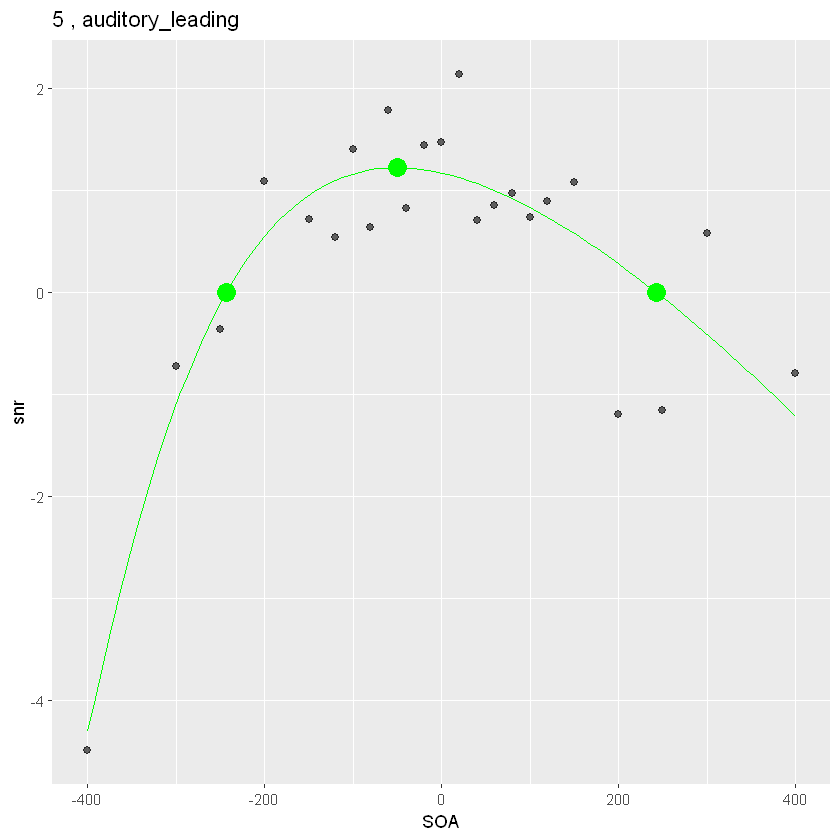

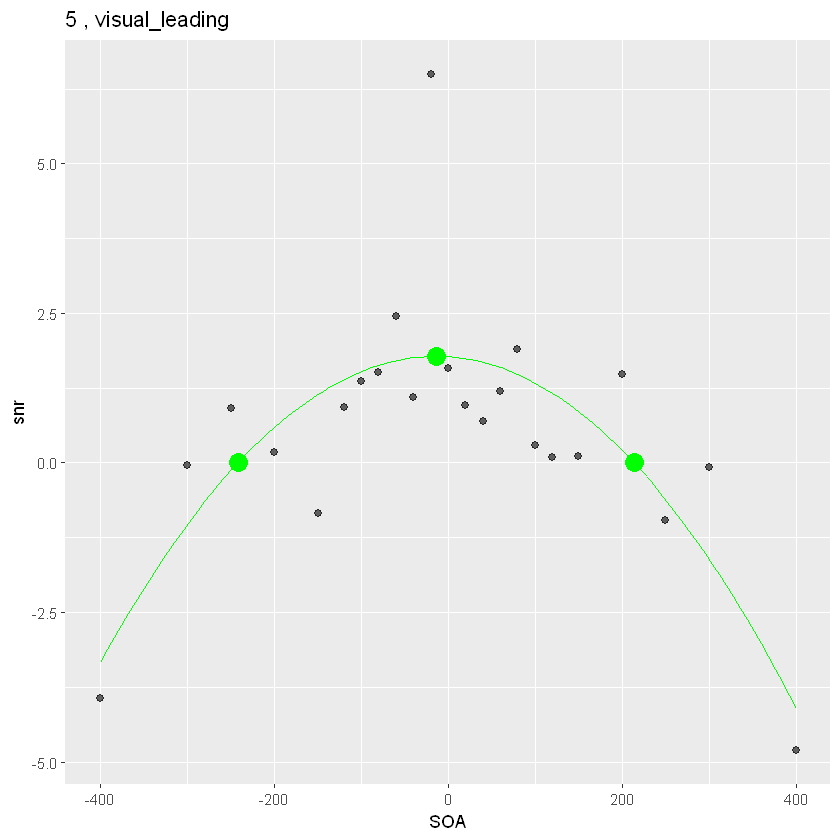

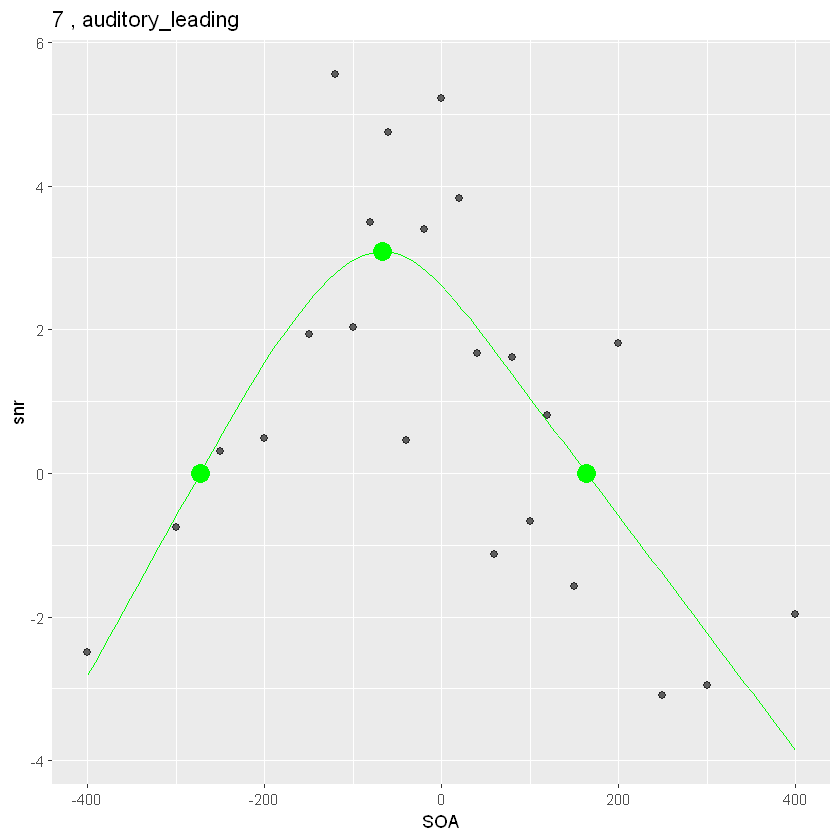

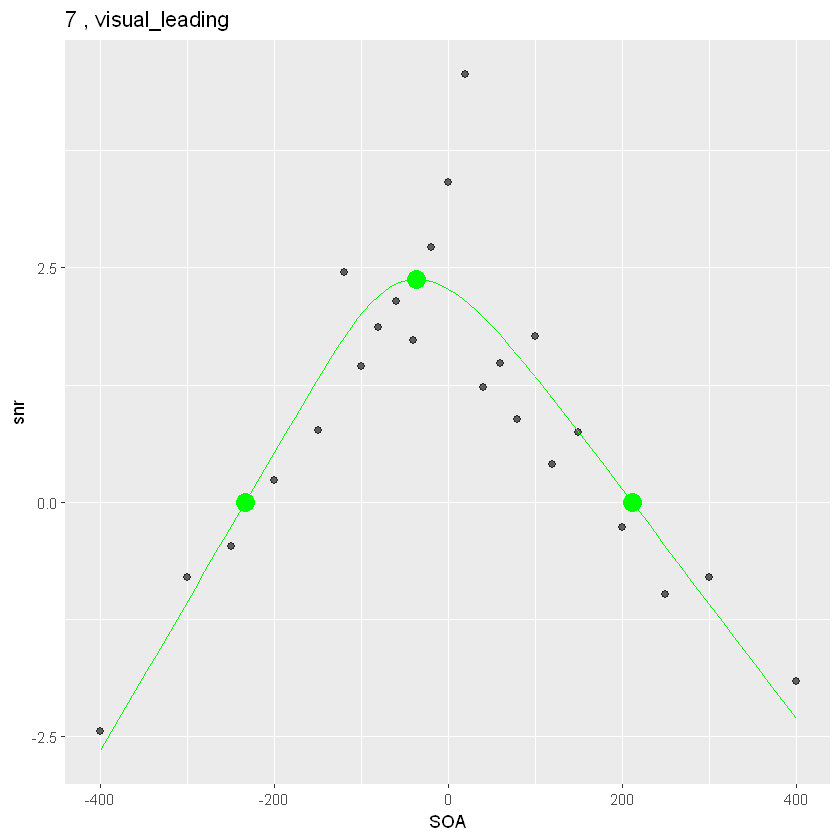

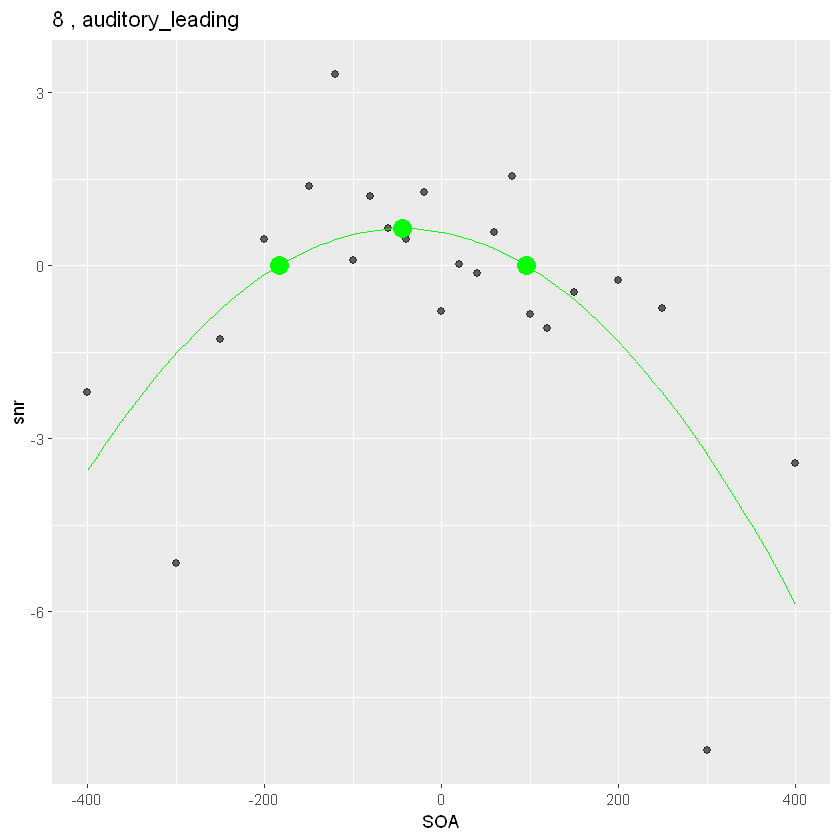

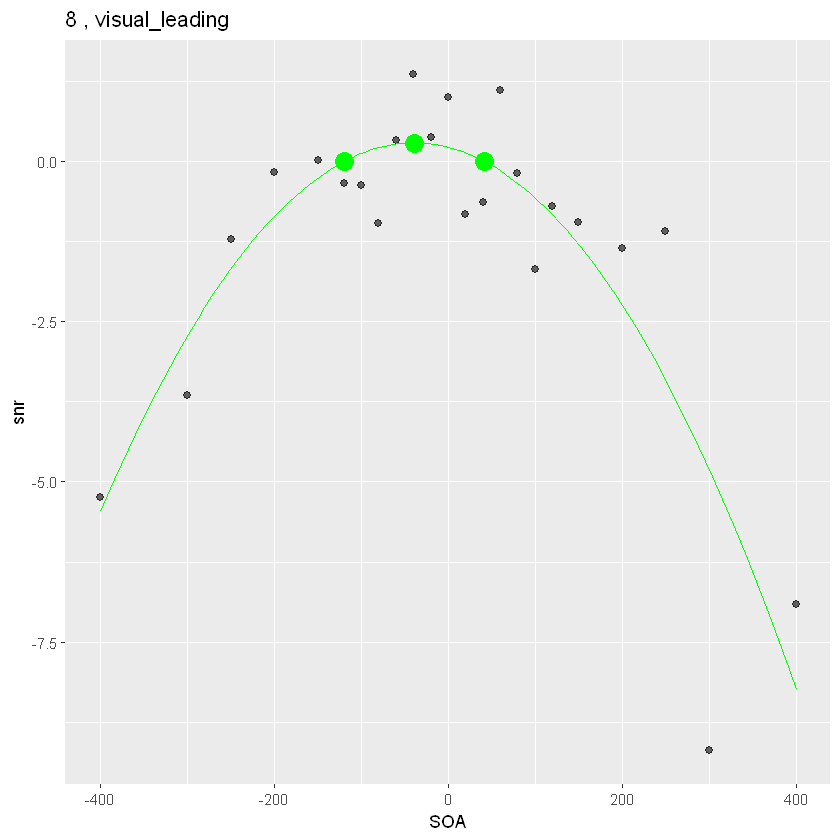

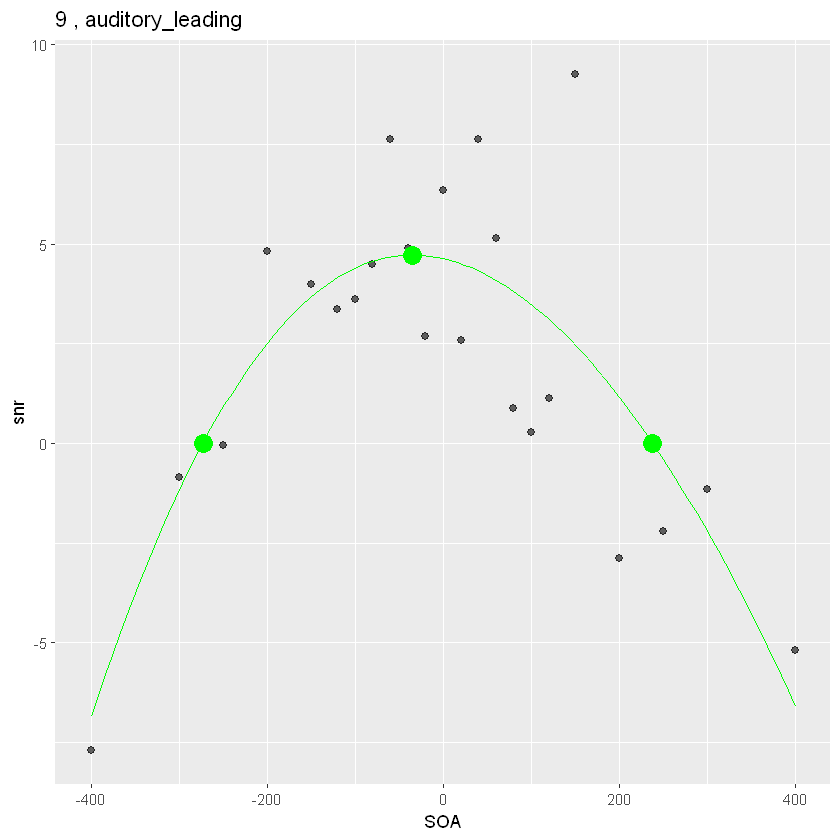

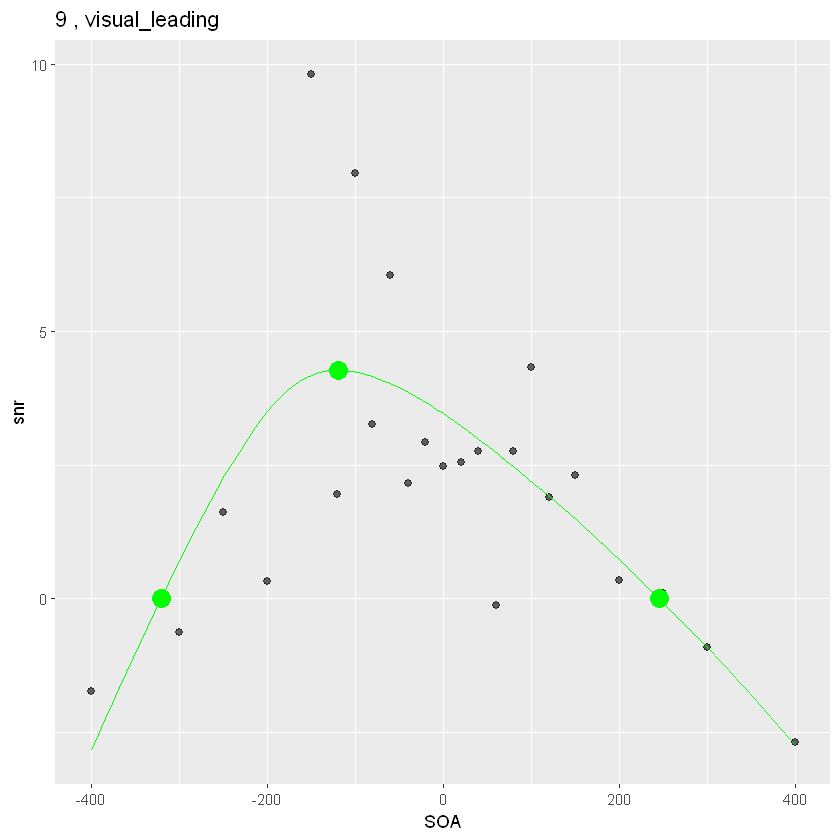

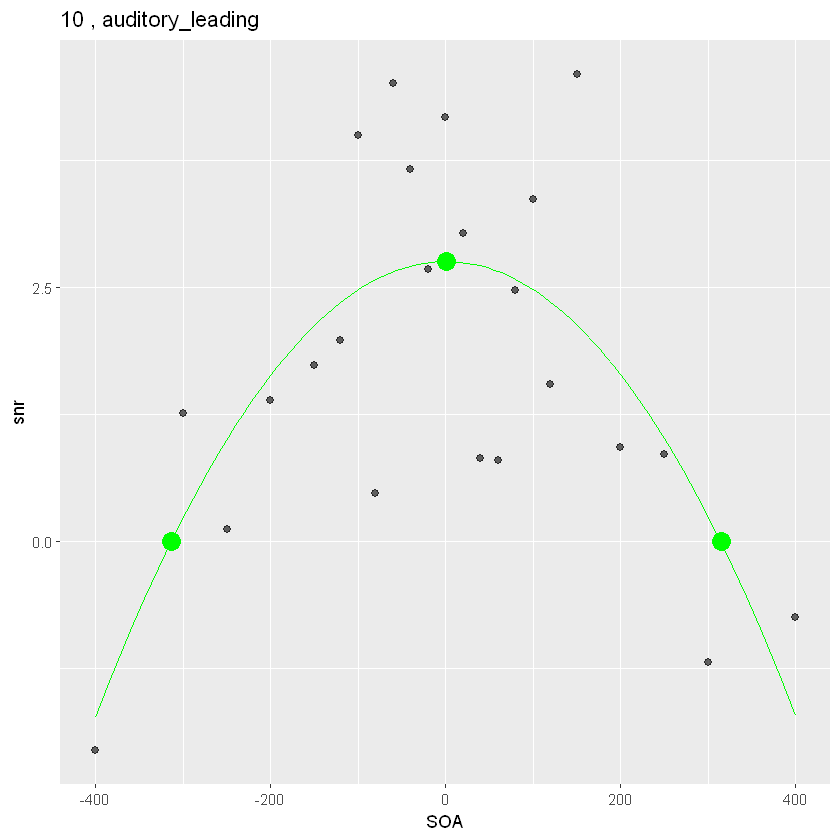

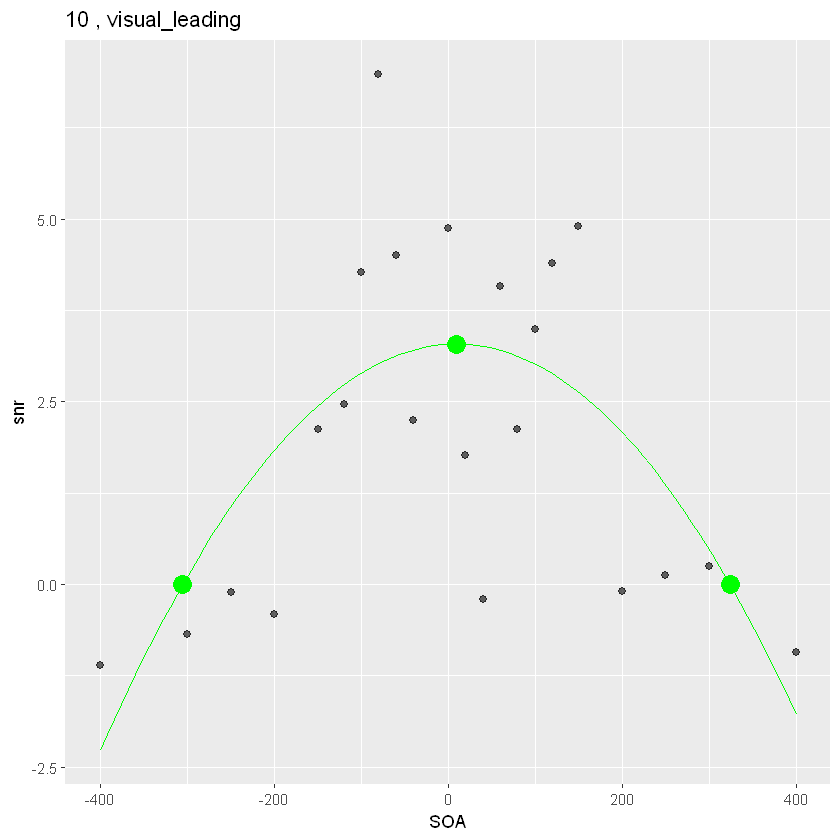

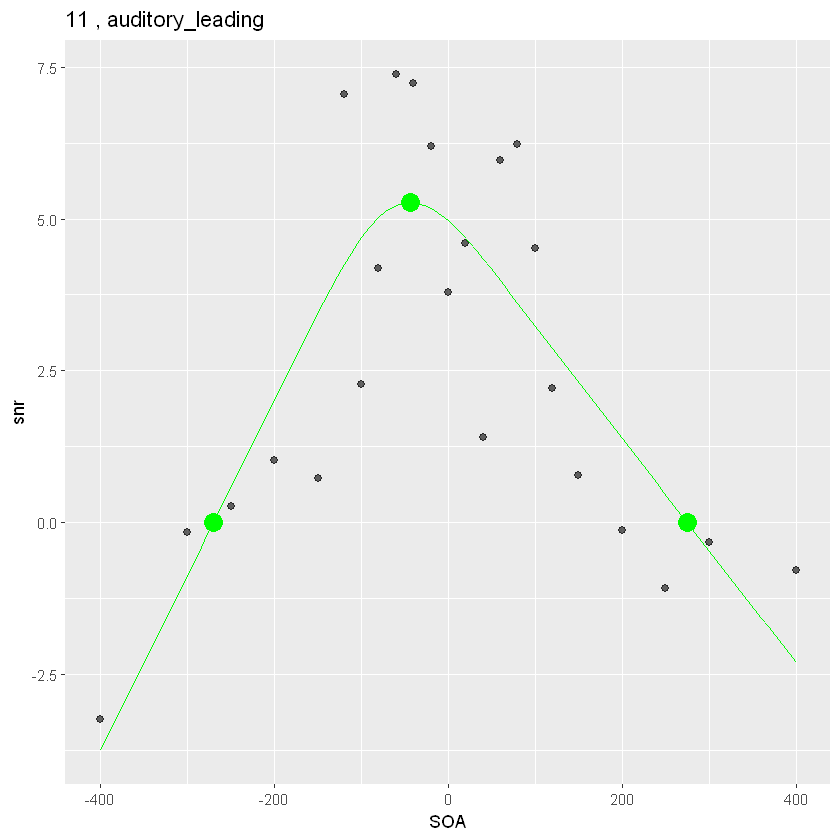

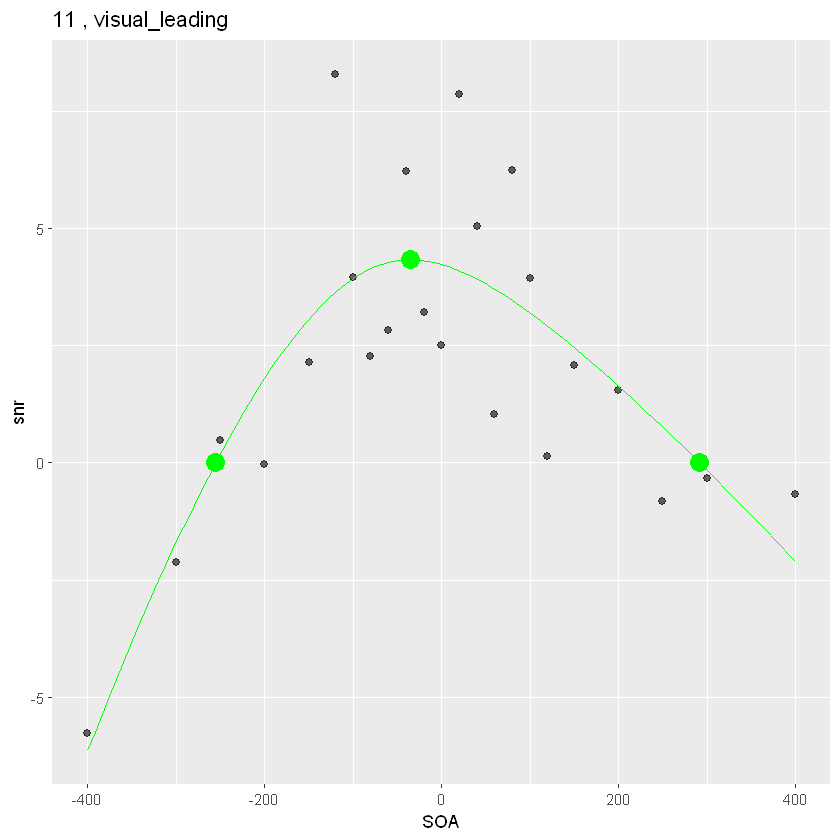

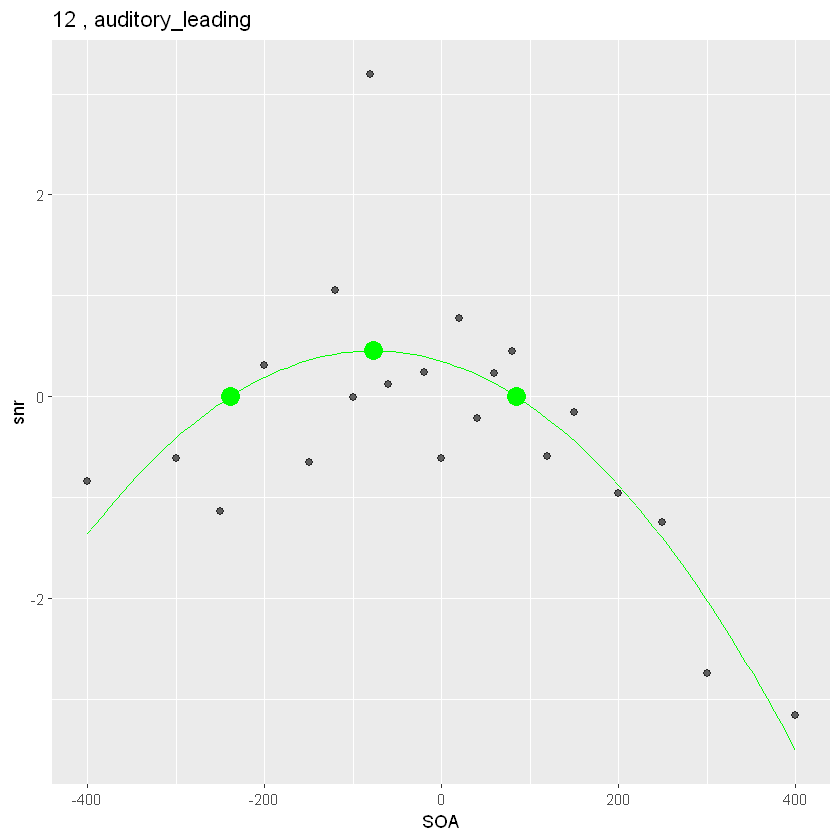

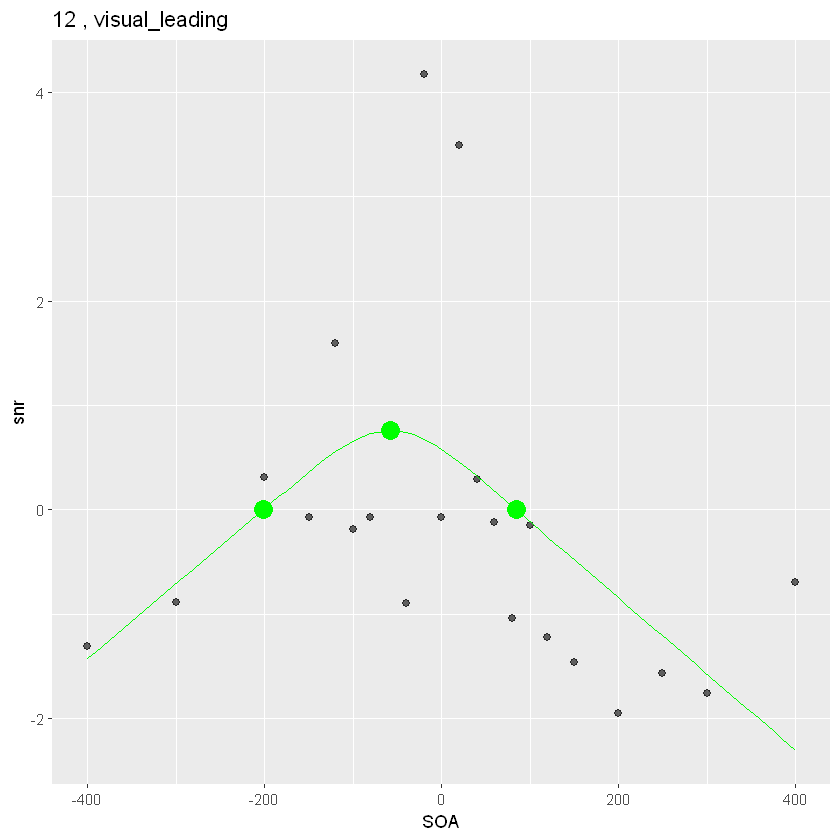

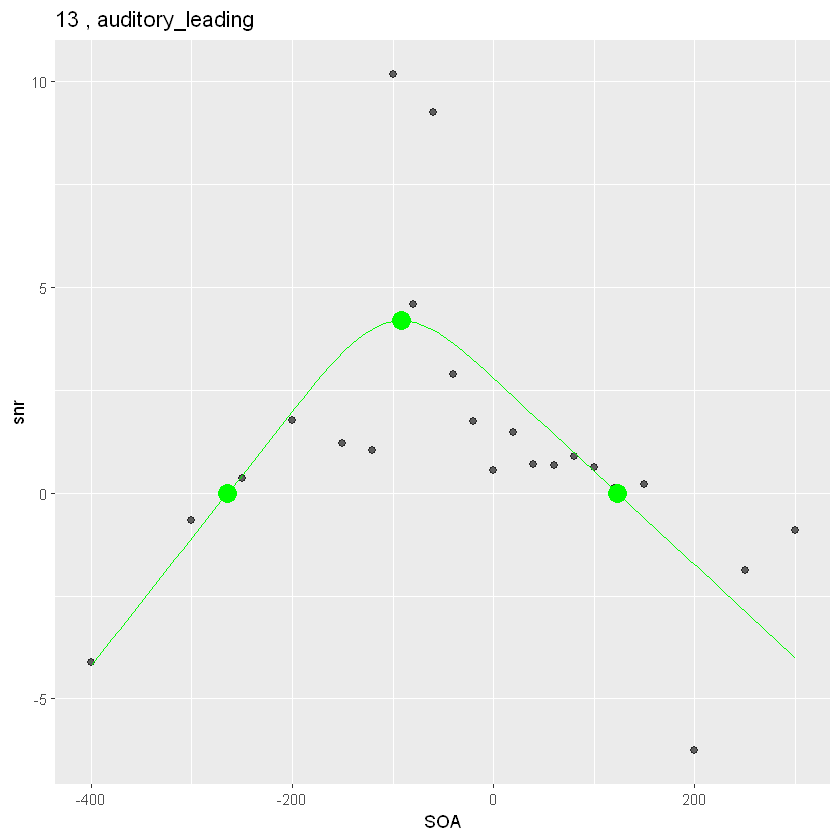

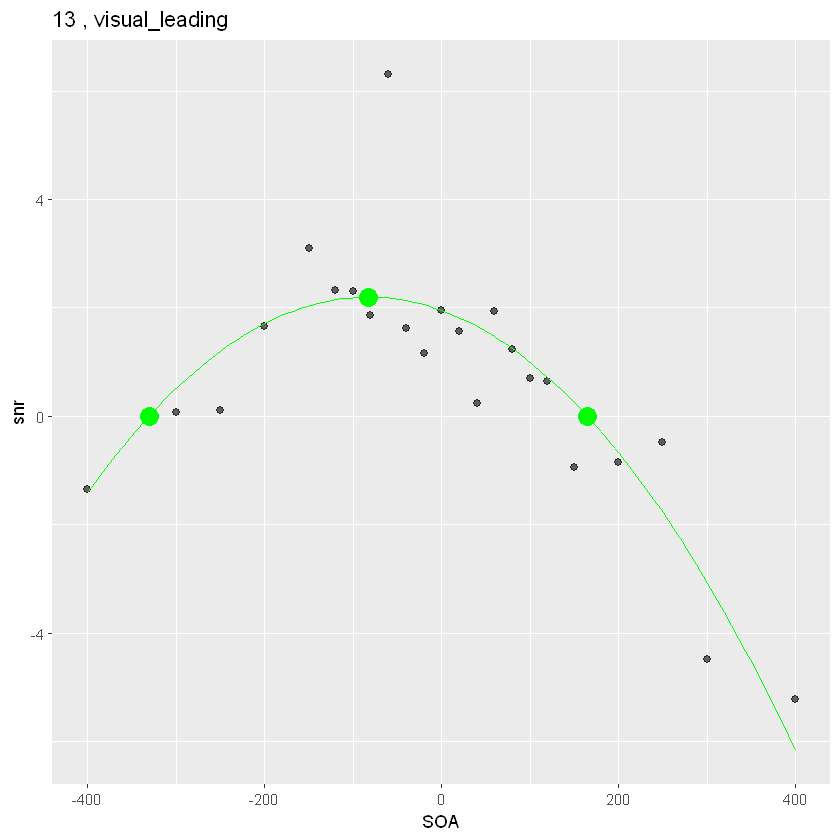

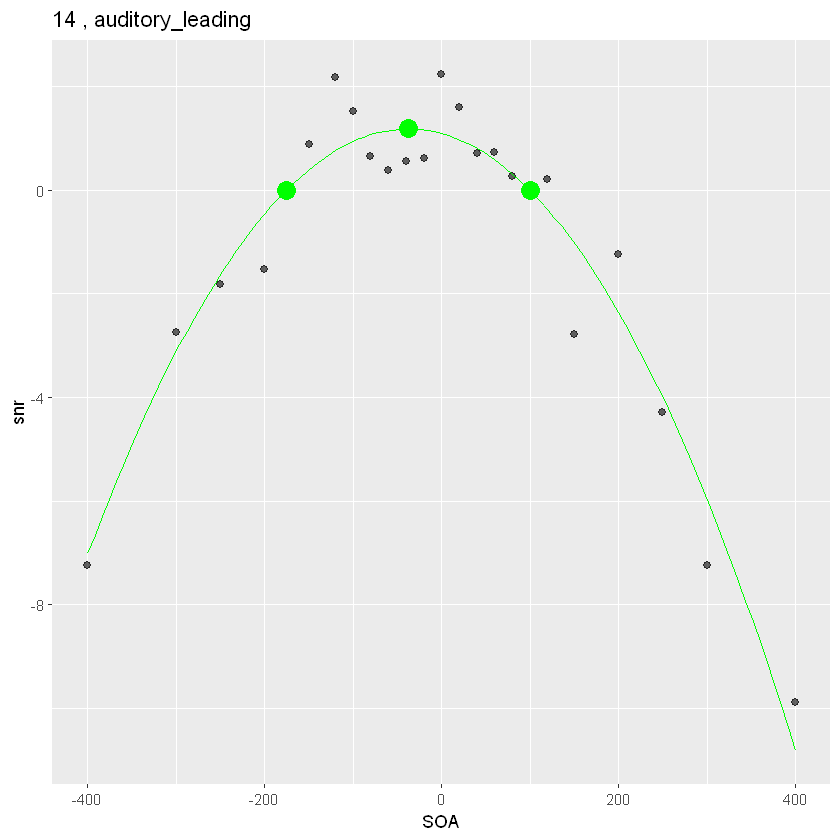

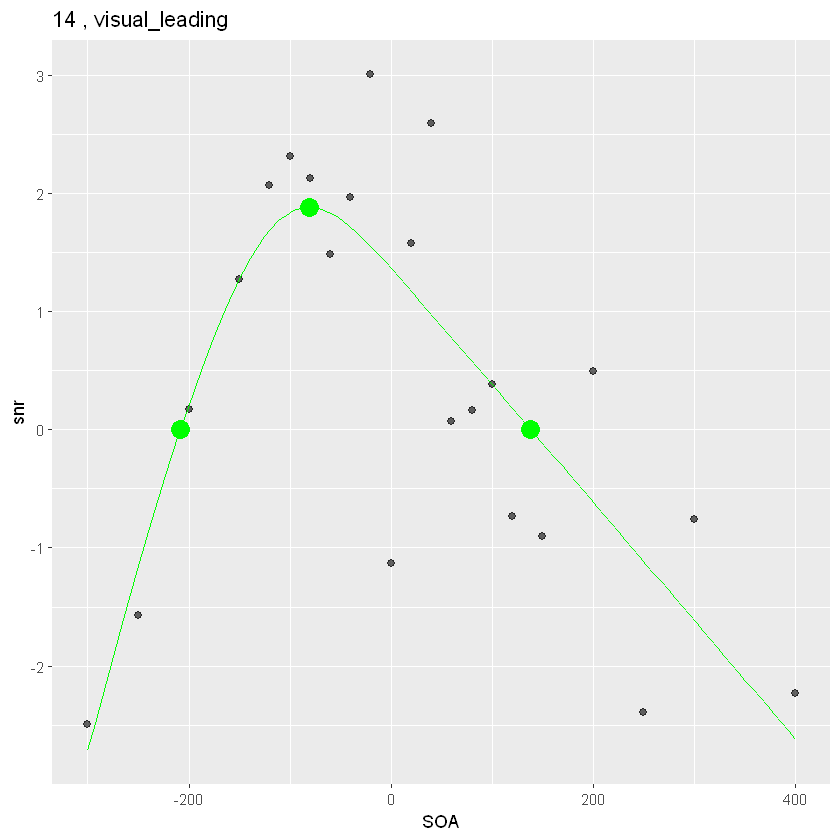

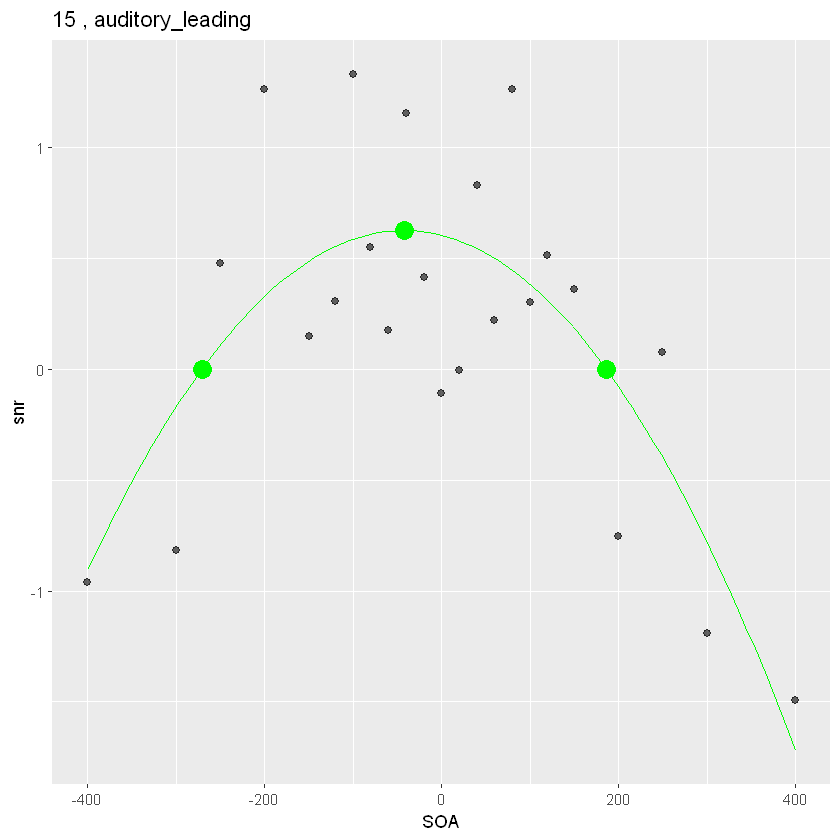

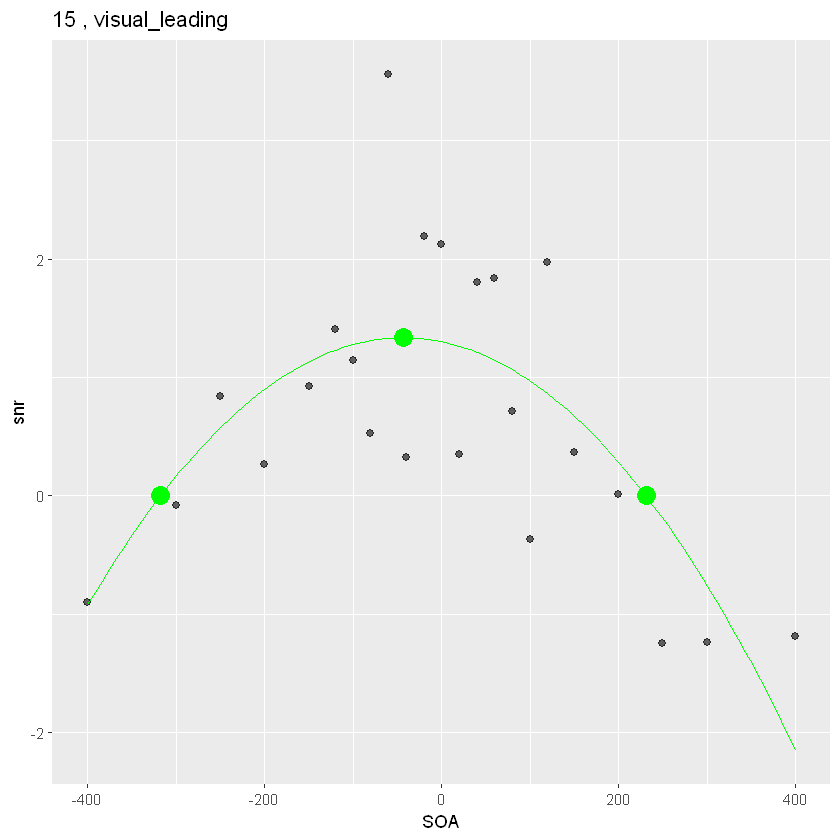

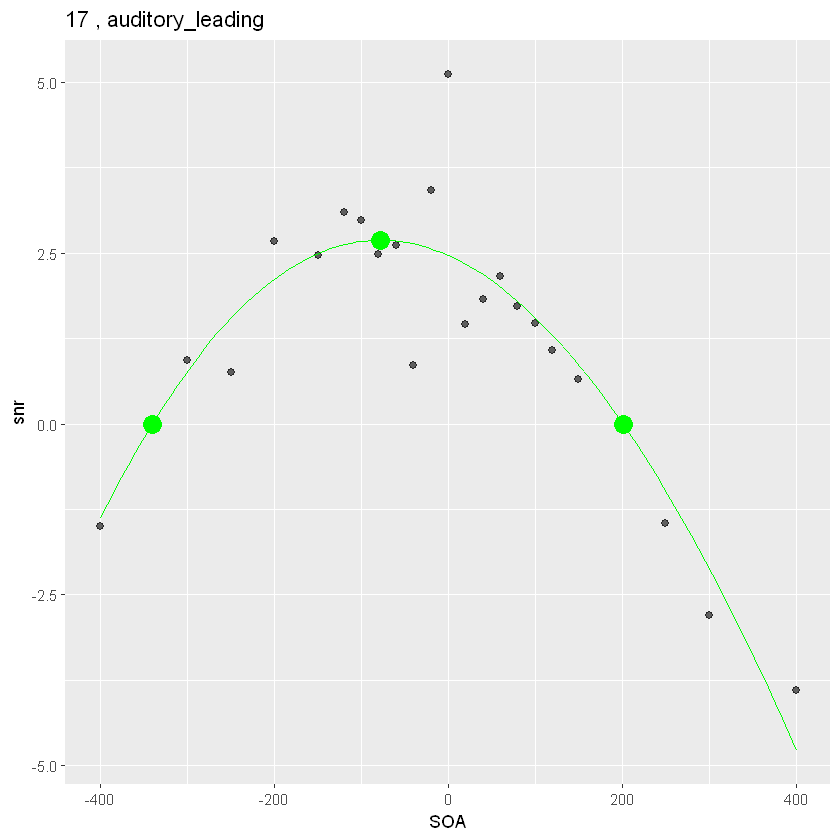

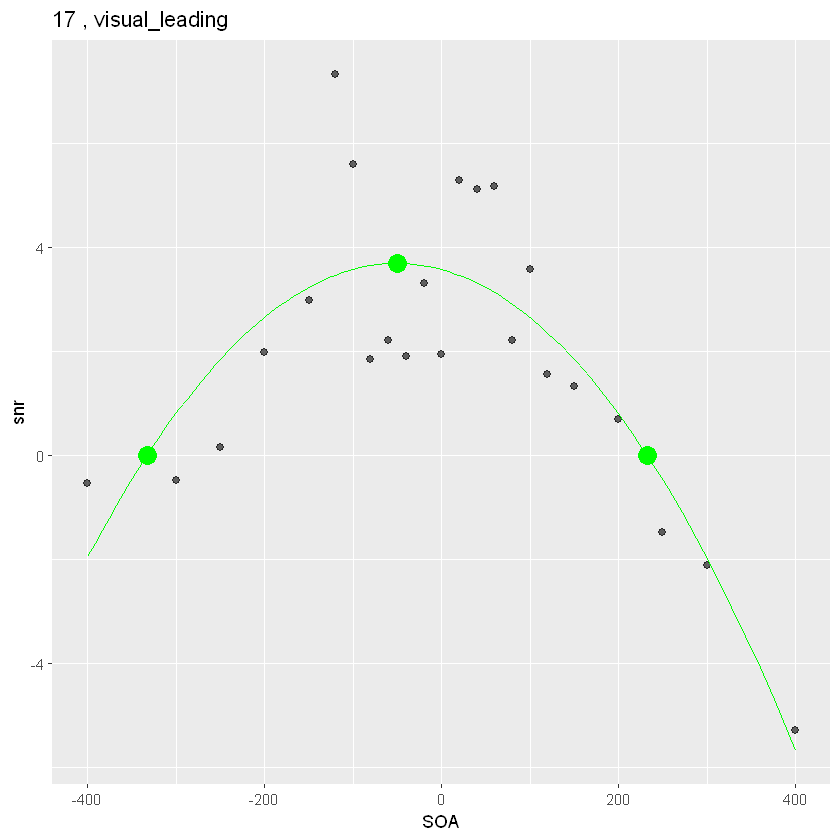

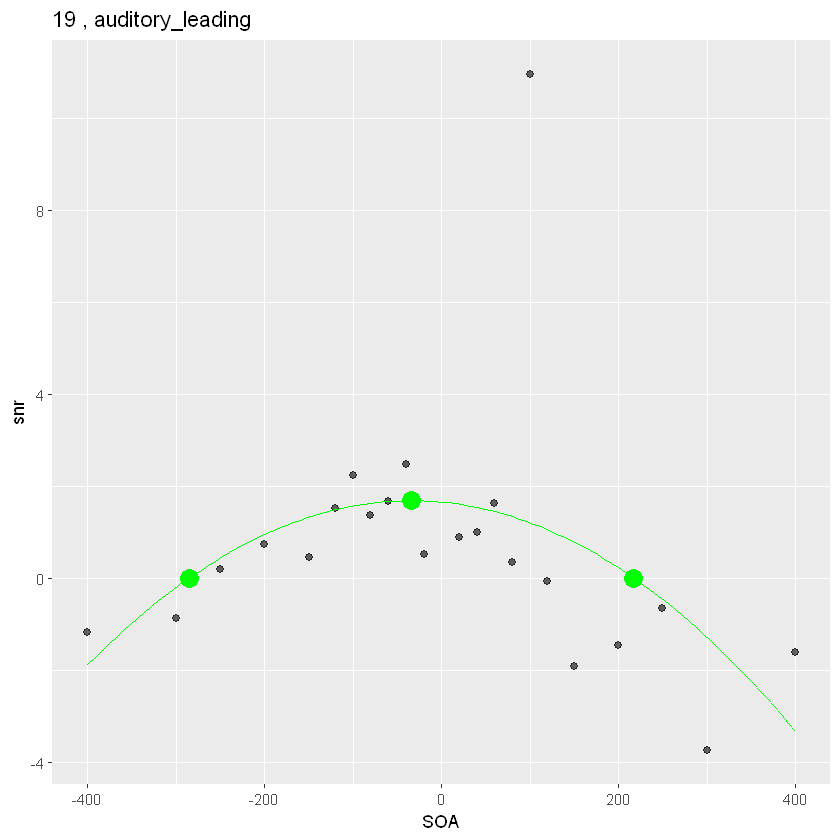

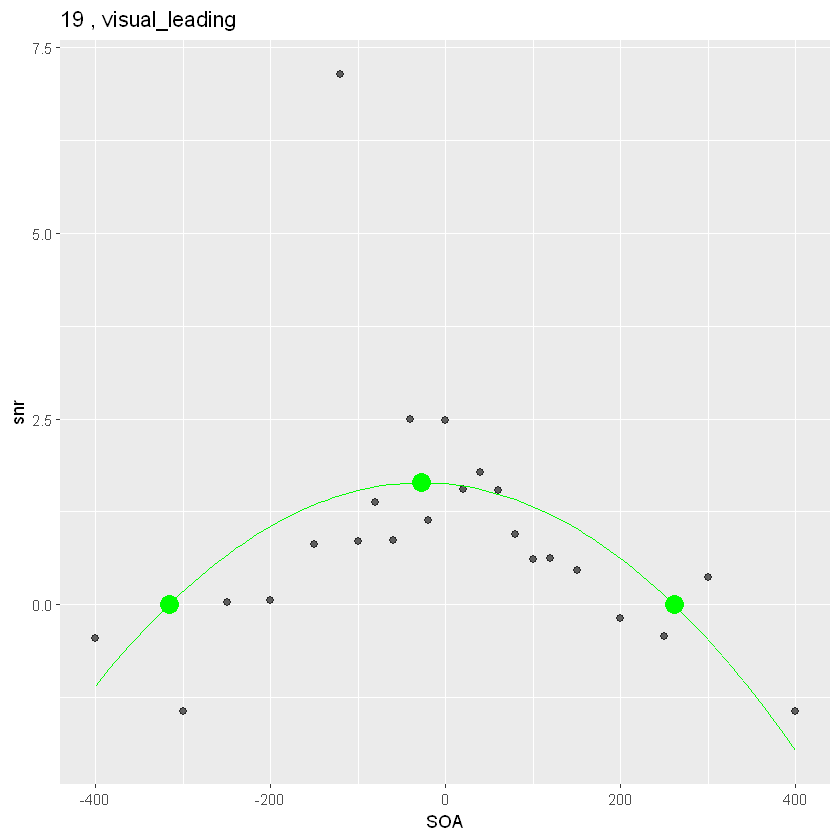

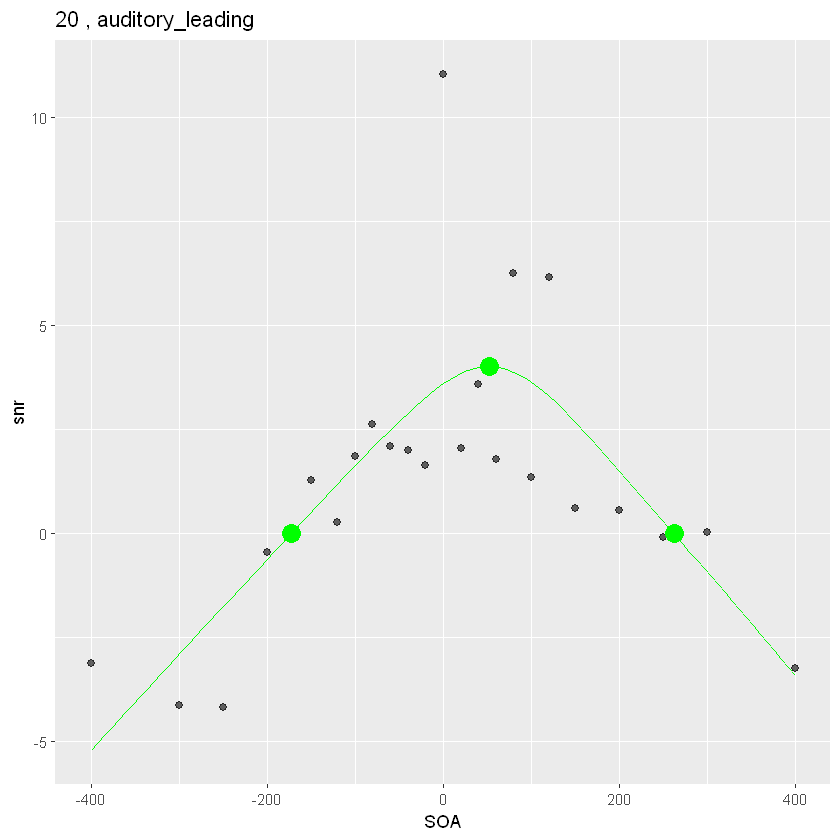

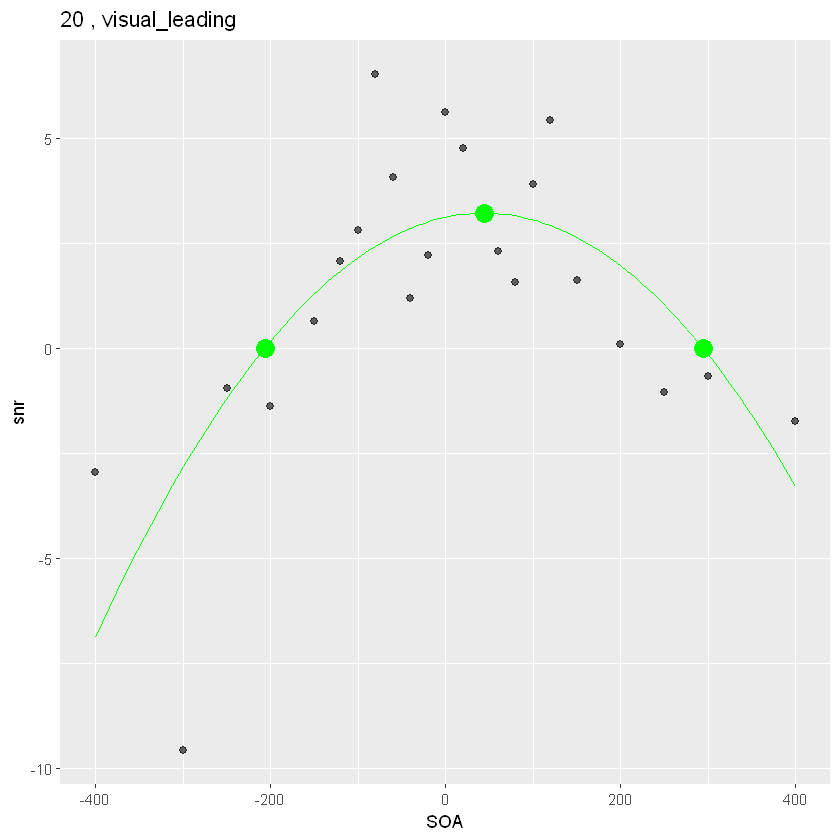

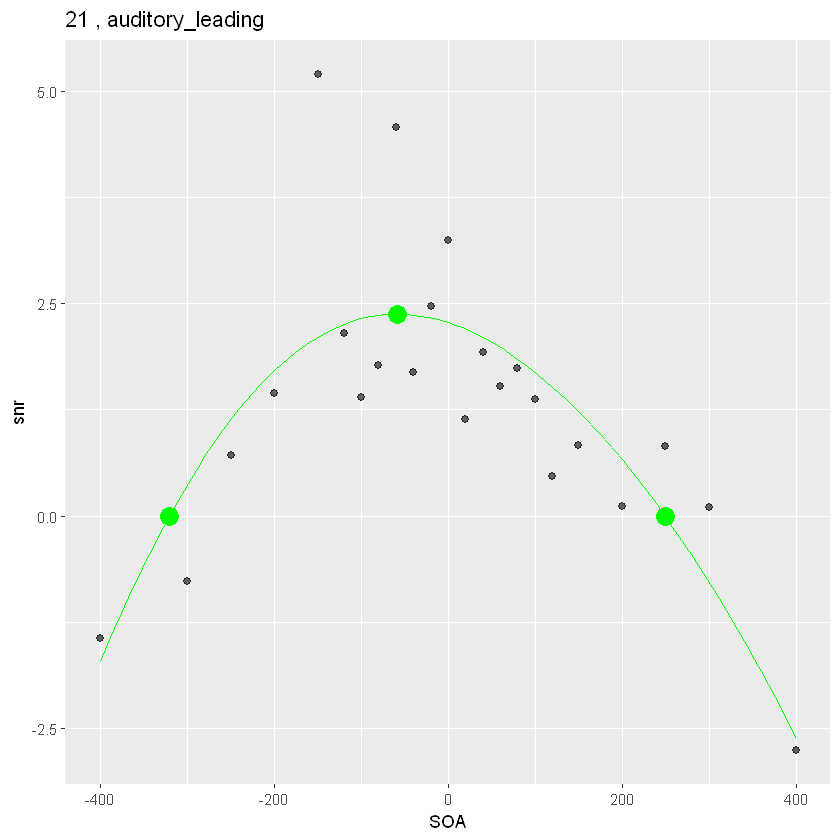

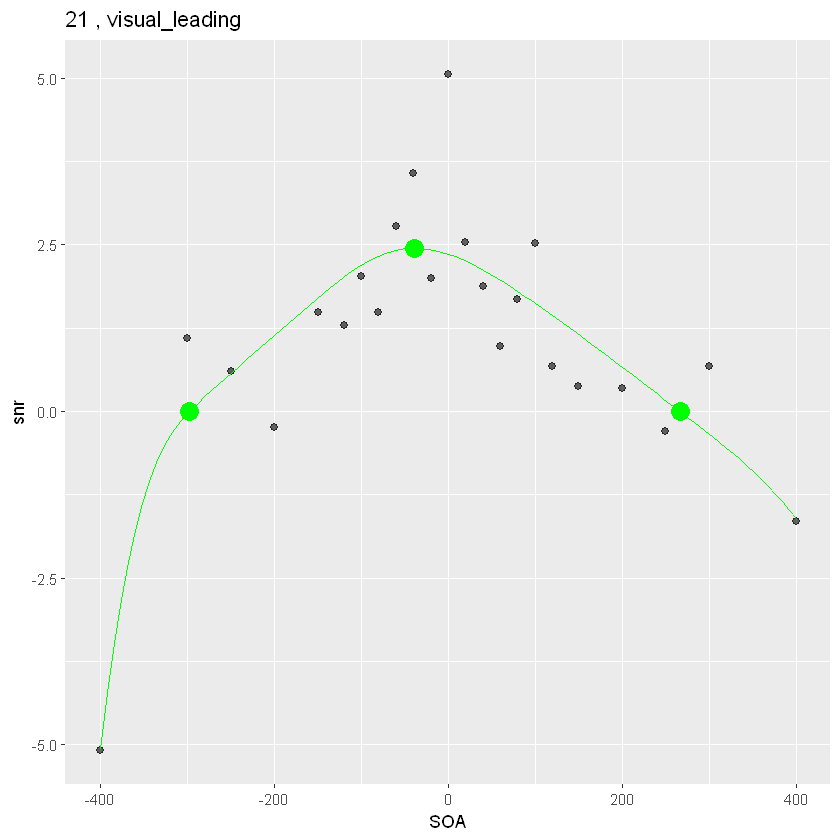

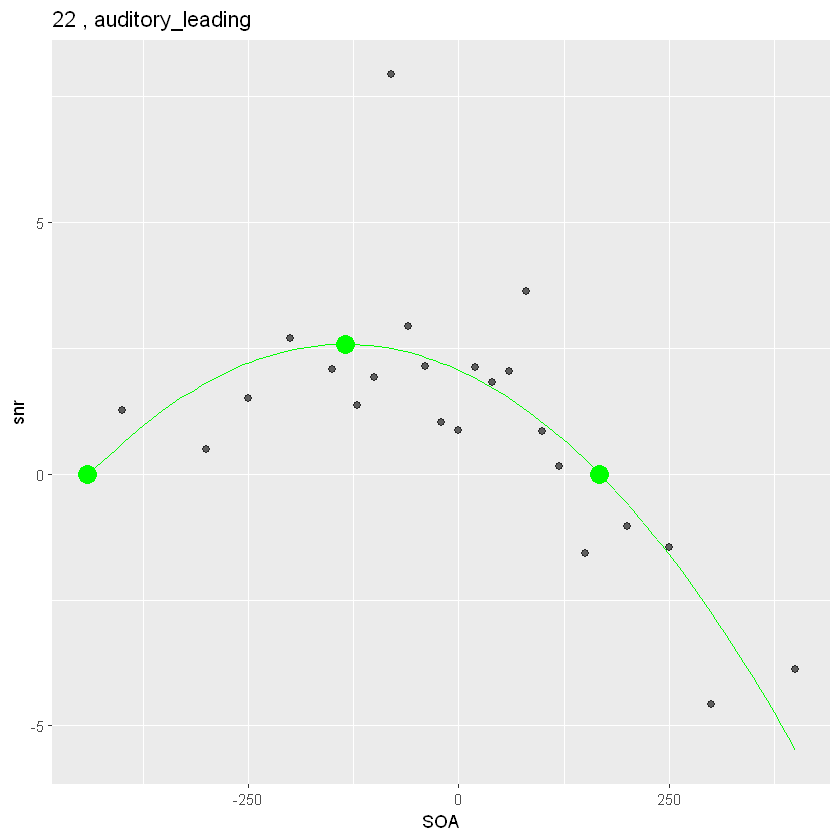

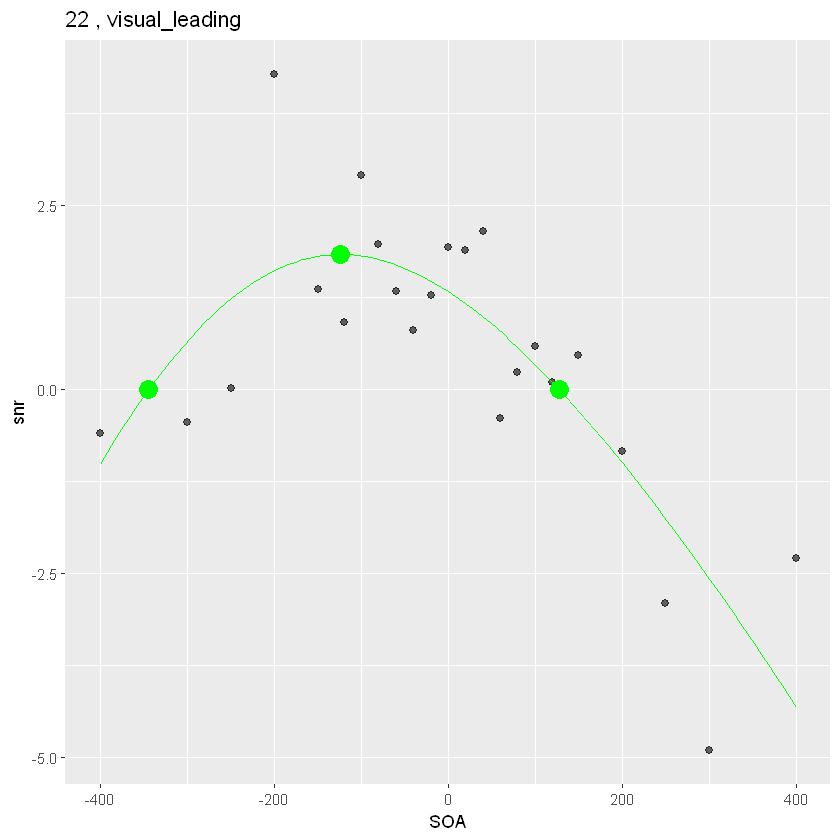

In [101]:
#==============================================================================#
# ESTIMATING LATENT SENSORY BIAS VIA SHAPE-CONSTRAINED ADDITIVE MODELS (SCAM)
# PURPOSE: Fit concave-constrained splines (with and without knot restrictions) 
#          to SNR profiles per participant and condition, identifying functions' 
#          roots (zeros) to quantify sensory bias thresholds.
#==============================================================================#

sigmoid_results <- data.frame()

for (participant in unique(df_stim$ID)) {
    for (condition in unique(df_stim$prior_stimulus)) {

        df_subset <- df_stim %>% filter(ID == participant, prior_stimulus == condition)


        model <- scam(snr ~ s(SOA, bs = "cv"), data = df_subset)
        ff <- function(SOA) {
              predict(model, data.frame(SOA = SOA))
            }

            max_snr_SOA <- optimize(ff, interval = range(df_subset$SOA), maximum = TRUE)$maximum
            max_snr_value <- ff(max_snr_SOA)
        
        if (max_snr_value<0){
            roots = c(max_snr_SOA, max_snr_SOA)
        } else {
            roots <- findZeros(ff(x)~x)
            roots <- roots$x
        }
        
            print(ggplot(df_subset, aes(x = SOA, y = snr)) +
                  # xlim(-600, 600) +
            ggtitle(glue('{participant} , {condition}')) +
            geom_point(size = 2, alpha = 0.6) + 
            geom_function(fun=ff, color='green') +
            geom_point(data = data.frame(x=roots, y=0), aes(x=x,y=y),size = 5, color='green') +
            geom_point(data = data.frame(x = max_snr_SOA, y = max_snr_value), aes(x = x, y = y), size = 5, color = 'green') 
                 )

            sigmoid_results <- rbind(sigmoid_results, data.frame(
                ID = participant,
                prior_stimulus = condition,
                positive_root = roots[2],
                negative_root = roots[1],
                max_snr_SOA = max_snr_SOA,
                max_snr_value = max_snr_value))       
    }
}

In [102]:
head(sigmoid_results)

,ID,prior_stimulus,positive_root,negative_root,max_snr_SOA,max_snr_value
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,204.35620,-243.77210,-50.95149,3.0570899
11,1,visual_leading,213.90340,-207.78860,33.53180,2.9206953
12,3,auditory_leading,-89.58885,-89.58885,-89.58885,-0.3912873
13,3,visual_leading,-22.82267,-22.82267,-22.82267,-0.1424872
14,4,auditory_leading,76.66480,-309.73460,-219.19452,1.1069275
15,4,visual_leading,105.49510,-308.20310,-154.48084,0.6975797


In [103]:
write_xlsx (sigmoid_results,"files/SJ_prior_stimulus_sensory_bias.xlsx")

In [104]:
# ---------------------------------------------------------
# Decision bias is quantified using the relative starting
# point (z/a). This parameter reflects the bias in the
# decision process toward one response boundary.
# ---------------------------------------------------------

df_summary <- df_resp %>%
  group_by(ID, prior_stimulus) %>%
  summarise(mean_Z = median(Z, na.rm = TRUE),
            .groups = "drop")

write_xlsx (df_summary,"files/SJ_prior_stimulus_decision_bias.xlsx")

###############################################################
## 3-3 Testing change in positive root

In [105]:
sigmoid_results <- read_xlsx("files/SJ_prior_stimulus_sensory_bias.xlsx")

In [106]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = positive_root[prior_stimulus == "visual_leading"] - positive_root[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,9.54720
3,66.76618
4,28.83030
5,-29.04020
7,47.33740
8,-54.32470


In [107]:
#summary
sigmoid_results %>% group_by(prior_stimulus) %>%  get_summary_stats(positive_root)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,positive_root,18,-89.589,314.571,193.488,105.606,241.447,135.841,92.253,172.849,96.159,22.665,47.819
visual_leading,positive_root,18,-22.823,324.061,213.758,130.284,257.173,126.889,95.138,190.227,94.352,22.239,46.920


In [108]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-54.325,66.766,22.97,8.066,40.821,32.755,25.302,17.379,32.091,7.564,15.958


In [109]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
8,-54.3247,TRUE,FALSE


In [110]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [111]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9227619,0.1446827


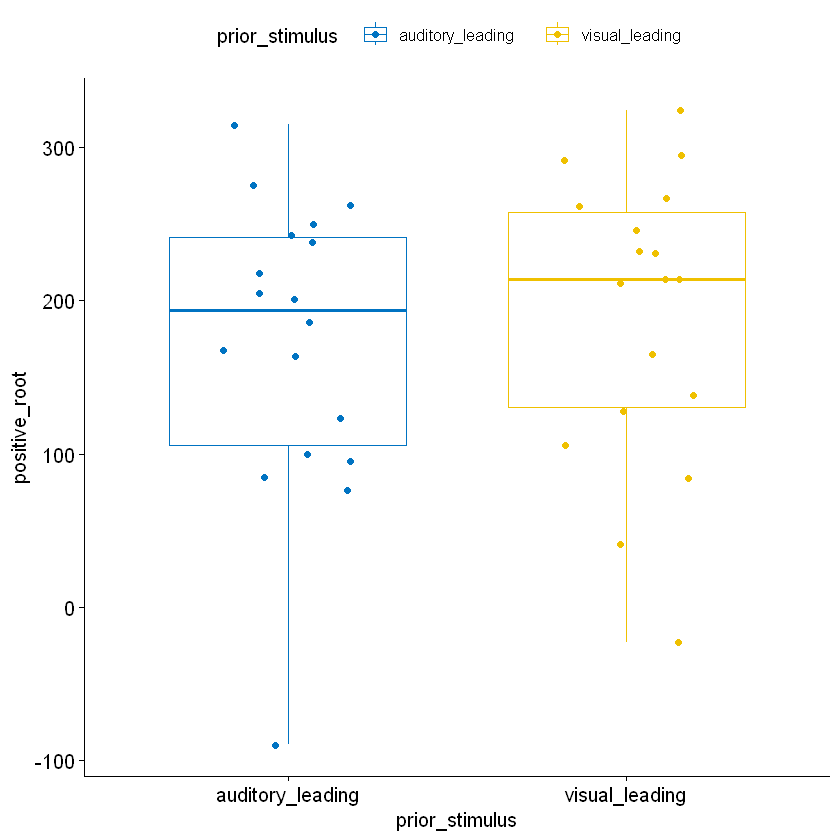

In [114]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_stimulus", y = "positive_root",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

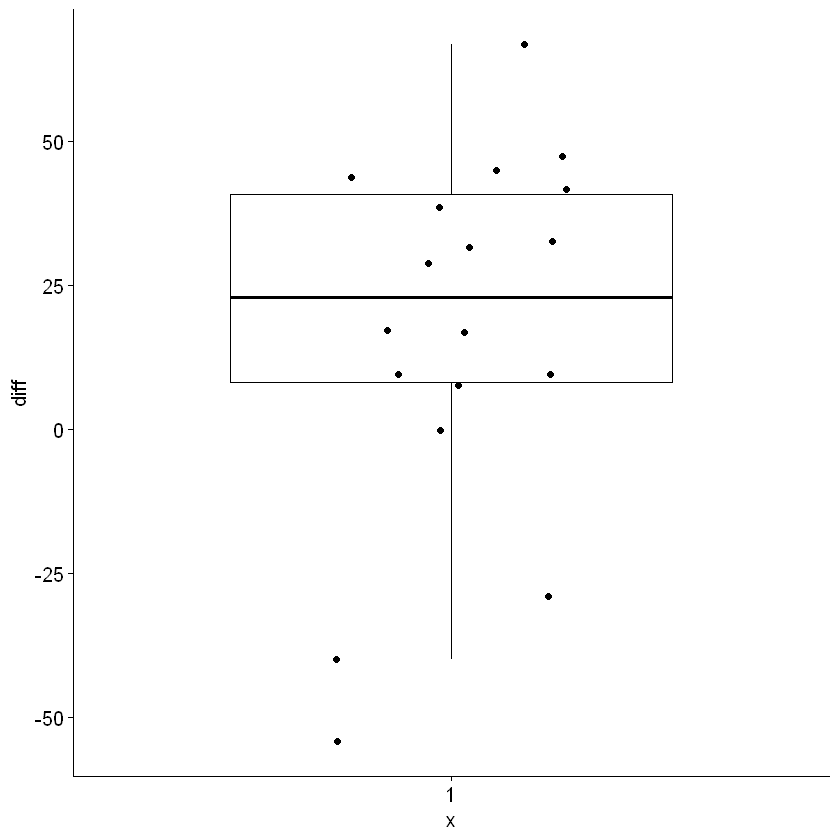

In [115]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [116]:
sigmoid_results %>% t_test(positive_root ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-17.37868,positive_root,auditory_leading,visual_leading,18,18,-2.297603,0.0346,17,-33.33696,-1.420391,T-test,two.sided


In [117]:
sigmoid_results %>% cohens_d(positive_root ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,positive_root,auditory_leading,visual_leading,-0.5415502,18,18,moderate


###############################################################
## 3-4 Testing change in negative root

In [118]:
sigmoid_results <- read_xlsx("files/SJ_prior_stimulus_sensory_bias.xlsx")

In [119]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = negative_root[prior_stimulus == "visual_leading"] - negative_root[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,35.98350
3,66.76618
4,1.53150
5,1.48370
7,39.92610
8,63.95270


In [120]:
#summary
sigmoid_results %>% group_by(prior_stimulus) %>%  get_summary_stats(negative_root)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,negative_root,18,-440.644,-89.589,-270.449,-303.699,-239.920,63.779,52.579,-261.602,76.689,18.076,38.136
visual_leading,negative_root,18,-344.580,-22.823,-276.840,-317.370,-207.909,109.461,72.284,-253.957,84.600,19.940,42.071


In [121]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-66.635,96.063,7.611,-32.04,37.206,69.246,52.074,7.645,44.649,10.524,22.203


In [122]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [123]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [124]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9708682,0.8138501


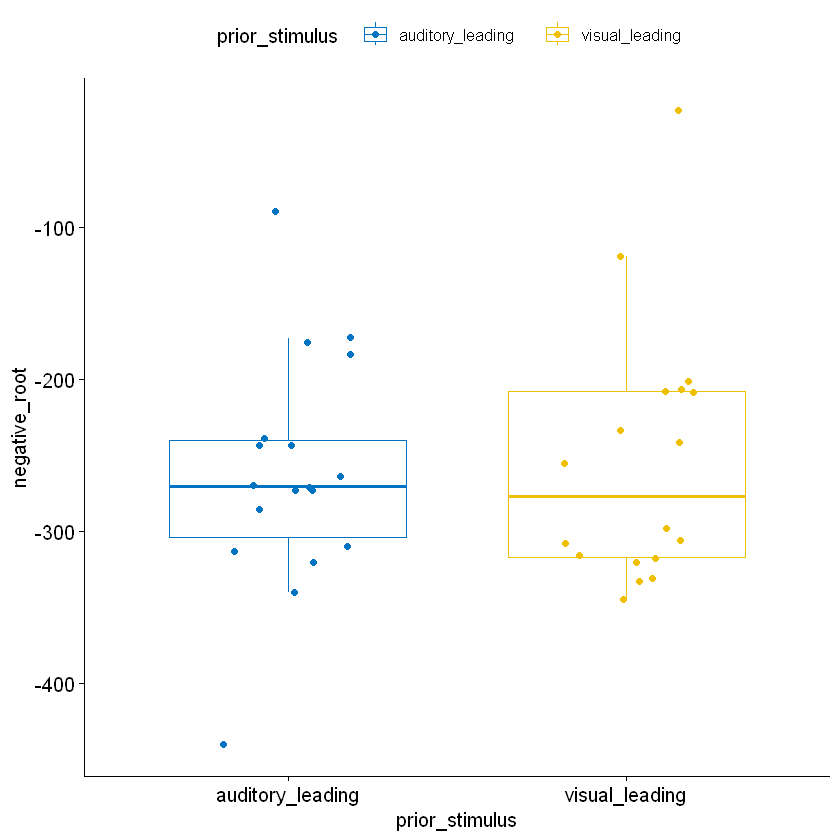

In [125]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_stimulus", y = "negative_root",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

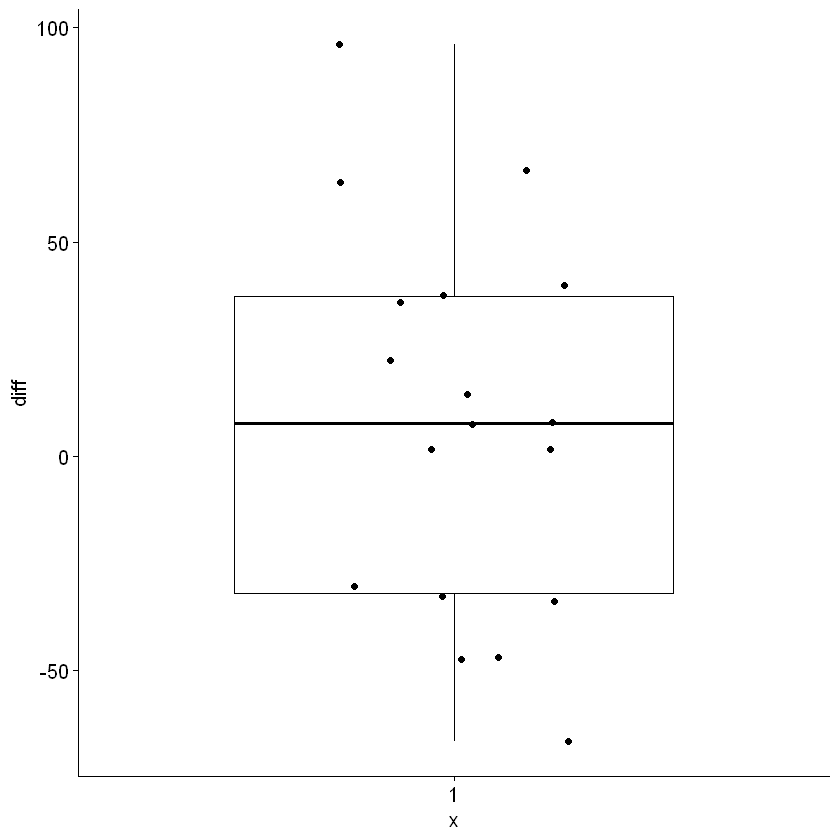

In [126]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [127]:
sigmoid_results %>% t_test(negative_root ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-7.644838,negative_root,auditory_leading,visual_leading,18,18,-0.7264339,0.477,17,-29.84809,14.55842,T-test,two.sided


In [128]:
sigmoid_results %>% cohens_d(negative_root ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,negative_root,auditory_leading,visual_leading,-0.1712221,18,18,negligible


###############################################################
## 3-5 Testing change in PSS

In [129]:
sigmoid_results <- read_xlsx("files/SJ_prior_stimulus_sensory_bias.xlsx")

In [130]:
sigmoid_results2 <- sigmoid_results %>% group_by(ID) %>% summarise(
    diff = max_snr_SOA[prior_stimulus == "visual_leading"] - max_snr_SOA[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(sigmoid_results2)

ID,diff
<dbl>,<dbl>
1,84.483293
3,66.766178
4,64.713682
5,35.819740
7,29.820899
8,4.814069


In [131]:
#summary
sigmoid_results %>% group_by(prior_stimulus) %>%  get_summary_stats(max_snr_SOA)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,max_snr_SOA,18,-219.195,52.161,-50.427,-77.901,-39.059,38.842,23.934,-61.187,55.623,13.110,27.661
visual_leading,max_snr_SOA,18,-154.481,43.899,-39.091,-75.393,-23.970,51.423,32.320,-46.675,51.756,12.199,25.738


In [132]:
sigmoid_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-83.999,84.483,10.136,5.289,29.322,24.033,21.313,14.512,38.452,9.063,19.122


In [133]:
#identify outlier
dd <- sigmoid_results2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
1,84.48329,TRUE,FALSE
3,66.76618,TRUE,FALSE
9,-83.99884,TRUE,TRUE
14,-43.37487,TRUE,FALSE


In [134]:
#Removing outliers data
sigmoid_results <- sigmoid_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
sigmoid_results2 <- sigmoid_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [135]:
# normality
sigmoid_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9321184,0.2361021


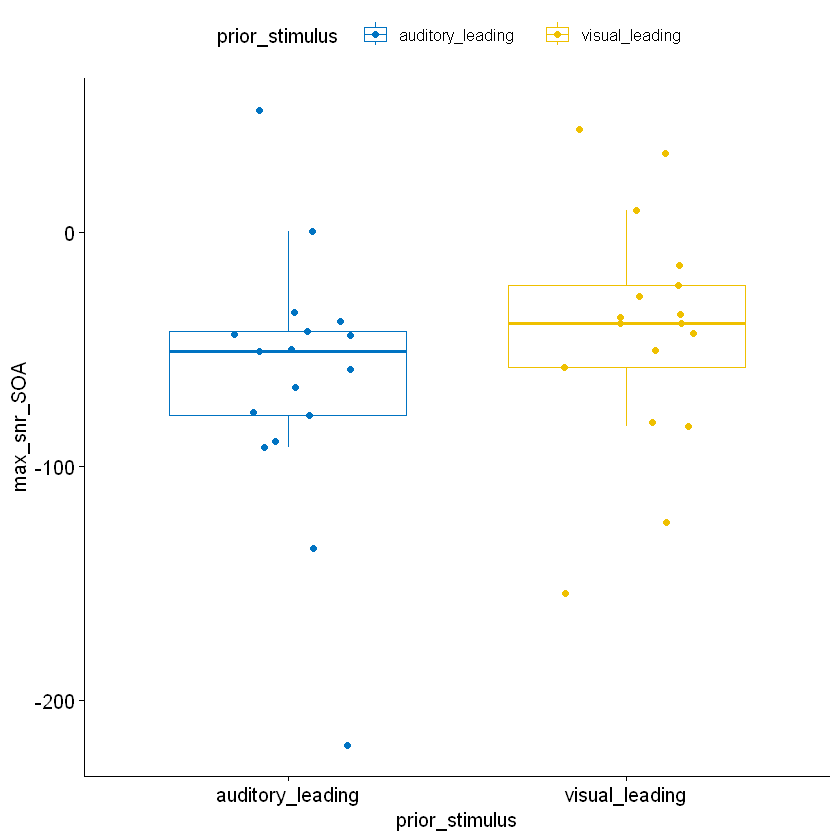

In [137]:
#plot
ggboxplot(
  sigmoid_results, x = "prior_stimulus", y = "max_snr_SOA",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

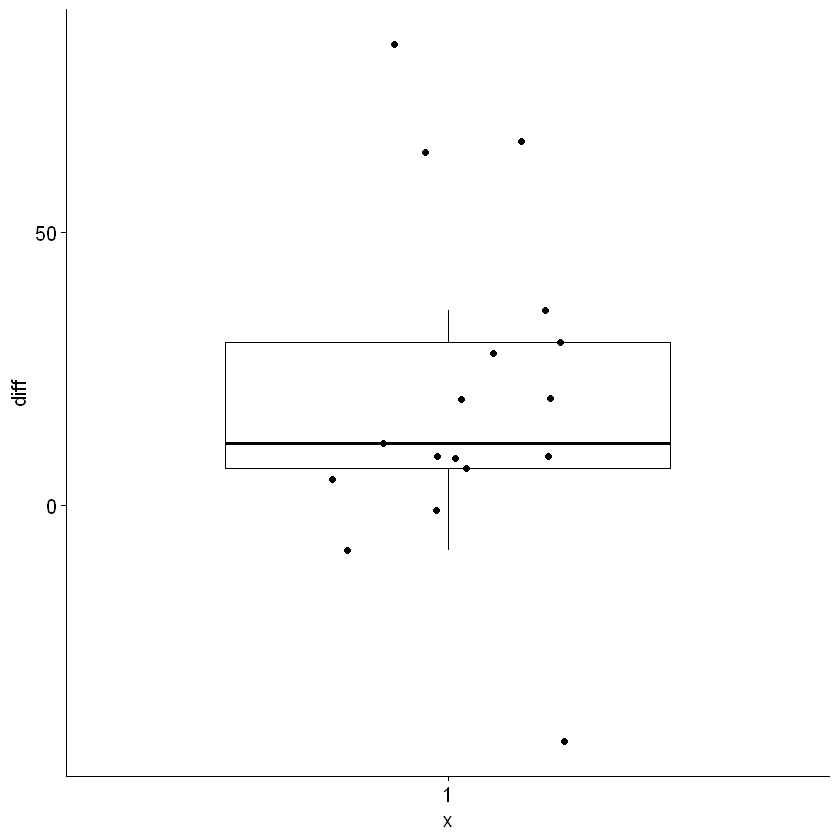

In [138]:
ggboxplot(
  sigmoid_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [139]:
sigmoid_results %>% t_test(max_snr_SOA ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-20.30659,max_snr_SOA,auditory_leading,visual_leading,17,17,-2.747305,0.0143,16,-35.97578,-4.637398,T-test,two.sided


In [140]:
sigmoid_results %>% cohens_d(max_snr_SOA ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,max_snr_SOA,auditory_leading,visual_leading,-0.6663193,17,17,moderate


###############################################################
## 3-6 Testing change in relative starting point

In [141]:
df_summary <- read_xlsx("files/SJ_prior_stimulus_decision_bias.xlsx")

In [142]:
df_summary2 <- df_summary %>% group_by(ID) %>% summarise(
    diff = mean_Z[prior_stimulus == "visual_leading"] - mean_Z[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(df_summary2)

ID,diff
<dbl>,<dbl>
1,0.29593843
3,-0.02277548
4,-0.19551990
5,0.02324786
7,0.04513680
8,0.06315440


In [143]:
df_summary %>% group_by(prior_stimulus) %>%  get_summary_stats(mean_Z)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,mean_Z,18,-0.119,0.452,0.207,0.094,0.323,0.228,0.175,0.203,0.162,0.038,0.080
visual_leading,mean_Z,18,-0.214,0.488,0.241,0.161,0.385,0.224,0.203,0.246,0.179,0.042,0.089


In [144]:
df_summary2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-0.196,0.362,0.003,-0.046,0.062,0.108,0.084,0.043,0.173,0.041,0.086


In [145]:
#identify outlier
dd <- df_summary2 %>% 
  identify_outliers(diff)
dd

ID,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
1,0.2959384,TRUE,FALSE
11,0.3615112,TRUE,FALSE
13,0.3615648,TRUE,FALSE
21,0.2759200,TRUE,FALSE


In [146]:
#Removing outliers data
df_summary <- df_summary %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")
df_summary2 <- df_summary2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "ID")

In [147]:
# normality
df_summary2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.8859016,0.03284915


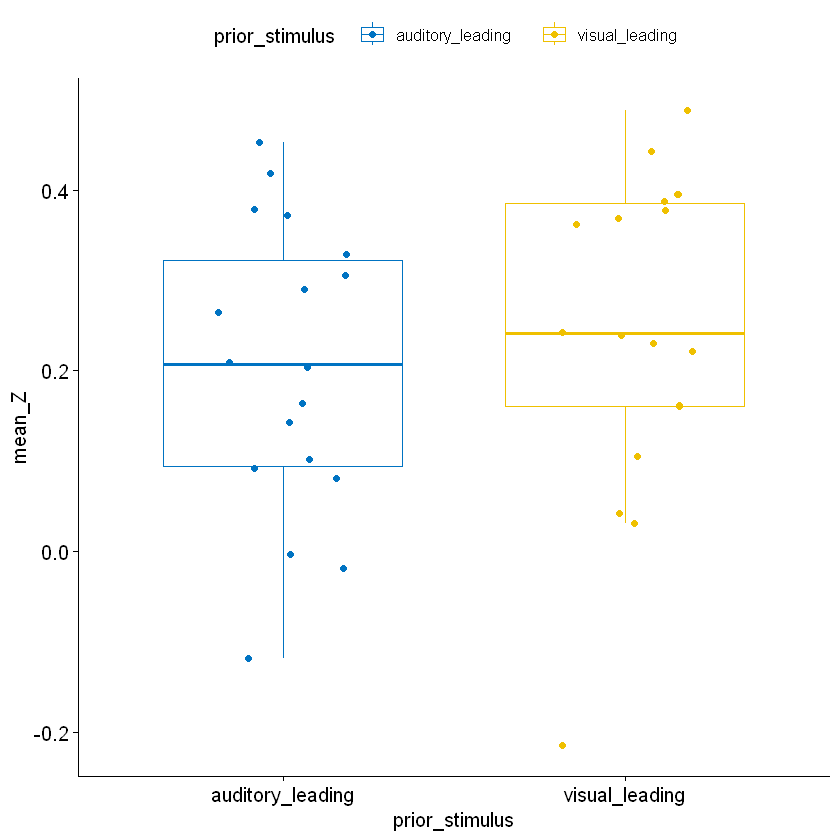

In [148]:
#plot
ggboxplot(
  df_summary, x = "prior_stimulus", y = "mean_Z",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

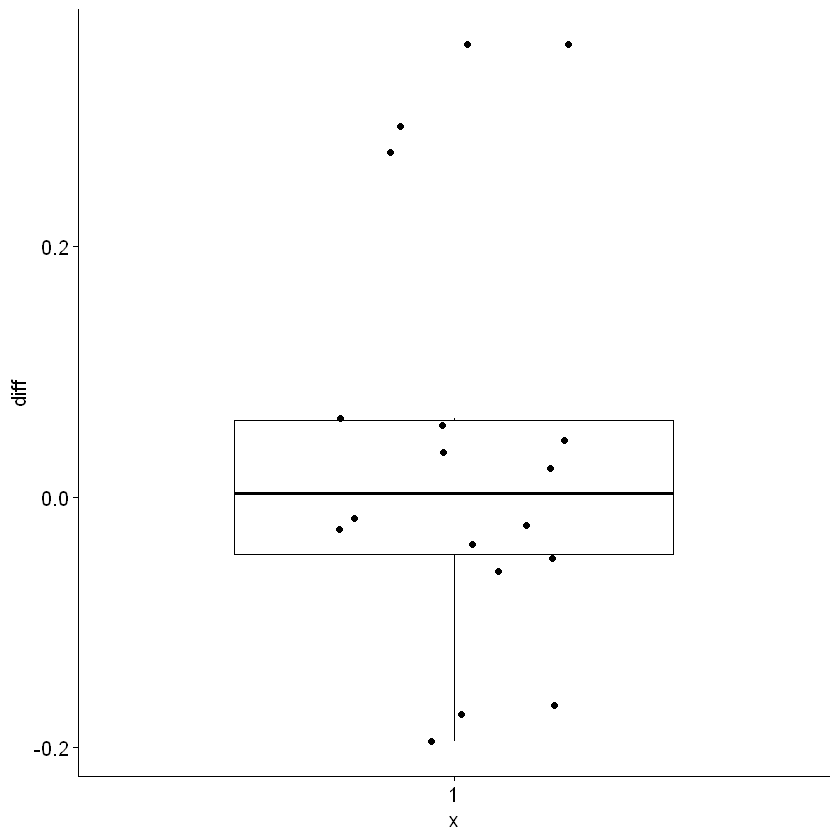

In [149]:
ggboxplot(
  df_summary2, y = "diff", palette = "jco", add = "jitter"
  )

In [150]:
df_summary %>% t_test(mean_Z ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-0.04297915,mean_Z,auditory_leading,visual_leading,18,18,-1.055001,0.306,17,-0.1289299,0.04297155,T-test,two.sided


In [151]:
df_summary %>% cohens_d(mean_Z ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,mean_Z,auditory_leading,visual_leading,-0.2486661,18,18,small


In [153]:
wilcox.test(df_summary$mean_Z[df_summary$prior_stimulus=='auditory_leading'], df_summary$mean_Z[df_summary$prior_stimulus=='visual_leading'], paired = TRUE, conf.int = TRUE)


	Wilcoxon signed rank exact test

data:  df_summary$mean_Z[df_summary$prior_stimulus == "auditory_leading"] and df_summary$mean_Z[df_summary$prior_stimulus == "visual_leading"]
V = 70, p-value = 0.5226
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
 -0.15096151  0.05175321
sample estimates:
(pseudo)median 
   -0.01728554 


###############################################################\
###############################################################
# 4- Plot statistical results

In [155]:
ddm_drift_zero_SJ_pre_stim <- read_excel("files/SJ_prior_stimulus_sensory_bias.xlsx")
ddm_drift_zero_SJ_pre_resp <- read_excel("files/SJ_prior_response_sensory_bias.xlsx")
ddm_bias_SJ_pre_resp<- read_excel("files/SJ_prior_response_decision_bias.xlsx")
ddm_bias_SJ_pre_stim<- read_excel("files/SJ_prior_stimulus_decision_bias.xlsx")

In [161]:
combined_df_SJ_pre_stim <- ddm_drift_zero_SJ_pre_stim %>%
  full_join(ddm_bias_SJ_pre_stim, by = c("ID", "prior_stimulus"))

combined_df_pre_resp_SJ <- ddm_drift_zero_SJ_pre_resp %>%
  full_join(ddm_bias_SJ_pre_resp, by = c("ID", "prior_response"))

In [162]:
stimulus_long <- combined_df_SJ_pre_stim %>%
  pivot_longer(cols = c(mean_Z,positive_root,negative_root,max_snr_SOA), names_to = "parameter", values_to = "value") %>%
  mutate(
    trial_leading = "prior_stimulus", 
    type = prior_stimulus         
  ) %>%
  select(ID, trial_leading, type, parameter, value)

response_long <- combined_df_pre_resp_SJ %>%
  pivot_longer(cols = c(mean_Z,positive_root,negative_root,max_snr_SOA), names_to = "parameter", values_to = "value") %>%
  mutate(
    trial_leading = "prior_response", 
    type = prior_response        
  ) %>%
  select(ID, trial_leading, type, parameter, value)

In [163]:
combined_results <- bind_rows(stimulus_long, response_long) %>%
  arrange(ID, trial_leading, type, parameter) 

In [29]:
combined_results <- combined_results %>%
  filter(!(ID == "9" & trial_leading == "prior_stimulus" & parameter == "max_snr_SOA"))

In [167]:
combined_results <- combined_results %>%
  mutate(type = recode(type,
    "visual_leading" = "visual leading",
    "auditory_leading" = "auditory leading",
    "synchrony" = "synchronous response",
    "asynchrony" = "asynchronous response"
  ))
combined_results <- combined_results %>%
  mutate(trial_leading = recode(trial_leading,
    "prior_stimulus" = "Prior stimulus",
    "prior_response" = "Prior response"))

combined_results <- combined_results %>%
  mutate(parameter = recode(parameter,
    "mean_Z" = "Decisional~Bias~(DB)",
    "negative_root" = "Negative~Sensory~Bias~(NSB)",
    "positive_root" = "Positive~Sensory~Bias~(PSB)",
           'max_snr_SOA'="PSS[DDM]"                
                           )
        )

In [31]:
d <- combined_results %>% group_by(trial_leading,parameter,type) %>% summarise(mean=mean(value), sd=sd(value)/sqrt(n())) %>% ungroup()

`summarise()` has grouped output by 'trial_leading', 'parameter'. You can override using the `.groups` argument.


In [168]:
stat_test <- combined_results %>%
  group_by(trial_leading, parameter) %>%
  # Explicitly call t_test from rstatix
  rstatix::t_test(value ~ type, paired = TRUE) %>%
  rstatix::add_significance()

In [34]:
stat_test <- stat_test %>%
  add_xy_position(x = "trial_leading", dodge = 0.8)

In [35]:
stat_test['y.position'] <- c(.7,-18,80,432,.6,10,90,430)

Warning message in geom_errorbar(data = d, aes(group = type, fill = c(), y = c(), :
"Ignoring unknown aesthetics: fill"


png 
  2

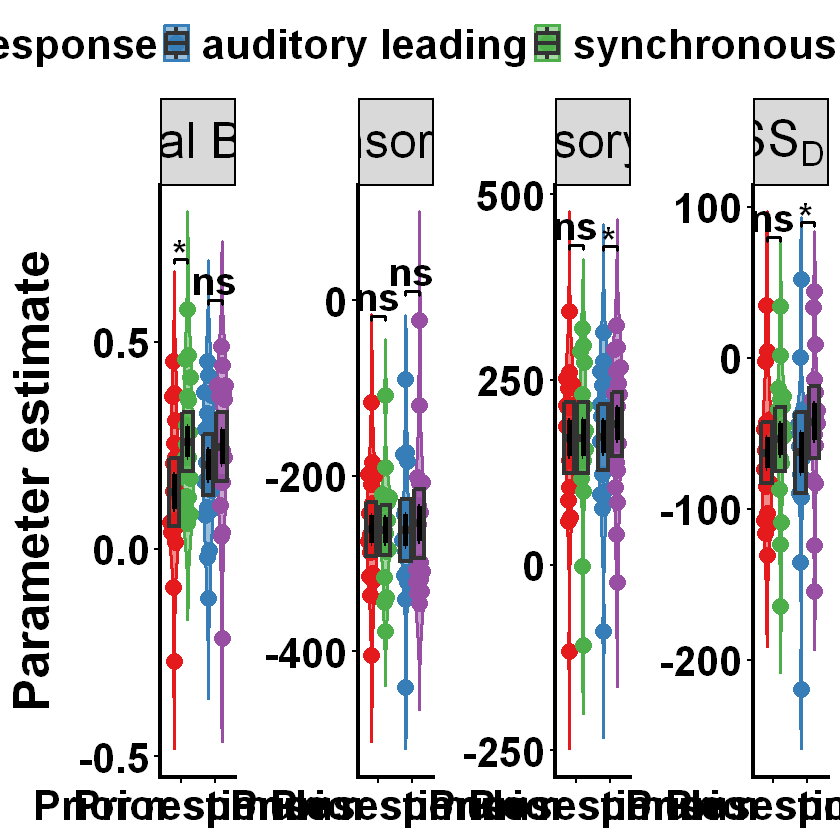

In [36]:
pdf(file="figures/SJ_DDM_params.pdf", width = 30, height = 8)
resfig <- ggplot(data=combined_results, mapping=aes(x=trial_leading, y=value)) +
    # Increased linewidth to 1 and alpha to 0.5 for a bolder, more vivid violin look
    geom_violin(trim = FALSE, alpha=.5, width=.6, scale='width', position=position_dodge(.8), aes(colour=type, fill = type), linewidth=1) +
    # Increased alpha to 1 and stroke to 1.2 so individual points stand out sharply
    geom_quasirandom(dodge.width=.8, aes(colour=type), width=.13, shape=16, stroke=1.2, size=4, alpha=1) +
    # Increased boxplot linewidth to 1.2 for better visibility inside the violin
    geom_boxplot(alpha=.8, data=d, aes(y=c(), ymin=mean-sd*1.96, lower=mean-sd*1.96, middle=mean, upper=mean+sd*1.96, ymax=mean+sd*1.96, fill=type),
                 stat = "identity", position=position_dodge(.8), width=0.6, linewidth = 1.2) +
    # Increased errorbar linewidth to 1.5 to make the SD bounds extra bold
    geom_errorbar(data=d, aes(group=type, fill=c(), y=c(), ymin=mean-sd, ymax=mean+sd), position=position_dodge(.8), width=.1, linewidth=1.5) +
    # Significance bars kept bold as originally specified
    stat_pvalue_manual(stat_test, label = "p.adj.signif", tip.length = 0.01, size = 8.5, bracket.size = 1.1, fontface = "bold") +
    facet_wrap(vars(parameter), scales='free_y', nrow=1, labeller = label_parsed) + 
    labs(x = NULL, y = "Parameter estimate", color = NULL, fill = NULL) + 
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set1") +

    # Clean publication theme with enhanced line thickness
    theme_classic(base_size = 14) +
    theme(
      axis.title.x     = element_text(face = "bold", size = 18, margin = margin(t = 10)),
      axis.title.y     = element_text(face = "bold", size = 30, margin = margin(r = 12)),
      axis.text.x      = element_text(face = "bold", size = 25, color = "black"),
      axis.text.y      = element_text(face = "bold", size = 25, color = "black"),
      strip.text       = element_text(face = "bold", size = 30, color = "black"),
      # Made the facet frame borders bolder (linewidth = 1)
      strip.background = element_rect(fill = "gray85", color = "black", linewidth = 1),
      legend.title     = element_text(face = "bold", size = 25),
      legend.text      = element_text(face = "bold", size = 25),
      legend.position  = "top",
      # Made main axis lines bolder (linewidth = 1.2)
      axis.line        = element_line(linewidth = 1.2),
      panel.spacing    = unit(1.2, "lines")
    )
resfig
dev.off()
resfig